# 05 — Theo dõi từng bước tách QRS và T loops trên dữ liệu thật

Notebook này giải thích **vì sao các mốc được chọn và cách các mẫu XYZ tạo thành loop**, bằng một recording xuyên suốt. Mặc định là HC `patient104/s0306lre`; mọi số trên hình được tính từ recording này, không vẽ một nhịp giả.

Ý tưởng xuyên suốt:

**Một recording có nhiều nhịp → chọn các nhịp qua QC dữ liệu → một median beat → chọn hai đoạn thời gian → nối điểm XYZ trong mỗi đoạn → hai loop.**

Điện thế theo thời gian, magnitude, vận tốc và loop là những cách biểu diễn khác nhau của dữ liệu liên quan. Biên phân đoạn là ước lượng theo thuật toán notebook 04, chưa phải annotation chuẩn. Đặc biệt, T-on/end theo tiếp tuyến là một quy ước đo; không nhất thiết bao hết phần đuôi nhỏ của sóng.

Đọc lần lượt từ Bước 1. Mỗi bước có **đầu vào**, **thao tác**, **đầu ra** và hướng dẫn đọc biểu đồ. Các hình và bảng đã được lưu sẵn. Muốn đổi record, sửa `RECORD_ID`, chọn kernel PTB VCG, rồi Run All.

## Chuẩn bị dữ liệu trên máy này
Chạy cell dưới một lần mỗi phiên. Dữ liệu PTB được tải từ GitHub Releases nếu còn thiếu.
Notebook 06–09 tự tạo các đầu vào phụ thuộc còn thiếu; lần đầu có thể chạy lâu.
Hướng dẫn và dung lượng: xem `README.md` và `docs/REPRODUCIBILITY.md`.

In [1]:
from pathlib import Path
import os, sys

NOTEBOOK_ROOT=next((p for p in [Path.cwd(),Path.cwd()/"VCG",*Path.cwd().parents]
                    if (p/"project_setup.py").is_file()),None)
if NOTEBOOK_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục vcg hoặc vcg/VCG.")
NOTEBOOK_ROOT=NOTEBOOK_ROOT.resolve()
if str(NOTEBOOK_ROOT) not in sys.path: sys.path.insert(0,str(NOTEBOOK_ROOT))
# Các đường dẫn tương đối và unittest bên dưới dùng cùng thư mục project.
os.chdir(NOTEBOOK_ROOT)
from project_setup import prepare_notebook
prepare_notebook(5)

Đầu vào Notebook 05 đã sẵn sàng.


## Các hàm nền dùng chung với notebook 04

Ba module bên cạnh notebook cung cấp tiền xử lý có điều kiện, pipeline và kiểm chứng. Mở notebook từ thư mục project, chọn PTB VCG; restart kernel trước Run All để tránh dùng module đã cache. Thu gọn ô import và đọc từ Bước 1.

In [2]:
# %pip install numpy scipy pandas matplotlib scikit-learn wfdb
from pathlib import Path
from dataclasses import asdict, replace
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, savgol_filter, butter, sosfiltfilt
from scipy.ndimage import uniform_filter1d, percentile_filter, binary_closing
from sklearn.decomposition import PCA
from vcg_preprocessing import (Config, legacy_config, design_morphology_fir,
    analyze_powerline_noise, decide_notch, assess_input_quality,
    filter_frequency_response, welch_xyz)
from vcg_pipeline import (FEATURE_NAMES, preprocess_xyz, ms_samples, odd_window, robust_sigma, load_xyz, detect_qrs_anchors, spatial_speed, flattest_pq, representative_beat, quiet_boundary, delineate_loops, apply_manual_boundaries, cut_loop, project_pca, extract_features, process_record, qc_row, plot_detection, plot_delineation, plot_loops)
from vcg_preprocessing_evaluation import (compare_preprocessing_configs,
    powerline_diagnostic_table, plot_filter_responses, plot_preprocessing_diagnostics,
    plot_median_config_comparison, plot_3d_config_comparison)
CFG=Config()


In [3]:
from IPython.display import display
from matplotlib.patches import Rectangle

DATA_ROOT = Path('content/ptbdb/physionet.org/files/ptbdb/1.0.0')
RECORD_ID = 'patient104/s0306lre'
CFG = Config(seconds=30.0)
QRS_COLOR, T_COLOR = '#059669', '#ea580c'
XYZ_COLORS = ['#2563eb', '#7c3aed', '#64748b']
plt.rcParams.update({'font.family':'DejaVu Sans', 'figure.dpi':105, 'font.size':10})

def finish(fig):
    plt.show()
    plt.close(fig)

def draw_xyz(ax, time, xyz, label_prefix=''):
    for j,name in enumerate('XYZ'):
        ax.plot(time,xyz[:,j],color=XYZ_COLORS[j],lw=1.3,label=label_prefix+name)
    ax.set_ylabel('Điện thế (mV)')
    ax.grid(alpha=.2)

def shade(ax, time, bounds):
    for a,z,color,label in [('qrs_on','qrs_off',QRS_COLOR,'QRS candidate'),('t_on','t_off',T_COLOR,'T candidate')]:
        if bounds[a] is not None and bounds[z] is not None:
            ax.axvspan(time[bounds[a]],time[bounds[z]],color=color,alpha=.16,label=label)
            ax.axvline(time[bounds[a]],color=color,ls=':',lw=1)
            ax.axvline(time[bounds[z]],color=color,ls=':',lw=1)

if not DATA_ROOT.is_dir():
    raise FileNotFoundError('Mở notebook từ thư mục project hoặc sửa DATA_ROOT.')

## Bước 1 — Một hàng dữ liệu XYZ có nghĩa gì

**Đầu vào:** record PTB gồm header và tín hiệu. Chỉ ba kênh Frank `vx/vy/vz` được đọc.

**Thao tác:** đọc ba cột điện thế đồng thời. Mỗi hàng ứng với một thời điểm; ba giá trị trên hàng đó tạo thành một điểm $(X,Y,Z)$ trong không gian điện thế.

**Đầu ra:** `raw_xyz` có shape `(số mẫu, 3)` và tần số lấy mẫu `fs`. Ở 1000 Hz, hai hàng liên tiếp cách nhau 1 ms.

Ví dụ, hàng có X=0.2, Y=0.3, Z=0.1 mV là điểm (0.2, 0.3, 0.1). Điểm này không phải vị trí giải phẫu trong tim; các tọa độ đều là điện thế. Bảng dưới dùng số thật từ recording.

In [4]:
raw = load_xyz(DATA_ROOT / RECORD_ID, CFG.seconds)
raw_xyz, fs = raw['xyz'], raw['fs']
print('Record:', RECORD_ID, '| diagnosis:', raw['diagnosis'])
print('Channels đã đọc:', raw['channels'])
print('Shape:', raw_xyz.shape, '| fs:', fs, 'Hz | Δt:', 1000/fs, 'ms')
rows = np.arange(int(2*fs), int(2*fs)+5)
display(pd.DataFrame({'chỉ số mẫu':rows,'thời gian recording (s)':rows/fs,
                      'X (mV)':raw_xyz[rows,0],'Y (mV)':raw_xyz[rows,1],'Z (mV)':raw_xyz[rows,2]}))

Record: patient104/s0306lre | diagnosis: Healthy control
Channels đã đọc: ['vx', 'vy', 'vz']
Shape: (30000, 3) | fs: 1000.0 Hz | Δt: 1.0 ms


,chỉ số mẫu,thời gian recording (s),X (mV),Y (mV),Z (mV)
0,2000,2.000,-0.0750,-0.3965,-0.0605
1,2001,2.001,-0.0820,-0.4020,-0.0575
2,2002,2.002,-0.0875,-0.4085,-0.0560
3,2003,2.003,-0.0955,-0.4125,-0.0530
4,2004,2.004,-0.1030,-0.4145,-0.0500


### Bước 1A — Kiểm tra chất lượng XYZ trước lọc

**Đầu vào:** XYZ gốc. **Thao tác:** kiểm tra hữu hạn, đoạn cả ba trục gần như hằng, đột biến đơn lẻ, vùng gần rail ADC danh nghĩa PTB, PSD tần số thấp/cao và thay đổi baseline giữa các khối.

**Đầu ra:** dictionary QC/mask để xem và dùng kiểm tra beat. Đỉnh QRS dốc hoặc hình thái MI khác không tự bị coi là nhiễu. Thành phần thấp có thể là drift/ST/T/chuyển động; được ghi để review, không tự high-pass. Rail 15,5 mV là cấu hình nghi ngờ gần giới hạn PTB danh nghĩa, không phải chuẩn chung.

Mỗi hàng hình là X/Y/Z, trục ngang Hz, trục dọc PSD mV²/Hz. Cột trái toàn dải, phải phóng to 50 Hz. PSD quanh 50 Hz cao chưa xác nhận nhiễu điện lưới.

Input QC: Chưa có lỗi dữ liệu rõ theo heuristic


,axis,baseline_center_range_mV,low_frequency_density,high_frequency_density
0,X,0.53025,0.001820,4.951320e-09
1,Y,1.36600,0.012081,1.025751e-08
2,Z,0.30250,0.000754,6.944500e-09


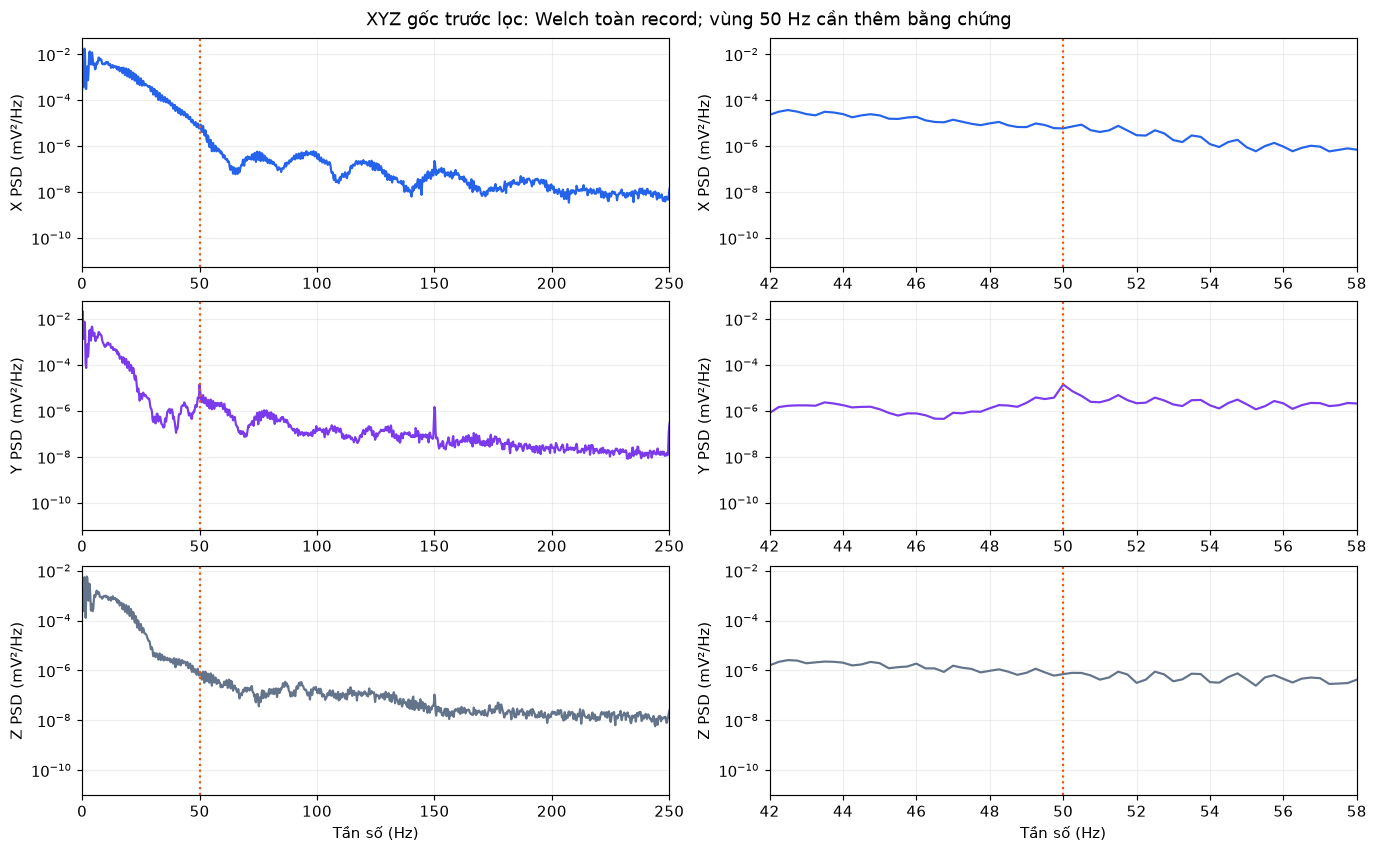

In [5]:
initial_quality=assess_input_quality(raw_xyz,fs,CFG)
print('Input QC:',initial_quality['flags'] or 'Chưa có lỗi dữ liệu rõ theo heuristic')
display(pd.DataFrame({'axis':list('XYZ'),
    'baseline_center_range_mV':initial_quality['baseline_center_range_mV'],
    'low_frequency_density':initial_quality['low_frequency_density'],
    'high_frequency_density':initial_quality['high_frequency_density']}))
f=initial_quality['psd_frequency_hz'];p=initial_quality['psd_density']
fig,axes=plt.subplots(3,2,figsize=(13,8),layout='constrained')
for j,name in enumerate('XYZ'):
    for col in range(2):
        axes[j,col].semilogy(f,np.maximum(p[:,j],1e-20),color=XYZ_COLORS[j])
        axes[j,col].axvline(CFG.notch_hz,color='#ea580c',ls=':')
        axes[j,col].set(xlim=(0,250) if col==0 else (42,58),ylabel=name+' PSD (mV²/Hz)')
        axes[j,col].grid(alpha=.2)
        if j==2:axes[j,col].set_xlabel('Tần số (Hz)')
fig.suptitle('XYZ gốc trước lọc: Welch toàn record; vùng 50 Hz cần thêm bằng chứng')
finish(fig)

## Bước 2 — FIR giữ băng thông và Notch có điều kiện

**Đầu vào:** XYZ gốc, được giữ nguyên; chất lượng và PSD được đánh giá trước lọc.

**Thao tác:** FIR pha tuyến tính 401 hệ số, Kaiser β=8, cutoff thiết kế 175 Hz tại fs=1000 Hz, áp dụng hai chiều. Mục tiêu kiểm chứng là giữ tốt đến 150 Hz và giảm thành phần trên 190–200 Hz. 175 Hz là điểm thiết kế, không có nghĩa biên độ mọi tần số đến 175 Hz được giữ nguyên.

Sau đó kiểm tra Notch theo từng trục: PSD Welch, độ nổi bật đỉnh hẹp và persistence theo các cửa sổ 4 giây. Có thêm fit harmonic trên các đoạn ít magnitude/ít slope, tránh coi mọi khoảng giữa QRS là yên. Timestamp của các đoạn rời rạc được giữ nguyên, không nối chúng rồi coi là tín hiệu liên tục.

- `noise_detected`: đủ bằng chứng theo heuristic; `auto` cho phép Notch riêng trục đó.
- `noise_not_detected`: không có đủ bằng chứng nghi nhiễu; giữ trục chưa Notch.
- `inconclusive`: thiếu/mâu thuẫn bằng chứng; giữ trục chưa Notch và gắn cờ review.

Ngưỡng 8 dB, persistence 60%, độ tập trung phổ và kiểm tra quiet đều là cấu hình nghiên cứu chưa được xác thực trên cohort. Vượt 8 dB một mình không bật Notch. Notch IIR Q=50 chạy hai chiều; `on/off` chỉ là chế độ thí nghiệm. Q=50 chưa được chứng minh tối ưu.

**Đầu ra:** morphology và nhánh Butterworth bậc 3, 5–30 Hz chỉ dùng detector. Không đo loop từ nhánh detector. Không tự thêm high-pass morphology; 0,5 Hz chỉ là tùy chọn đối chiếu với cảnh báo ST/T. FIR từ chối fs khác 1000 Hz thay vì âm thầm đổi thiết kế.

Hình ba cột giữ cách đọc cũ: gốc xám, morphology xanh, detector cam. Bảng RMS sai khác không tự là mức nhiễu đã loại; PSD/bảng loop phía dưới giúp kiểm tra đồng thời giảm thành phần nghi nhiễu và bảo toàn hình dạng.

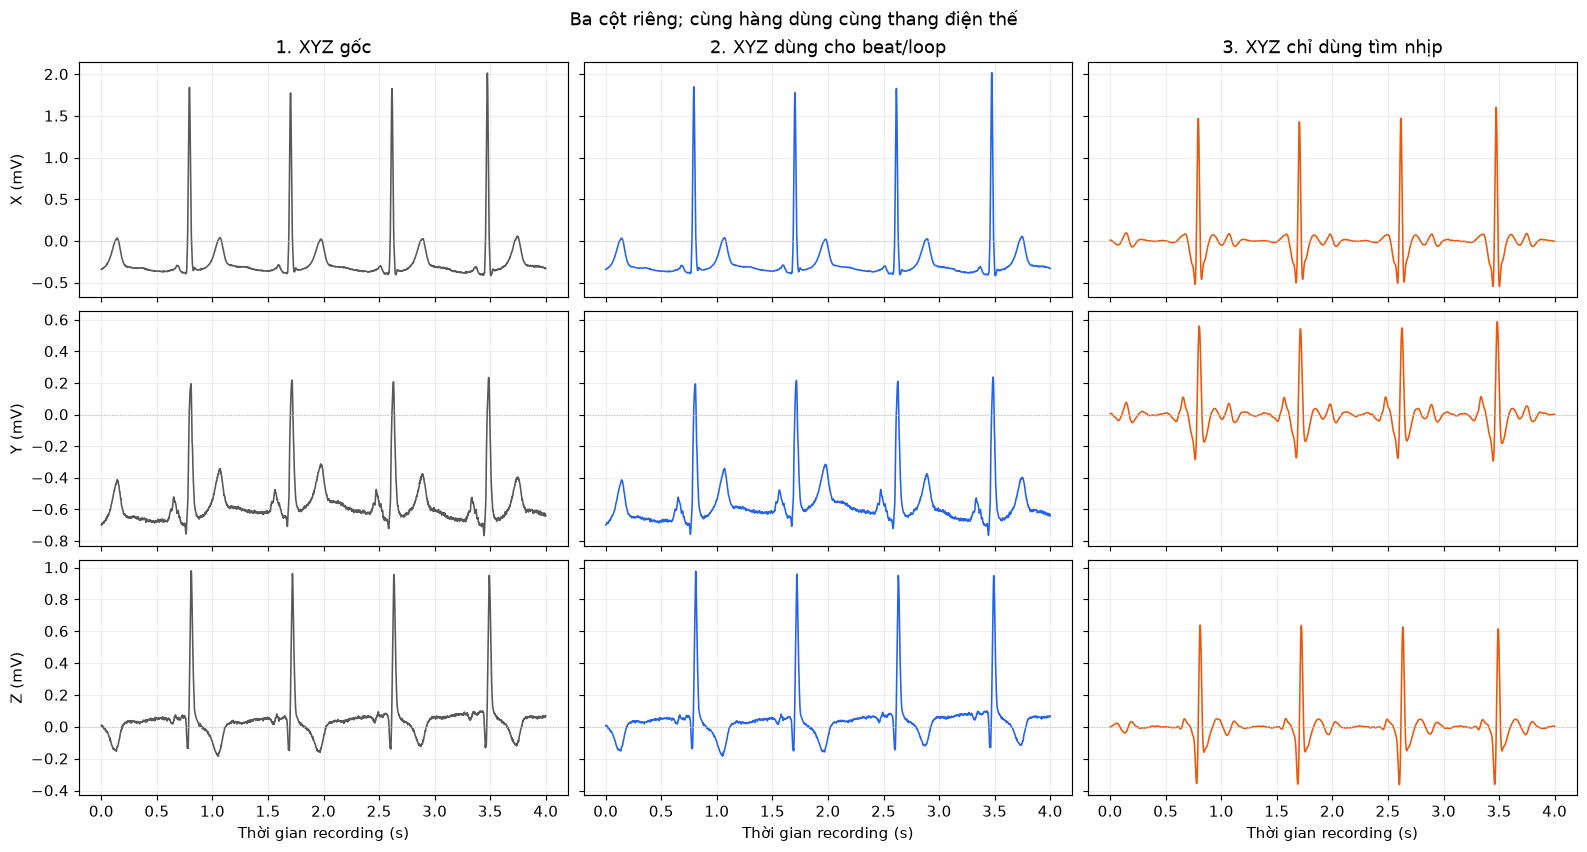

,Trục,RMS sai lệch gốc–morph (µV),Biên độ max–min tín hiệu gốc (mV)
0,X,1.426930,2.4295
1,Y,1.945674,1.0015
2,Z,1.658176,1.1625


In [6]:
morph, detection_xyz, preprocessing = preprocess_xyz(raw_xyz, fs, CFG, return_diagnostics=True)
n_show = min(len(morph), int(4*fs))
record_time = np.arange(n_show)/fs

# Vẽ riêng ba tín hiệu để đường gốc không bị đường đã lọc che.
fig,axs = plt.subplots(3,3,figsize=(15,8),sharex=True,sharey='row',layout='constrained')
branches = [(raw_xyz,'.35','1. XYZ gốc'),
            (morph,'#2563eb','2. XYZ dùng cho beat/loop'),
            (detection_xyz,'#ea580c','3. XYZ chỉ dùng tìm nhịp')]
for j,name in enumerate('XYZ'):
    for col,(signal,color,title) in enumerate(branches):
        ax = axs[j,col]
        ax.plot(record_time,signal[:n_show,j],color=color,lw=1.1)
        ax.axhline(0,color='.75',lw=.7,ls=':')
        ax.grid(alpha=.2)
        if j == 0: ax.set_title(title)
        if col == 0: ax.set_ylabel(name+' (mV)')
        if j == 2: ax.set_xlabel('Thời gian recording (s)')
fig.suptitle('Ba cột riêng; cùng hàng dùng cùng thang điện thế')
finish(fig)

delta = morph[:n_show]-raw_xyz[:n_show]
display(pd.DataFrame({
    'Trục':list('XYZ'),
    'RMS sai lệch gốc–morph (µV)':np.sqrt(np.mean(delta**2,axis=0))*1000,
    'Biên độ max–min tín hiệu gốc (mV)':np.ptp(raw_xyz[:n_show],axis=0)
}))

### Bước 2A — Kiểm chứng đáp ứng FIR và Notch thực tế

**Đầu vào:** hệ số bộ lọc. **Thao tác:** `freqz` tính một chiều và bình phương gain để tính hai chiều. **Đầu ra:** gain tuyến tính và dB; bảng đo dải 0–150 Hz, stopband 190–200 Hz, cutoff và Notch. Hai chiều không trễ pha nhưng vẫn thay đổi biên độ/hiệu ứng mép.

Các con số này kiểm chứng bộ lọc tuyến tính, không chứng minh phân đoạn hay chẩn đoán đúng. Notch có thể làm mất cả thành phần tim thật gần 50 Hz; vì vậy cần quyết định có điều kiện.

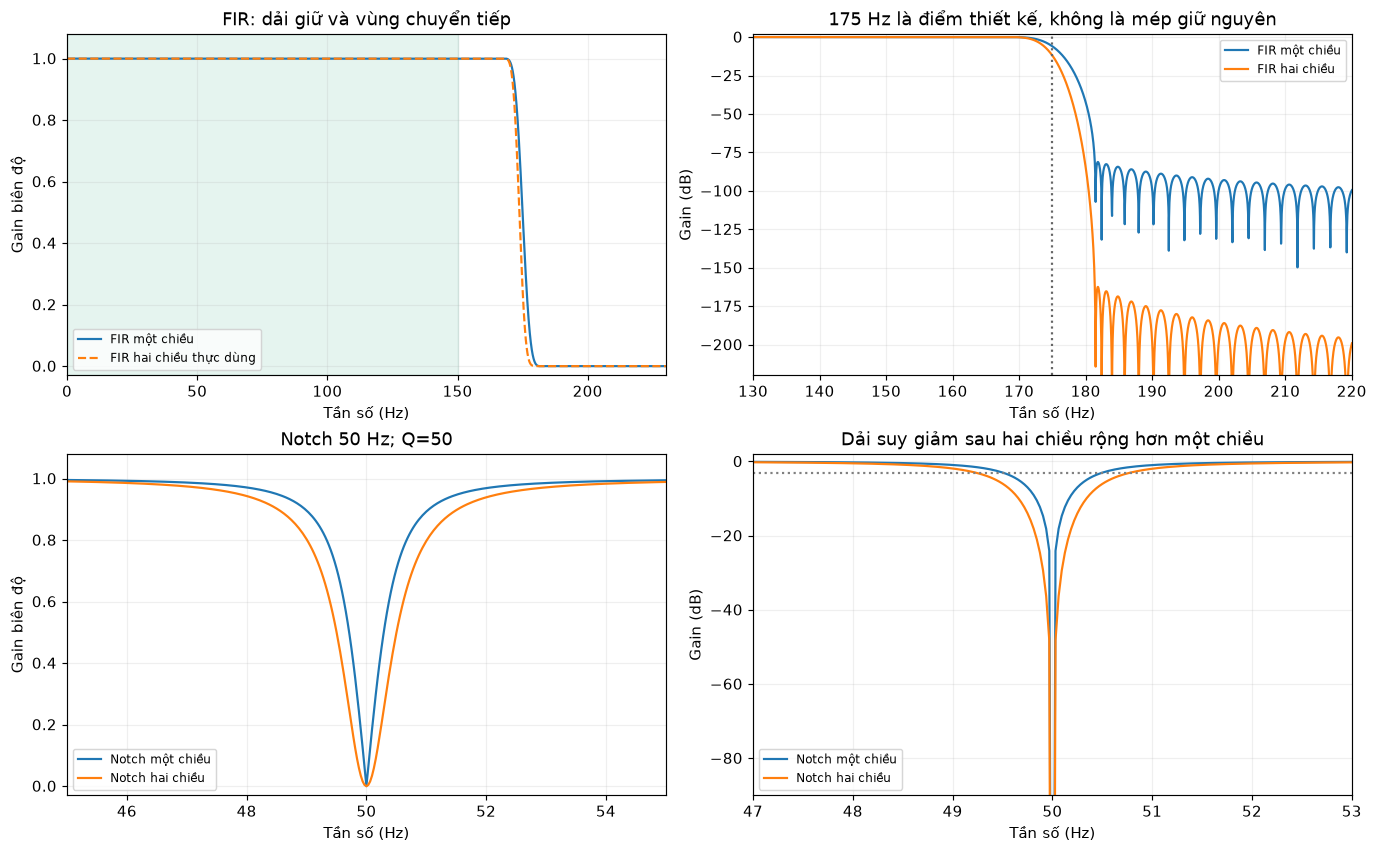

,measure,value,unit
0,FIR hai chiều: sai lệch gain lớn nhất 0–150 Hz,0.000478,dB
1,FIR hai chiều: gain cao nhất 190–200 Hz,-177.675907,dB
2,Notch hai chiều: độ rộng mức ≤ −3 dB,1.531250,Hz


,frequency_hz,fir_one_pass_db,fir_two_pass_db,notch_one_pass_db,notch_two_pass_db
1600,50.0,-0.000005,-0.000010,-264.356707,-300.000000
4800,150.0,-0.000057,-0.000113,-0.000213,-0.000425
5600,175.0,-6.020564,-12.041128,-0.000138,-0.000275
6080,190.0,-99.215354,-198.430707,-0.000109,-0.000218
6400,200.0,-99.475976,-198.951952,-0.000094,-0.000188


In [7]:
fig,response_table=plot_filter_responses(fs,CFG);finish(fig)
passband=response_table[response_table.frequency_hz<=CFG.fir_preserve_hz]
stopband=response_table[response_table.frequency_hz.between(*CFG.fir_stopband_hz)]
notch_band=response_table[response_table.notch_two_pass_db<=-3]
display(pd.DataFrame([
    {'measure':'FIR hai chiều: sai lệch gain lớn nhất 0–150 Hz','value':passband.fir_two_pass_db.abs().max(),'unit':'dB'},
    {'measure':'FIR hai chiều: gain cao nhất 190–200 Hz','value':stopband.fir_two_pass_db.max(),'unit':'dB'},
    {'measure':'Notch hai chiều: độ rộng mức ≤ −3 dB','value':notch_band.frequency_hz.max()-notch_band.frequency_hz.min(),'unit':'Hz'}]))
display(response_table[response_table.frequency_hz.isin([50,150,175,190,200])])

### Bước 2B — Vì sao bật hoặc không bật Notch

`P50` là mean PSD density của các bin 49,5–50,5 Hz; nền là median PSD density của các bin 45–48 và 52–55 Hz. Cả hai cùng đơn vị mV²/Hz, không so hai tích phân trên dải có độ rộng khác nhau. Welch dùng cửa sổ 4 s: độ phân giải 0,25 Hz ở dữ liệu đủ dài, không dùng zero-padding để giả tăng độ phân giải.

Fit coherent trên nhiều đoạn ít hoạt động là kiểm tra bổ sung; các đoạn này vẫn chỉ là ứng viên, không là PQ/TP đã được xác nhận. Nếu thiếu đủ số đoạn/độ dài/span, kết quả phổ mạnh chuyển `inconclusive`. Các hình theo thời gian là R_dB, không là xác suất nhiễu.

**Đầu ra dùng tiếp:** `notch_applied`, mode, các trục được lọc, status, score, persistence, reason và warnings. Giá trị phổ hậu lọc/cao tần còn lại là thành phần đo được, không tự có nghĩa “nhiễu còn lại”.

{'morphology_mode': 'fir', 'notch_applied': False, 'notch_mode': 'auto', 'notch_channels': [], 'powerline_status': 'noise_not_detected', 'powerline_score_db': 7.068273619637892, 'powerline_persistence': 0.14285714285714285, 'notch_reason': 'Auto chỉ lọc từng trục có bằng chứng đủ theo heuristic; trục inconclusive giữ nguyên.'}


,0,1,2
axis,X,Y,Z
status,noise_not_detected,noise_not_detected,noise_not_detected
reason,Không tìm thấy đỉnh hẹp/persistent đáng kể the...,Không tìm thấy đỉnh hẹp/persistent đáng kể the...,Không tìm thấy đỉnh hẹp/persistent đáng kể the...
score_db,0.424362,7.068274,-0.552792
p50_density,0.000007,0.000007,0.000001
background_density,0.000007,0.000001,0.000001
peak_hz,50.5,50.0,49.5
peak_concentration,0.238503,0.428853,0.222475
persistence,0.0,0.142857,0.0
quiet_score_db,13.211698,10.893918,6.053501


Warnings: ['Các ngưỡng PSD/persistence/quiet là heuristic chưa được kiểm chứng trên cohort.']
Quiet intervals: {'reason': 'Các khoảng ít magnitude và ít slope sau low-pass QC; không phải PQ/TP chuẩn y khoa.', 'magnitude_threshold_mV': 0.04732092057687625, 'speed_threshold_mV_s': 0.5729194725325162, 'n_runs': 20, 'total_s': np.float64(4.723)}


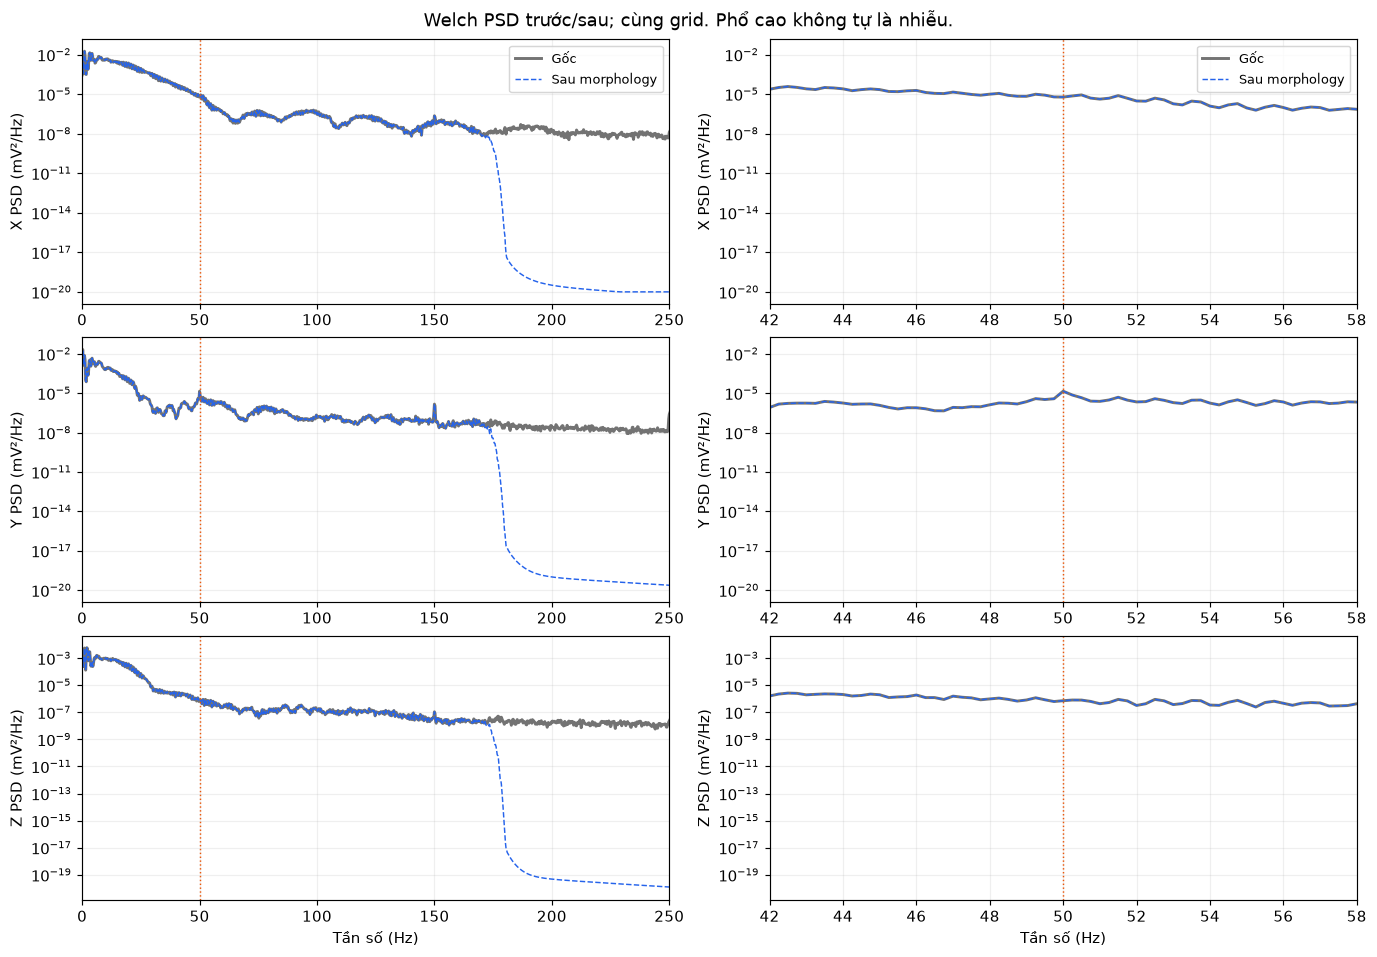

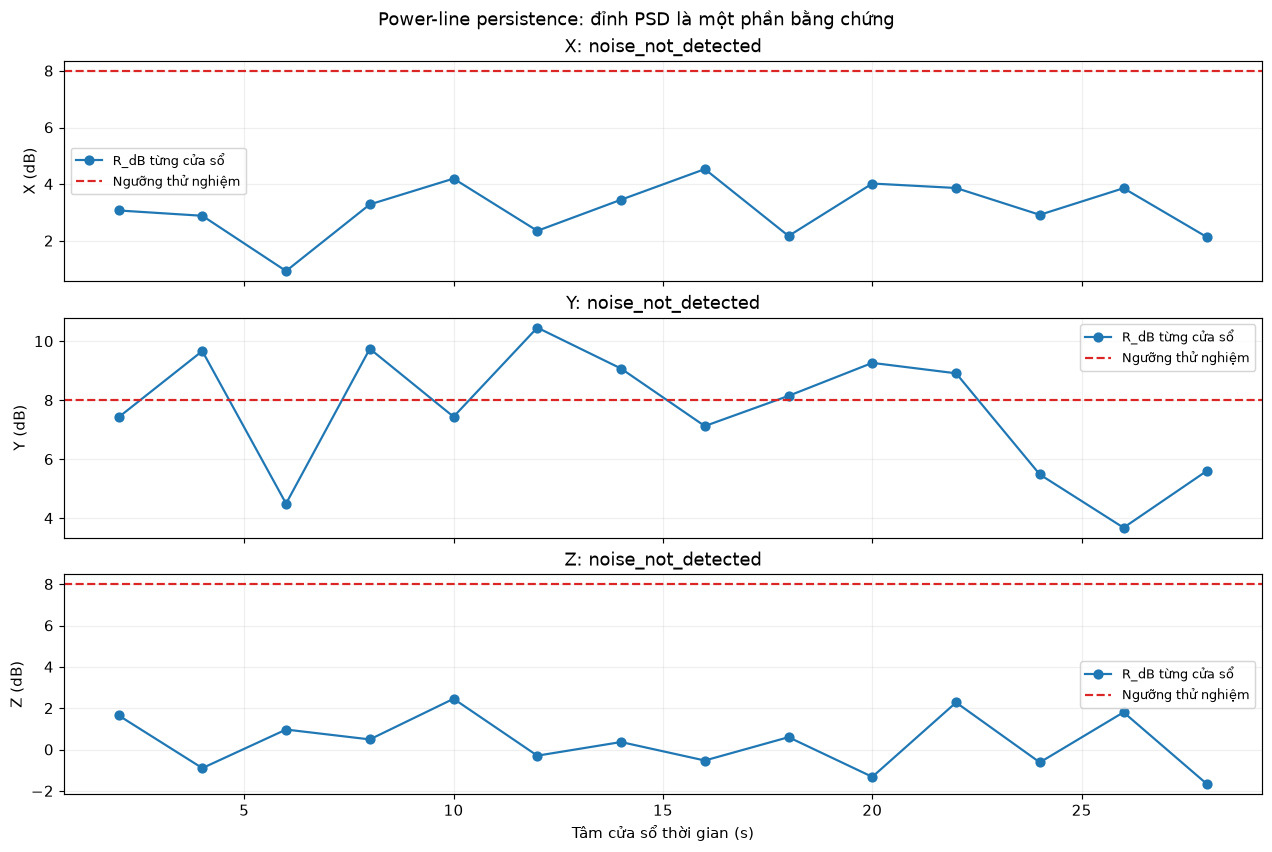

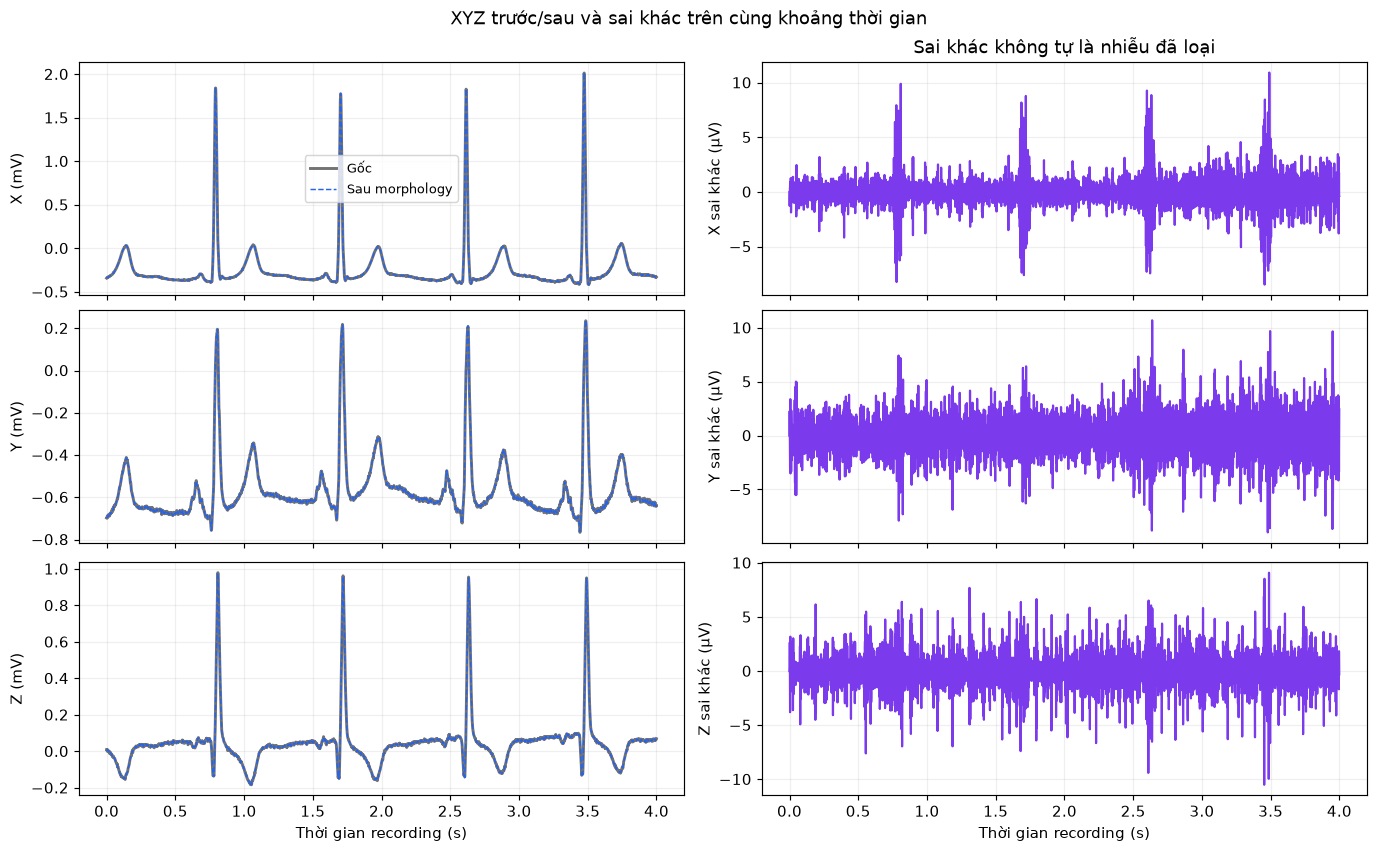

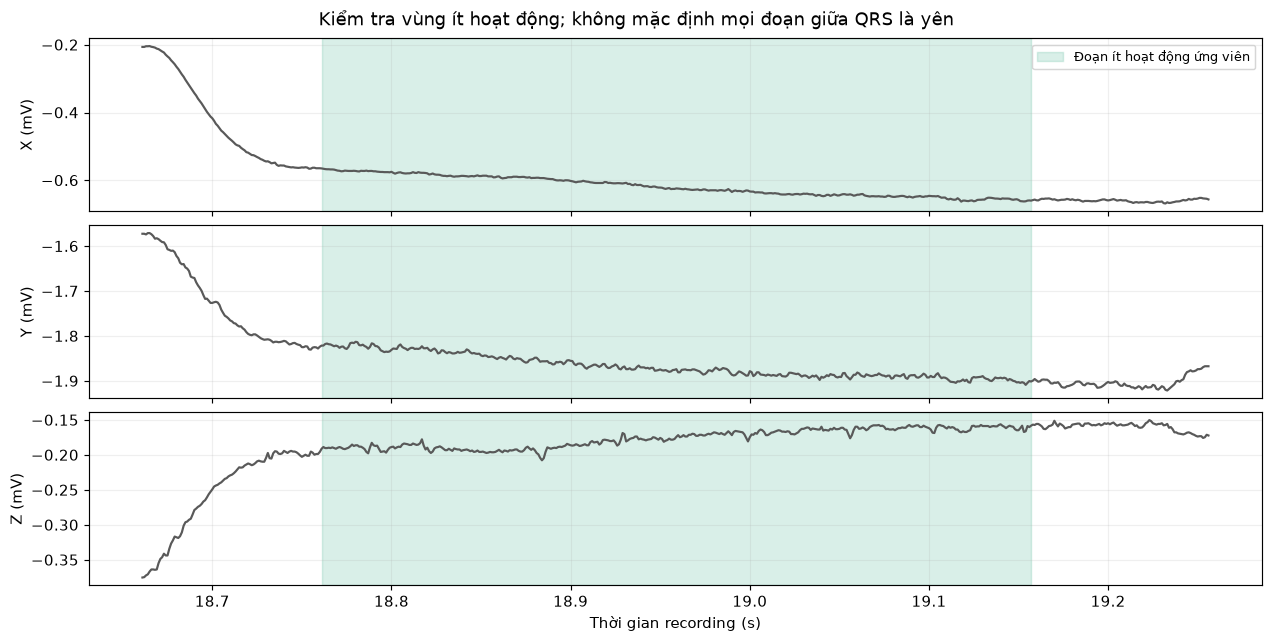

In [8]:
print({k:preprocessing[k] for k in ['morphology_mode','notch_applied','notch_mode','notch_channels',
    'powerline_status','powerline_score_db','powerline_persistence','notch_reason']})
display(powerline_diagnostic_table(preprocessing).T)
print('Warnings:',preprocessing['warnings'])
print('Quiet intervals:',preprocessing['powerline'].get('quiet_info'))
for fig in plot_preprocessing_diagnostics(raw_xyz,morph,fs,preprocessing,CFG):finish(fig)

## Bước 3 — Gộp ba kênh thành đường hoạt động để tìm từng nhịp

**Đầu vào:** `detection_xyz`, ba kênh đã band-pass.

**Thao tác:** tính $E(t)=X_d(t)^2+Y_d(t)^2+Z_d(t)^2$, lấy trung bình trượt 80 ms rồi căn bậc hai. Kết quả là envelope RMS:

$$A(t)=\sqrt{\operatorname{mean}_{80\,ms} E(t)}.$$

Bình phương giúp phần dương/âm đều đóng góp vào hoạt động. Trung bình ngắn giúp các sườn Q/R/S gần nhau tạo một cụm hoạt động thay vì coi mỗi sườn là một nhịp.

**Đầu ra:** một đường 1D, luôn không âm, đơn vị mV. Đỉnh trên đường này là **ứng viên nhịp**, chưa phải biên QRS và không phải loop.

**80 ms là giá trị thử ban đầu, chưa được tối ưu trên PTB.** Phần “Bổ sung — Kiểm tra cửa sổ 80 ms bằng nhiều giá trị” cuối notebook có grid 20–200 ms, biểu đồ và tiêu chí đánh giá cụ thể.

Cửa sổ trung bình: 80 mẫu = 80.0 ms


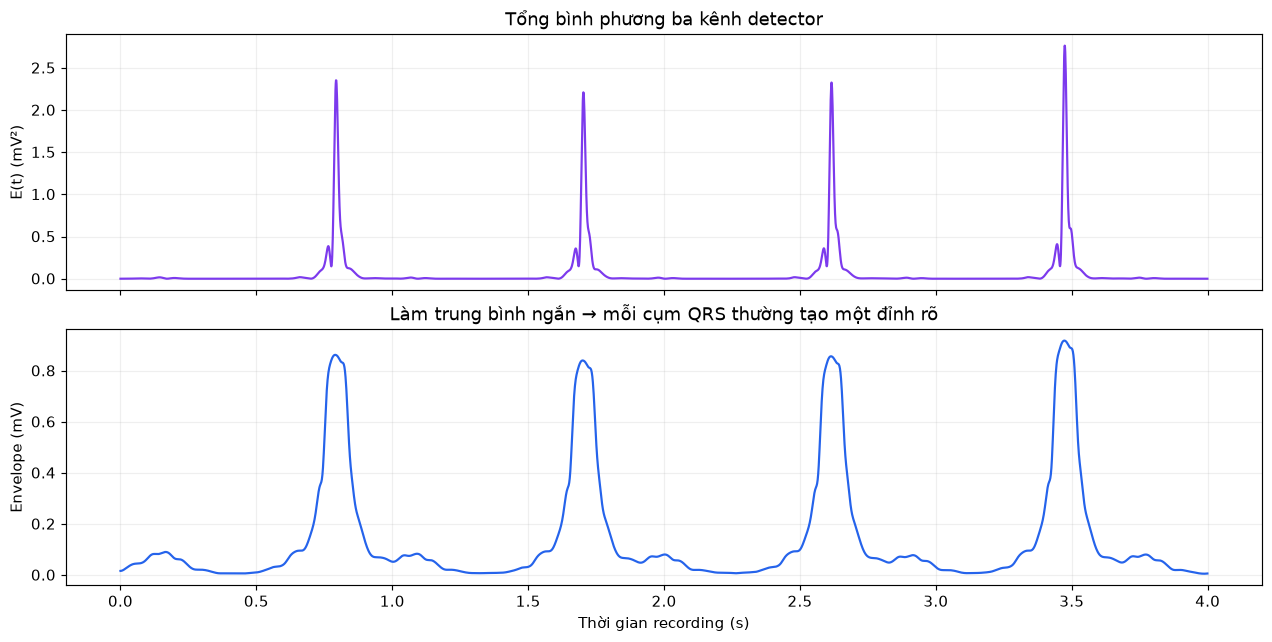

In [9]:
energy = np.sum(detection_xyz**2, axis=1)
window = ms_samples(CFG.energy_window_ms, fs)
envelope = np.sqrt(np.maximum(0, uniform_filter1d(energy, size=window)))
print('Cửa sổ trung bình:', window, 'mẫu =', window*1000/fs, 'ms')
fig,axs = plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
axs[0].plot(record_time,energy[:n_show],color='#7c3aed');axs[0].set_ylabel('E(t) (mV²)')
axs[0].set_title('Tổng bình phương ba kênh detector')
axs[1].plot(record_time,envelope[:n_show],color='#2563eb');axs[1].set_ylabel('Envelope (mV)')
axs[1].set_title('Làm trung bình ngắn → mỗi cụm QRS thường tạo một đỉnh rõ')
axs[1].set_xlabel('Thời gian recording (s)')
for ax in axs:ax.grid(alpha=.2)
finish(fig)

## Bước 4 — Ngưỡng thích nghi chọn các đỉnh ứng viên

**Đầu vào:** envelope ở Bước 3.

**Thao tác:** trong vùng 2 giây quanh từng thời điểm, ước lượng nền bằng percentile 20 và mức cao bằng percentile 95. Ngưỡng bằng nền + 25% khoảng cách từ nền đến mức cao. Code ước lượng đường ngưỡng ở khoảng 100 Hz cho nhẹ, rồi nội suy về tần số gốc.

`find_peaks` chọn cực đại vượt ngưỡng, rộng ít nhất 15 ms và cách nhau ít nhất 250 ms. Các con số là tham số triển khai; không phải mọi tín hiệu bệnh lý đều đáp ứng chúng.

**Đầu ra:** `candidates`, chỉ số mẫu của các đỉnh ứng viên. Nếu T cao/nhiễu vẫn vượt ngưỡng, detector có thể chọn nhầm; cần kiểm tra bằng mắt trên XYZ.

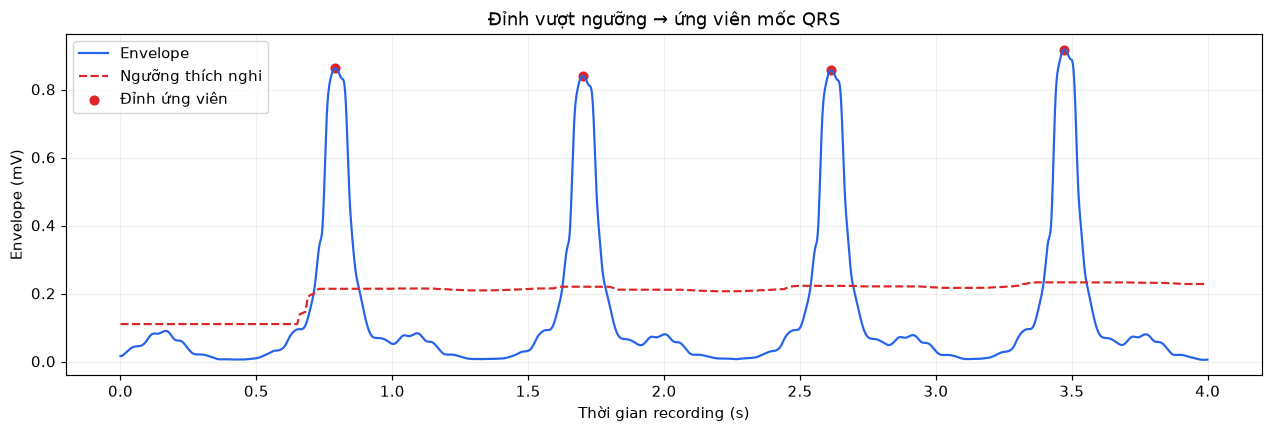

Ứng viên: 31 | mốc sau tinh chỉnh/refractory: 31


In [10]:
detector = detect_qrs_anchors(morph, detection_xyz, fs, CFG)
threshold = detector['threshold']
candidates, properties = find_peaks(envelope, height=threshold,
    distance=ms_samples(CFG.refractory_ms,fs), width=ms_samples(15,fs))
visible = candidates[candidates<n_show]
fig,ax = plt.subplots(figsize=(12,4),layout='constrained')
ax.plot(record_time,envelope[:n_show],color='#2563eb',label='Envelope')
ax.plot(record_time,threshold[:n_show],color='#dc2626',ls='--',label='Ngưỡng thích nghi')
ax.scatter(visible/fs,envelope[visible],color='#dc2626',s=35,label='Đỉnh ứng viên')
ax.set(xlabel='Thời gian recording (s)',ylabel='Envelope (mV)',title='Đỉnh vượt ngưỡng → ứng viên mốc QRS')
ax.legend();ax.grid(alpha=.2);finish(fig)
print('Ứng viên:', len(candidates), '| mốc sau tinh chỉnh/refractory:', len(detector['anchors']))

## Bước 5 — Tinh chỉnh một ứng viên thành mốc căn nhịp

**Đầu vào:** một đỉnh envelope. Trung bình trượt có thể làm đỉnh envelope lệch đỉnh điện thế.

**Thao tác:** xem XYZ morphology trong ±60 ms quanh ứng viên. Trừ baseline cục bộ lấy trước ứng viên rồi tìm điểm có magnitude lớn nhất trong vùng. Sau khi tinh chỉnh mọi ứng viên, áp dụng lại khoảng cách tối thiểu để tránh hai mốc quá gần nhau.

**Đầu ra:** một mốc QRS VCG cho từng nhịp. Mốc này dùng để căn các nhịp về cùng thời điểm. Nó không tự cho biết QRS bắt đầu/kết thúc; cũng không được coi là R trên ECG lead II.

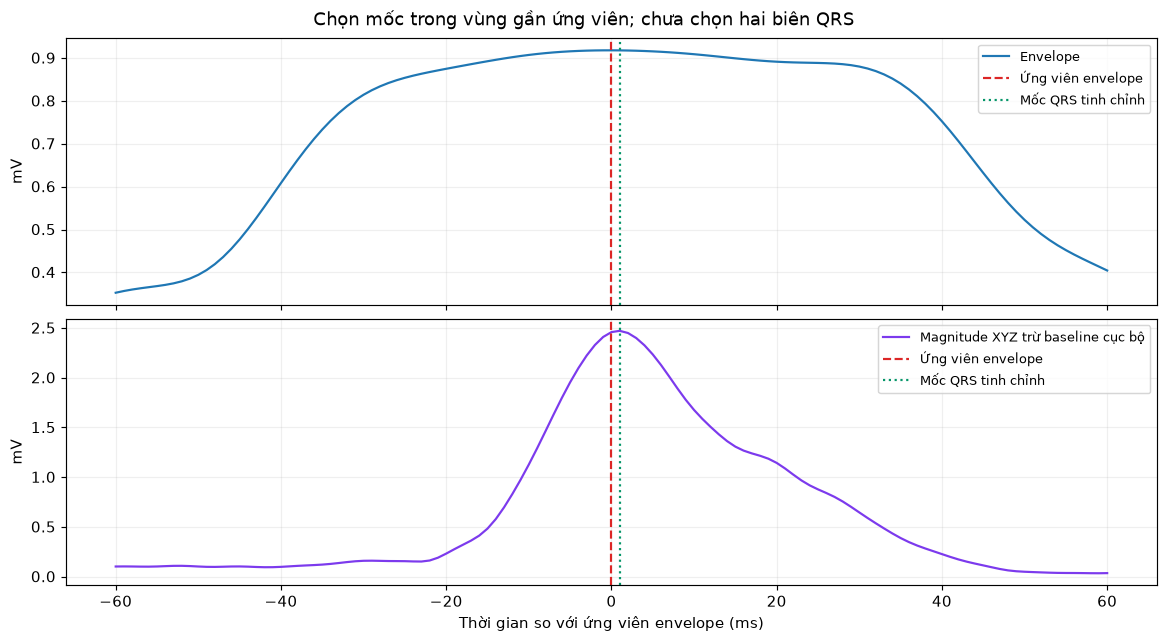

,vai trò,sample,thời gian recording (s)
0,Ứng viên,3473,3.473
1,Mốc tinh chỉnh,3474,3.474
2,Mốc đã giữ trong detector,3474,3.474


In [11]:
anchors = detector['anchors']
example_anchor = int(anchors[min(3,len(anchors)-2)])
p = int(candidates[np.argmin(np.abs(candidates-example_anchor))])
a,b = max(0,p-ms_samples(60,fs)), min(len(morph),p+ms_samples(60,fs)+1)
ba,bb = max(0,p-ms_samples(180,fs)), max(1,p-ms_samples(100,fs))
coarse_baseline = np.median(morph[ba:bb],axis=0)
local_mag = np.linalg.norm(morph[a:b]-coarse_baseline,axis=1)
refined_example = a+int(np.argmax(local_mag))
fig,axs = plt.subplots(2,1,figsize=(11,6),sharex=True,layout='constrained')
tt=(np.arange(a,b)-p)*1000/fs
axs[0].plot(tt,envelope[a:b],label='Envelope')
axs[1].plot(tt,local_mag,color='#7c3aed',label='Magnitude XYZ trừ baseline cục bộ')
for ax in axs:
    ax.axvline(0,color='#dc2626',ls='--',label='Ứng viên envelope')
    ax.axvline((refined_example-p)*1000/fs,color=QRS_COLOR,ls=':',label='Mốc QRS tinh chỉnh')
    ax.legend(fontsize=9);ax.grid(alpha=.2);ax.set_ylabel('mV')
axs[1].set_xlabel('Thời gian so với ứng viên envelope (ms)')
fig.suptitle('Chọn mốc trong vùng gần ứng viên; chưa chọn hai biên QRS')
finish(fig)
display(pd.DataFrame({'vai trò':['Ứng viên','Mốc tinh chỉnh','Mốc đã giữ trong detector'],
    'sample':[p,refined_example,example_anchor],
    'thời gian recording (s)':np.array([p,refined_example,example_anchor])/fs}))

## Bước 6 — Cắt một cửa sổ quanh mỗi mốc QRS

**Đầu vào:** morphology XYZ và danh sách mốc QRS.

**Thao tác:** tính median RR giữa các mốc. Khoảng trước mốc là min(280 ms, 40% RR); khoảng sau là min(650 ms, 78% RR). Những giới hạn này dùng để cắt beat, **chưa phải vùng QRS hoặc T**.

Loại beat sát biên recording, RR quá khác median hoặc có nguy cơ lẫn QRS kế tiếp. Đây là phân tích nhóm nhịp chiếm ưu thế; không đại diện đầy đủ cho ngoại tâm thu.

**Đầu ra:** các cửa sổ cùng chiều dài. Mỗi cửa sổ thường chứa P, QRS, ST và T; bước sau mới phân đoạn.

Median RR: 956.0 ms
Cửa sổ beat: -280.0 → 650.0 ms
Beat được giữ: 29 | loại: 2


,số beat
reason,
edge,2
used,29


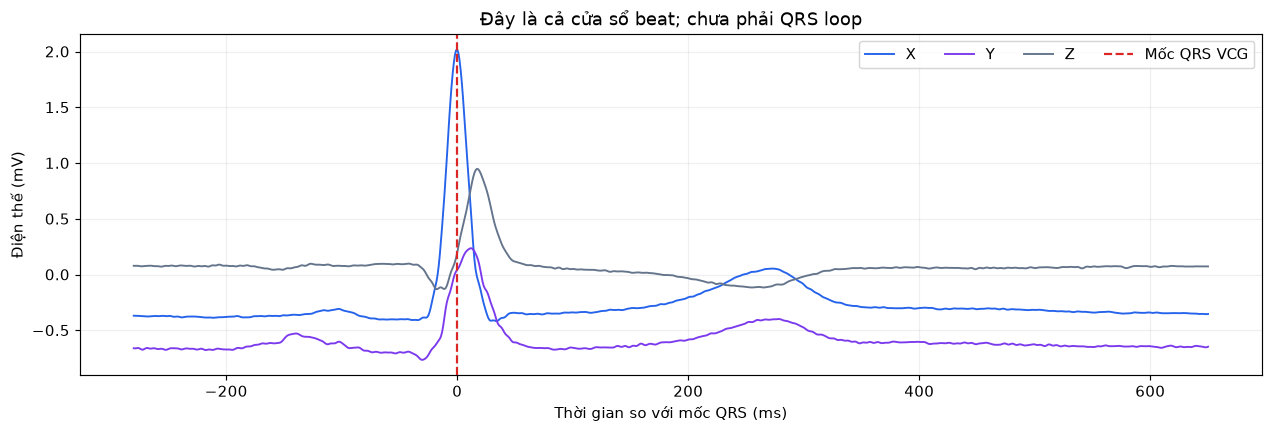

In [12]:
rep = representative_beat(morph, anchors, fs, CFG, quality=preprocessing['input_quality'])
median_rr = rep['rr_seconds']
pre = rep['anchor']
post = len(rep['xyz'])-pre-1
print(f'Median RR: {median_rr*1000:.1f} ms')
print(f'Cửa sổ beat: {-pre*1000/fs:.1f} → {post*1000/fs:.1f} ms')
print('Beat được giữ:', rep['n_used'], '| loại:', rep['n_excluded'])
display(rep['beat_qc'].groupby('reason').size().rename('số beat').to_frame())
used = rep['beat_qc'].loc[rep['beat_qc']['reason']=='used','sample'].to_numpy(dtype=int)
example_anchor = int(used[min(2,len(used)-1)])
start,stop = example_anchor-pre,example_anchor+post+1
single = morph[start:stop].copy()
single_time=(np.arange(len(single))-pre)*1000/fs
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
draw_xyz(ax,single_time,single)
ax.axvline(0,color='#dc2626',ls='--',label='Mốc QRS VCG')
ax.set(xlabel='Thời gian so với mốc QRS (ms)',title='Đây là cả cửa sổ beat; chưa phải QRS loop')
ax.legend(ncol=4,loc='upper right');finish(fig)

## Bước 7 — Đặt gốc tọa độ bằng đoạn PQ phẳng

**Đầu vào:** một beat và mốc tại 0 ms.

**Thao tác:** tìm cửa sổ 25 ms ít thay đổi nhất trong vùng trước QRS. Lấy median X/Y/Z của cửa sổ đó thành vector baseline, rồi trừ vector này khỏi mọi điểm trong beat.

**Đầu ra:** các điểm được tịnh tiến về gốc tham chiếu PQ. Phép trừ vector hằng không thay đổi đạo hàm/tốc độ, nhưng thay đổi khoảng cách đến gốc, vì vậy ảnh hưởng `MaxVec`.

Vùng xám cần thực sự là PQ; “phẳng nhất” không bảo đảm đúng vị trí sinh lý. Drift trong một beat vẫn có thể còn lại.

QC bổ sung kiểm tra độ yên/tản mạn trong PQ; vùng phẳng nhất không tự là PQ đúng. Xem `pq_warning` ở `rep["beat_qc"]`. Offset PQ–TP được ghi trong `baseline_residual`, không tự coi là drift hoặc áp dụng high-pass.

,mV
X baseline,-0.382177
Y baseline,-0.670773
Z baseline,0.080908


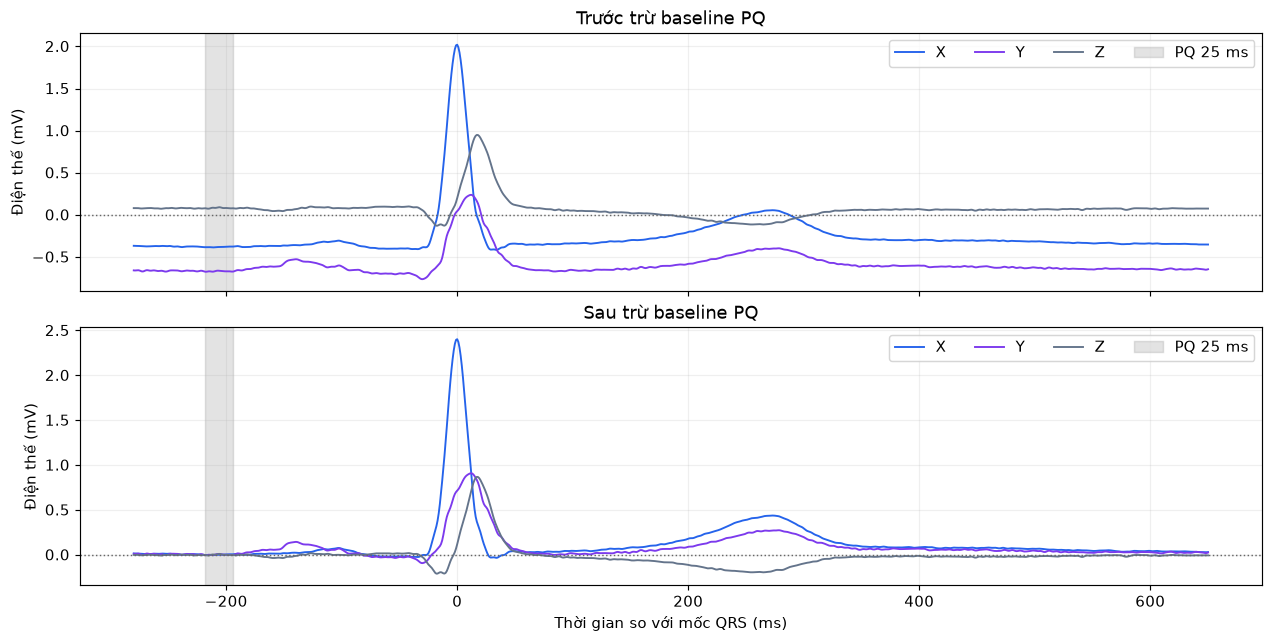

In [13]:
pq_single, baseline_single = flattest_pq(single,fs,pre,
    left_ms=-min(220,pre*1000/fs-5))
single_centered = single-baseline_single
display(pd.Series(baseline_single,index=['X baseline','Y baseline','Z baseline'],name='mV').to_frame())
fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
for ax,signal,title in [(axs[0],single,'Trước trừ baseline PQ'),(axs[1],single_centered,'Sau trừ baseline PQ')]:
    draw_xyz(ax,single_time,signal)
    ax.axvspan(single_time[pq_single[0]],single_time[pq_single[1]-1],color='.4',alpha=.18,label='PQ 25 ms')
    ax.axhline(0,color='.4',ls=':',lw=1);ax.set_title(title);ax.legend(ncol=4)
axs[1].set_xlabel('Thời gian so với mốc QRS (ms)');finish(fig)

## Bước 8 — Gộp các beat thành một median beat

**Đầu vào:** những beat đã căn mốc và baseline.

**Thao tác:** so hình dạng vùng QRS với template median ban đầu; gắn cờ nhưng giữ beat có tương quan dưới 0,85 nếu không có lỗi dữ liệu rõ; hình thái khác có thể là thông tin MI. Tại mỗi thời điểm, lấy median riêng cho X, Y, Z của những beat được giữ. Không co giãn thời gian.

**Đầu ra:** `rep_xyz`, một beat đại diện. Đường đậm là median, các đường mờ là những beat đã giữ. Các biên QRS/T sau đây được tìm trên **beat đại diện này**, không phải độc lập trên mọi beat.

Có thể thấy QRS và T khác rõ về hình dạng trên XYZ khi không làm mượt quá dài. Median giảm ảnh hưởng ngoại lai nhưng không tự chứng minh mọi chi tiết là tín hiệu thật.

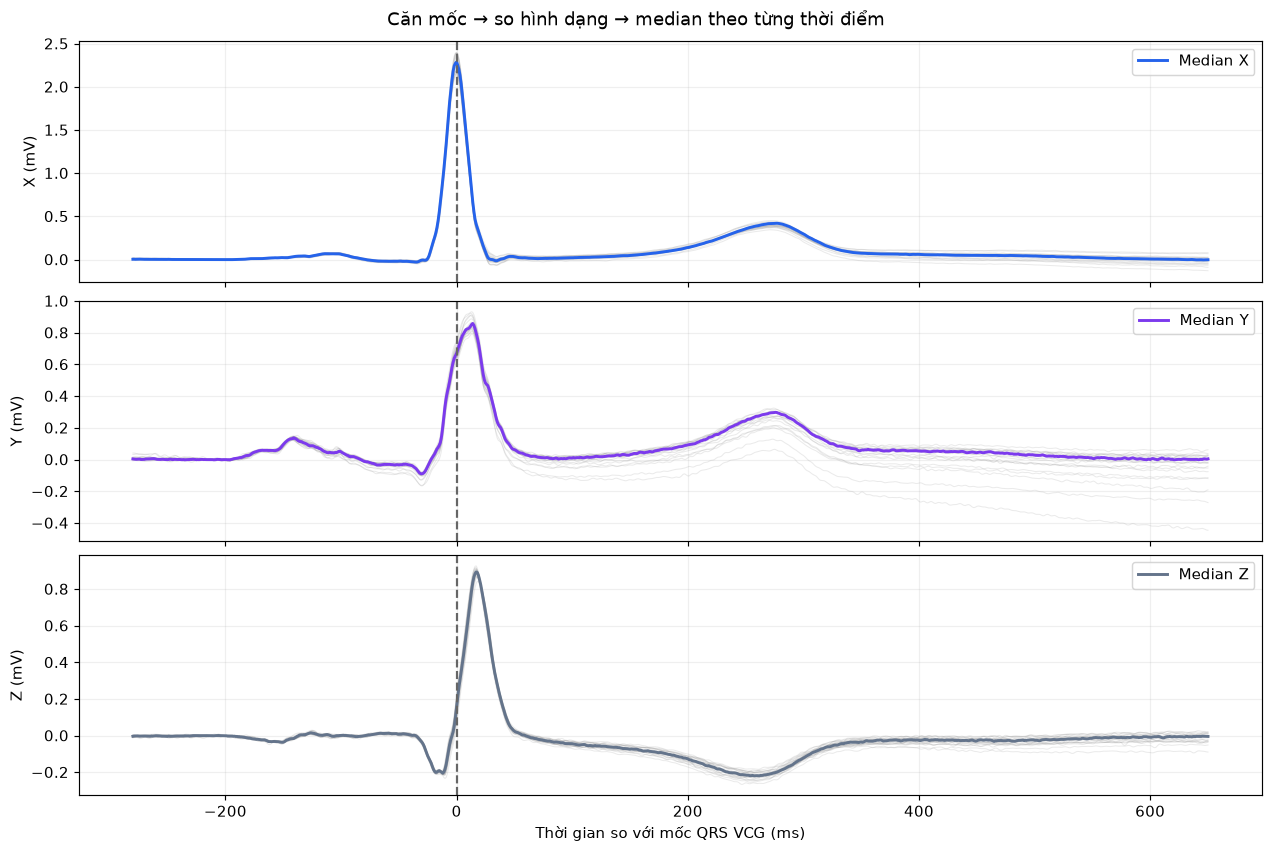

rep_xyz shape: (931, 3) | vị trí mốc 0 ms trong mảng: 280


In [14]:
rep_xyz = rep['xyz']; t = rep['time_ms']; anchor = rep['anchor']
fig,axs=plt.subplots(3,1,figsize=(12,8),sharex=True,layout='constrained')
for j,ax in enumerate(axs):
    for beat in rep['beats'][:20]: ax.plot(t,beat[:,j],color='.6',lw=.7,alpha=.20)
    ax.plot(t,rep_xyz[:,j],color=XYZ_COLORS[j],lw=2,label='Median '+'XYZ'[j])
    ax.axvline(0,color='.4',ls='--');ax.set_ylabel('XYZ'[j]+' (mV)');ax.legend();ax.grid(alpha=.2)
axs[-1].set_xlabel('Thời gian so với mốc QRS VCG (ms)')
fig.suptitle('Căn mốc → so hình dạng → median theo từng thời điểm')
finish(fig)
print('rep_xyz shape:', rep_xyz.shape, '| vị trí mốc 0 ms trong mảng:', anchor)

## Bước 9 — Tạo đường vận tốc để tìm biên QRS

**Đầu vào:** median XYZ.

**Thao tác:** tính $s(t)=\sqrt{(dX/dt)^2+(dY/dt)^2+(dZ/dt)^2}$ bằng đạo hàm SG ngắn 11 ms; trung bình thêm 5 ms cho đường dùng phân đoạn.

**Đầu ra:** tốc độ chuyển động của điểm điện thế XYZ, đơn vị mV/s. Đây không phải tốc độ dẫn truyền trong cơ tim.

Chú ý trong hình: QRS có thể tạo nhiều đỉnh vận tốc, tương ứng các sườn của Q/R/S. Đỉnh điện thế và đỉnh vận tốc không nhất thiết trùng nhau. Mục tiêu là tìm đầu/cuối **cả cụm hoạt động QRS**, không lấy riêng đỉnh cao nhất làm loop.

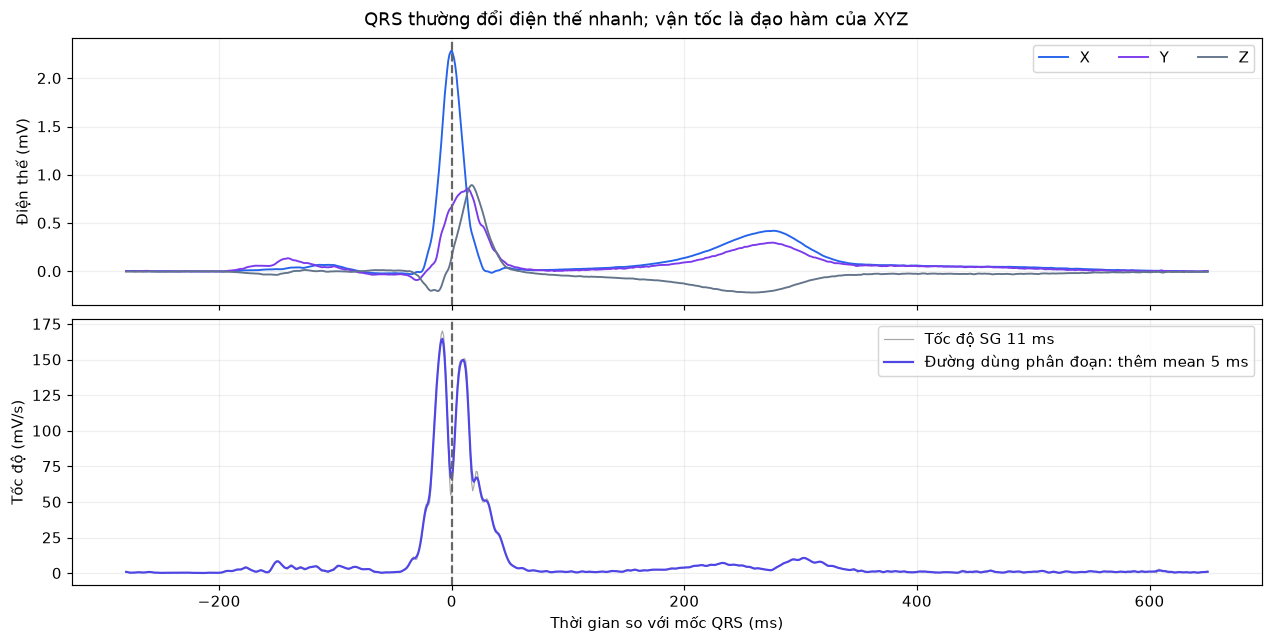

In [15]:
boundaries = delineate_loops(rep,fs,CFG)
speed = boundaries['speed']; speed_q = boundaries['smooth_speed']
fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
draw_xyz(axs[0],t,rep_xyz);axs[0].legend(ncol=3)
axs[1].plot(t,speed,color='.65',lw=.8,label='Tốc độ SG 11 ms')
axs[1].plot(t,speed_q,color='#4f46e5',label='Đường dùng phân đoạn: thêm mean 5 ms')
axs[1].set_ylabel('Tốc độ (mV/s)');axs[1].set_xlabel('Thời gian so với mốc QRS (ms)');axs[1].legend()
for ax in axs: ax.axvline(0,color='.4',ls='--');ax.grid(alpha=.2)
fig.suptitle('QRS thường đổi điện thế nhanh; vận tốc là đạo hàm của XYZ')
finish(fig)

## Bước 10 — Giới hạn vùng tìm QRS và đặt ngưỡng

**Đầu vào:** vận tốc và mốc tại 0 ms.

**Thao tác:** tìm QRS trong −180 đến +200 ms. Đỉnh vận tốc làm hạt giống được chọn trong vùng hẹp −80 đến +80 ms, để ưu tiên hoạt động gần mốc căn nhịp. Ngưỡng là max(nền PQ + 4 lần MAD chuẩn hóa, 7% đỉnh vận tốc).

**Đầu ra:** một ngưỡng và một đỉnh vận tốc gần mốc. Vùng xám chỉ là cửa sổ tìm kiếm; chưa phải QRS đã tìm được. Một đỉnh ở xa cửa sổ không được chọn chỉ vì cao hơn.

,đại lượng,giá trị,đơn vị
0,Nền vận tốc PQ,0.332044,mV/s
1,MAD chuẩn hóa PQ,0.086902,mV/s
2,7% đỉnh,11.525892,mV/s
3,Ngưỡng được dùng,11.525892,mV/s
4,Thời điểm đỉnh vận tốc,-8.000000,ms


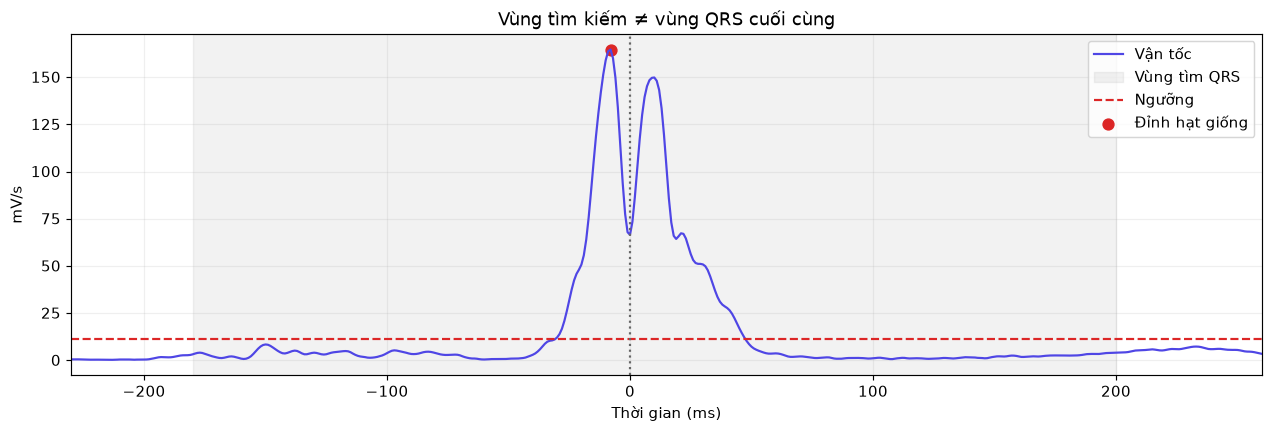

In [16]:
qlo=max(0,anchor+int(CFG.qrs_search_ms[0]*fs/1000))
qhi=min(len(t)-1,anchor+int(CFG.qrs_search_ms[1]*fs/1000))
qpeak=boundaries['qrs_speed_peak']; qthreshold=boundaries['q_threshold']
pq0,pq1=rep['pq']
qbase=float(np.median(speed_q[pq0:pq1]));qnoise=robust_sigma(speed_q[pq0:pq1])
display(pd.DataFrame({'đại lượng':['Nền vận tốc PQ','MAD chuẩn hóa PQ','7% đỉnh','Ngưỡng được dùng','Thời điểm đỉnh vận tốc'],
    'giá trị':[qbase,qnoise,CFG.qrs_fraction*speed_q[qpeak],qthreshold,t[qpeak]],
    'đơn vị':['mV/s','mV/s','mV/s','mV/s','ms']}))
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.plot(t,speed_q,color='#4f46e5',label='Vận tốc')
ax.axvspan(t[qlo],t[qhi],color='.5',alpha=.10,label='Vùng tìm QRS')
ax.axhline(qthreshold,color='#dc2626',ls='--',label='Ngưỡng')
ax.scatter(t[qpeak],speed_q[qpeak],color='#dc2626',s=55,label='Đỉnh hạt giống')
ax.axvline(0,color='.4',ls=':');ax.set(xlim=(-230,260),xlabel='Thời gian (ms)',ylabel='mV/s',title='Vùng tìm kiếm ≠ vùng QRS cuối cùng')
ax.legend();ax.grid(alpha=.2);finish(fig)

## Bước 11 — Tìm hai biên quanh cả cụm QRS

**Đầu vào:** các mẫu có vận tốc vượt ngưỡng.

**Thao tác:**

1. Tạo mask “trên ngưỡng”. Nối khe ngắn khoảng 15 ms để hạn chế cắt giữa hai sườn của cùng QRS.
2. Chọn cụm chứa đỉnh hạt giống ở Bước 10.
3. Từ hai đầu cụm, quét ra ngoài. Chỉ chốt biên khi có ít nhất 12 ms liên tục ở dưới ngưỡng.

**Đầu ra:** `qrs_on`, `qrs_off`. Một điểm tụt ngắn giữa hai đỉnh chưa đủ để làm biên. Nếu không có đoạn yên thì biên để thiếu, không dùng mép cửa sổ thay thế.

Hình đầu cho thấy việc nối khe; hình sau đánh dấu khoảng QRS cuối cùng.

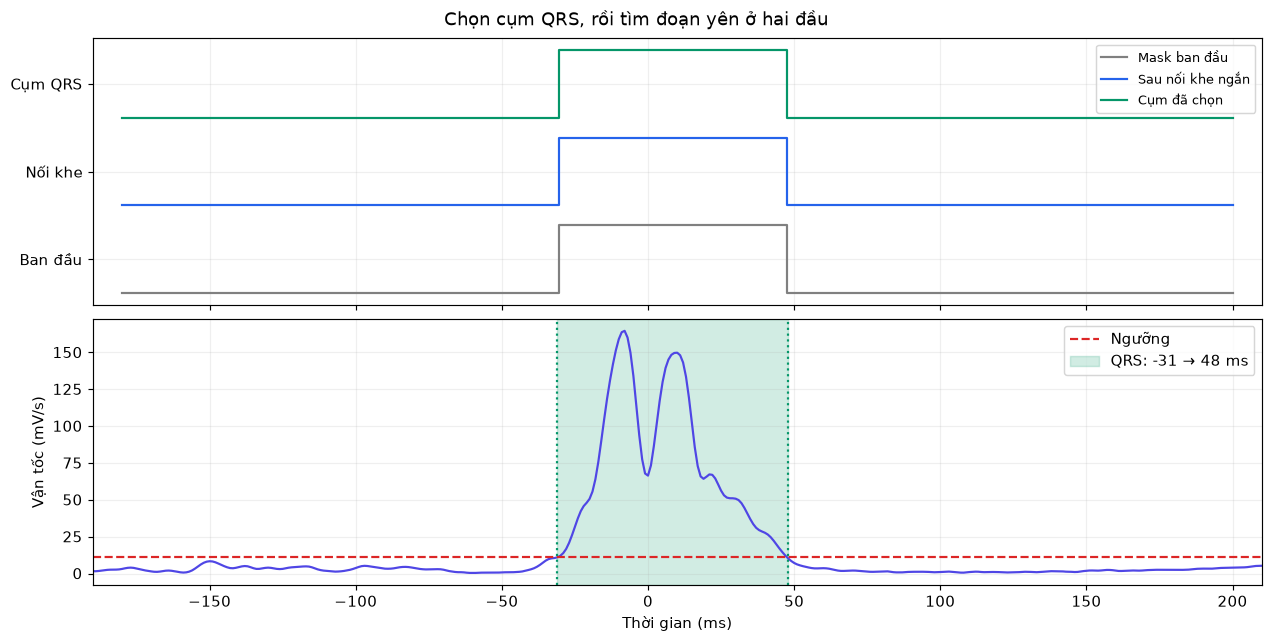

In [17]:
active_raw = speed_q[qlo:qhi+1] > qthreshold
active_closed = binary_closing(active_raw,structure=np.ones(ms_samples(15,fs),bool))
left=right=qpeak-qlo
while left>0 and active_closed[left-1]: left-=1
while right<len(active_closed)-1 and active_closed[right+1]: right+=1
selected_mask=np.zeros_like(active_closed);selected_mask[left:right+1]=True
q_on,q_off=boundaries['qrs_on'],boundaries['qrs_off']
fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
axs[0].step(t[qlo:qhi+1],active_raw.astype(int),where='mid',color='.5',label='Mask ban đầu')
axs[0].step(t[qlo:qhi+1],active_closed.astype(int)+1.3,where='mid',color='#2563eb',label='Sau nối khe ngắn')
axs[0].step(t[qlo:qhi+1],selected_mask.astype(int)+2.6,where='mid',color=QRS_COLOR,label='Cụm đã chọn')
axs[0].set_yticks([.5,1.8,3.1],['Ban đầu','Nối khe','Cụm QRS']);axs[0].legend(loc='upper right',fontsize=9)
axs[1].plot(t,speed_q,color='#4f46e5');axs[1].axhline(qthreshold,color='#dc2626',ls='--',label='Ngưỡng')
if q_on is not None and q_off is not None:
    axs[1].axvspan(t[q_on],t[q_off],color=QRS_COLOR,alpha=.18,label=f'QRS: {t[q_on]:.0f} → {t[q_off]:.0f} ms')
    axs[1].axvline(t[q_on],color=QRS_COLOR,ls=':');axs[1].axvline(t[q_off],color=QRS_COLOR,ls=':')
axs[1].set(xlim=(-190,210),xlabel='Thời gian (ms)',ylabel='Vận tốc (mV/s)');axs[1].legend()
for ax in axs:ax.grid(alpha=.2)
fig.suptitle('Chọn cụm QRS, rồi tìm đoạn yên ở hai đầu')
finish(fig)

### Xem quá trình đếm đoạn yên từng mẫu

Bảng dưới cho thấy các lần quét ra ngoài cụm. `liên tiếp dưới ngưỡng` tăng khi mẫu thấp, trở về 0 khi mẫu cao. Khi đủ số mẫu, biên được trả về ở **mép gần QRS** của đoạn yên. Vì thế mốc trả về khác mẫu cuối cùng dùng để xác nhận đoạn yên.

In [18]:
def trace_quiet(values,start,limit,direction,threshold,run):
    rows=[];count=0
    for i in range(start,limit+direction,direction):
        below=bool(values[i]<=threshold)
        count=count+1 if below else 0
        returned=None
        if count>=run:returned=i+run-1 if direction<0 else i-run+1
        rows.append({'sample':i,'thời gian (ms)':t[i],'vận tốc (mV/s)':values[i],
                     'dưới ngưỡng':below,'liên tiếp dưới ngưỡng':count,
                     'biên trả về (ms)':np.nan if returned is None else t[returned]})
        if returned is not None:break
    return pd.DataFrame(rows)

run=ms_samples(CFG.quiet_qrs_ms,fs)
on_trace=trace_quiet(speed_q,qlo+left,qlo,-1,qthreshold,run)
off_trace=trace_quiet(speed_q,qlo+right,qhi,1,qthreshold,run)
print('Cần',run,'mẫu liên tục =',run*1000/fs,'ms dưới ngưỡng.')
print('Quét trái: các bước cuối');display(on_trace.tail(run+2))
print('Quét phải: các bước cuối');display(off_trace.tail(run+2))

Cần 12 mẫu liên tục = 12.0 ms dưới ngưỡng.
Quét trái: các bước cuối


,sample,thời gian (ms),vận tốc (mV/s),dưới ngưỡng,liên tiếp dưới ngưỡng,biên trả về (ms)
0,250,-30.0,12.078963,False,0,NaN
1,249,-31.0,11.021021,True,1,NaN
2,248,-32.0,10.523085,True,2,NaN
3,247,-33.0,10.330853,True,3,NaN
4,246,-34.0,9.841799,True,4,NaN
5,245,-35.0,8.774398,True,5,NaN
6,244,-36.0,7.334165,True,6,NaN
7,243,-37.0,5.858819,True,7,NaN
8,242,-38.0,4.606715,True,8,NaN
9,241,-39.0,3.614743,True,9,NaN


Quét phải: các bước cuối


,sample,thời gian (ms),vận tốc (mV/s),dưới ngưỡng,liên tiếp dưới ngưỡng,biên trả về (ms)
0,327,47.0,12.203486,False,0,NaN
1,328,48.0,10.202143,True,1,NaN
2,329,49.0,8.532773,True,2,NaN
3,330,50.0,7.195377,True,3,NaN
4,331,51.0,6.234892,True,4,NaN
5,332,52.0,5.565975,True,5,NaN
6,333,53.0,5.015334,True,6,NaN
7,334,54.0,4.544299,True,7,NaN
8,335,55.0,4.095052,True,8,NaN
9,336,56.0,3.725947,True,9,NaN


## Bước 12 — Tạo magnitude và tìm đỉnh T sau QRS

**Đầu vào:** median XYZ và QRS_off.

**Thao tác:** magnitude $M(t)=\sqrt{X^2+Y^2+Z^2}$ biểu thị khoảng cách của điểm XYZ đến gốc PQ. Làm mượt nhẹ magnitude 21 ms. Tìm đỉnh nổi bật trong vùng sau QRS, kết thúc trước nhịp kế tiếp theo median RR.

**Đầu ra:** một T peak candidate. Chọn đỉnh có prominence rõ trong vùng tìm kiếm, không lấy cực đại magnitude của toàn beat — cực đại toàn beat thường thuộc QRS.

Cụ thể, vùng tìm bắt đầu ở QRS_off + 20 ms và kết thúc ở min(600 ms, 70% median RR) sau mốc QRS. Đỉnh hợp lệ phải cách QRS_off ít nhất 50 ms và cách mép phải ít nhất 30 ms. Prominence tối thiểu là max(4 lần nhiễu magnitude PQ, 1,5% magnitude lớn nhất của QRS). Chọn prominence lớn nhất trong các đỉnh hợp lệ; lobe rõ khác trong ±100 ms được xét cùng và gắn cờ nhiều lobe.

Magnitude không giữ dấu của từng lead; sóng T âm trên Y vẫn có thể tạo đồi dương trên magnitude. Nhiều lobe T sẽ được gắn cờ để kiểm tra.

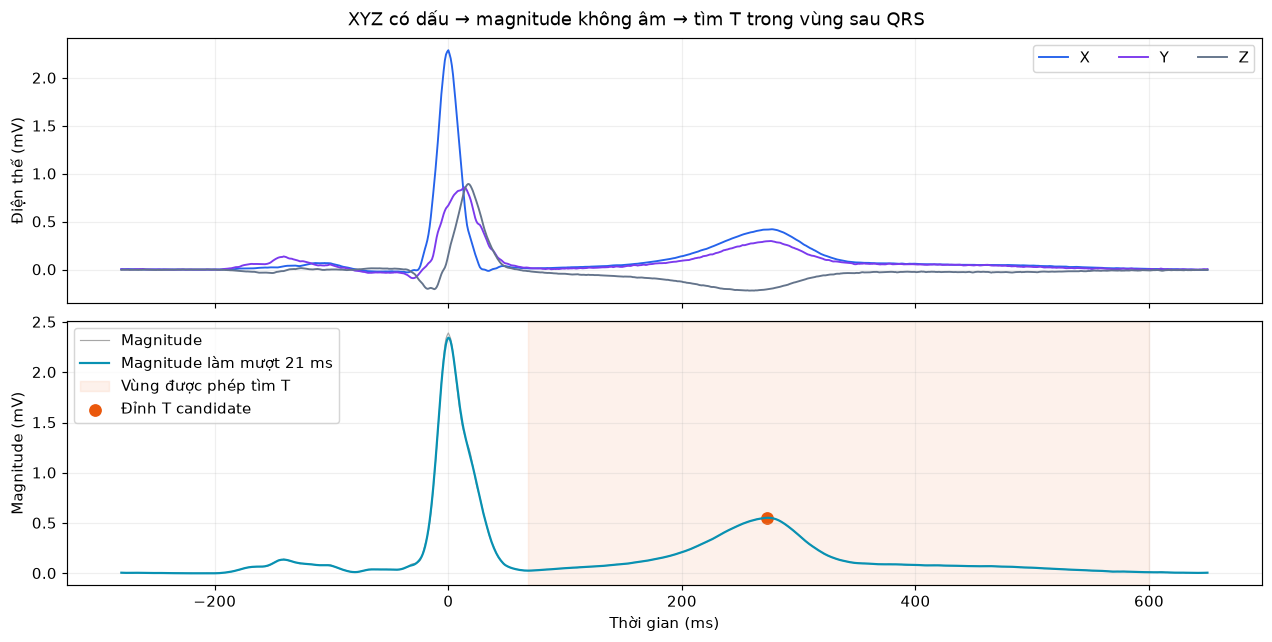

T peak candidate: 273.0 ms; magnitude: 0.5526 mV


In [19]:
mag = boundaries['magnitude']; mag_t=boundaries['t_magnitude']
tlo,thi = boundaries['t_search']; t_peak=boundaries['t_peak']
fig,axs=plt.subplots(2,1,figsize=(12,6),sharex=True,layout='constrained')
draw_xyz(axs[0],t,rep_xyz);axs[0].legend(ncol=3)
axs[1].plot(t,mag,color='.65',lw=.8,label='Magnitude')
axs[1].plot(t,mag_t,color='#0891b2',label='Magnitude làm mượt 21 ms')
if tlo is not None and thi is not None:
    axs[1].axvspan(t[tlo],t[thi],color=T_COLOR,alpha=.08,label='Vùng được phép tìm T')
if t_peak is not None:axs[1].scatter(t[t_peak],mag_t[t_peak],color=T_COLOR,s=60,label='Đỉnh T candidate')
axs[1].set_ylabel('Magnitude (mV)');axs[1].set_xlabel('Thời gian (ms)');axs[1].legend()
for ax in axs:ax.grid(alpha=.2)
fig.suptitle('XYZ có dấu → magnitude không âm → tìm T trong vùng sau QRS')
finish(fig)
if t_peak is None:print('Chưa tìm được T peak rõ; các bước tiếp tuyến sẽ không tạo biên giả.')
else:print(f'T peak candidate: {t[t_peak]:.1f} ms; magnitude: {mag_t[t_peak]:.4f} mV')

## Bước 13 — Xác định mức ST và baseline TP cho hai tiếp tuyến

**Đầu vào:** đường magnitude sau QRS.

**Thao tác:** lấy mức ST từ một vùng ngắn sau QRS. Sau T peak, tìm một đoạn TP phẳng 25 ms để ước lượng baseline cuối T. Dùng TP phía sau giúp hạn chế ảnh hưởng drift khi magnitude không về đúng mức PQ phía trước.

**Đầu ra:** hai mức điện thế tham chiếu, không phải hai biên. Mức ST dùng cho tiếp tuyến đi lên; baseline TP dùng cho tiếp tuyến đi xuống. XYZ dùng tính feature vẫn có gốc PQ chung, không tự bị tịnh tiến riêng theo TP.

Vùng PQ/TP tìm tự động cần kiểm tra. Mức ST khác PQ có thể do hình thái hoặc drift; cờ này không tự chẩn đoán ST elevation.

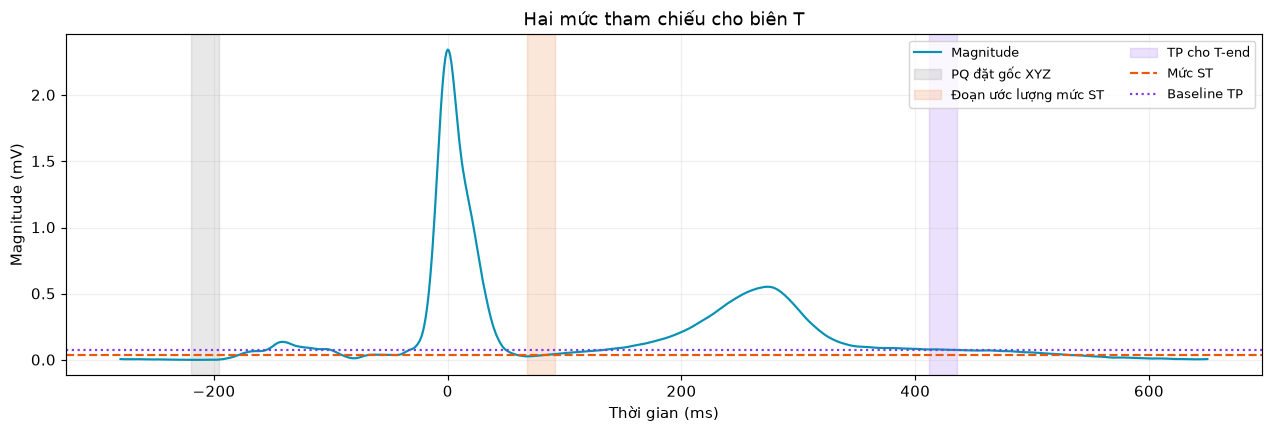

,mức,giá trị (mV)
0,ST,0.034760
1,TP cuối T,0.077967


In [20]:
tp=boundaries['tp']; st_level=boundaries['st_level']; tp_level=boundaries['t_end_baseline']
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.plot(t,mag_t,color='#0891b2',label='Magnitude')
ax.axvspan(t[pq0],t[pq1-1],color='.5',alpha=.18,label='PQ đặt gốc XYZ')
if tlo is not None and t_peak is not None:
    st_stop=min(t_peak,tlo+ms_samples(25,fs))
    ax.axvspan(t[tlo],t[st_stop-1],color=T_COLOR,alpha=.15,label='Đoạn ước lượng mức ST')
if tp is not None:ax.axvspan(t[tp[0]],t[tp[1]-1],color='#7c3aed',alpha=.15,label='TP cho T-end')
if np.isfinite(st_level):ax.axhline(st_level,color=T_COLOR,ls='--',label='Mức ST')
if np.isfinite(tp_level):ax.axhline(tp_level,color='#7c3aed',ls=':',label='Baseline TP')
ax.set(xlabel='Thời gian (ms)',ylabel='Magnitude (mV)',title='Hai mức tham chiếu cho biên T')
ax.legend(fontsize=9,ncol=2);ax.grid(alpha=.2);finish(fig)
display(pd.DataFrame({'mức':['ST','TP cuối T'],'giá trị (mV)':[st_level,tp_level]}))

## Bước 14 — T-on từ tiếp tuyến sườn đi lên

**Đầu vào:** T peak, mức ST và magnitude làm mượt.

**Thao tác:** trước T peak, tìm điểm có độ dốc dương lớn nhất. Vẽ tiếp tuyến qua điểm đó; kéo tiếp tuyến về bên trái đến khi cắt mức ST.

**Đầu ra:** giao điểm là T-on candidate. Nó thường nằm trên chân sườn lên, không phải ngay T peak và không được cộng/trừ một padding cố định.

Nếu điểm tiếp tuyến là $(t_s,M_s)$ và độ dốc $k$ tính bằng mV/s:

$$t_{on}=t_s+\frac{M_{ST}-M_s}{k}.$$

Tất cả thời gian trong công thức phải cùng đơn vị; code đổi sang chỉ số mẫu rồi hiển thị ms. Nếu giao điểm không hợp lệ, dùng candidate theo ngưỡng nếu có và gắn cờ. **Đây là định nghĩa thao tác của T-on**, không phải điểm bắt đầu T đã được xác nhận lâm sàng.

,giá trị,số
0,Điểm tiếp tuyến (ms),229.000000
1,Magnitude tại điểm (mV),0.359787
2,Độ dốc (mV/s),6.651830
3,Mức ST (mV),0.034760
4,Giao điểm T-on (ms),180.000000


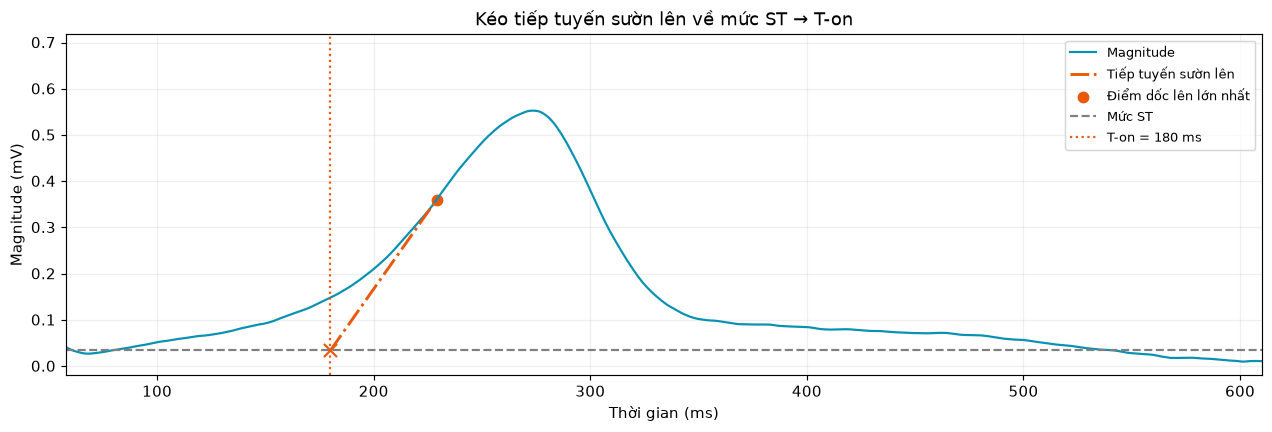

In [21]:
rise=boundaries['t_rise_index']; tangent_on=boundaries['t_tangent_on']
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.plot(t,mag_t,color='#0891b2',label='Magnitude')
if tlo is not None and thi is not None:ax.set_xlim(t[tlo]-10,t[thi]+10)
if t_peak is not None:ax.set_ylim(-.02,max(.05,mag_t[t_peak]*1.3))
if rise is not None and tangent_on is not None:
    slope=boundaries['t_slope'][rise]
    ix=np.array([tangent_on,rise])
    yy=mag_t[rise]+slope*(ix-rise)/fs
    ax.plot(t[ix],yy,color=T_COLOR,ls='-.',lw=2,label='Tiếp tuyến sườn lên')
    ax.scatter(t[rise],mag_t[rise],color=T_COLOR,s=50,label='Điểm dốc lên lớn nhất')
    ax.axhline(st_level,color='.5',ls='--',label='Mức ST')
    ax.axvline(t[tangent_on],color=T_COLOR,ls=':',label=f'T-on = {t[tangent_on]:.0f} ms')
    ax.scatter(t[tangent_on],st_level,color=T_COLOR,marker='x',s=80)
    display(pd.DataFrame({'giá trị':['Điểm tiếp tuyến (ms)','Magnitude tại điểm (mV)','Độ dốc (mV/s)','Mức ST (mV)','Giao điểm T-on (ms)'],
                         'số':[t[rise],mag_t[rise],slope,st_level,t[tangent_on]]}))
else:print('Không có giao điểm tiếp tuyến T-on hợp lệ; xem cờ QC.')
ax.set(xlabel='Thời gian (ms)',ylabel='Magnitude (mV)',title='Kéo tiếp tuyến sườn lên về mức ST → T-on')
ax.legend(fontsize=9);ax.grid(alpha=.2);finish(fig)

## Bước 15 — T-off từ tiếp tuyến sườn đi xuống

**Đầu vào:** T peak và baseline TP.

**Thao tác:** sau T peak (hoặc lobe cuối nếu T nhiều lobe), tìm điểm có độ dốc âm lớn nhất về trị tuyệt đối. Kéo tiếp tuyến xuống tới mức TP.

**Đầu ra:** giao điểm là T-off candidate. Đây là thời điểm kết thúc theo quy tắc tiếp tuyến, có thể sớm hơn thời điểm magnitude gần như về hẳn baseline.

Trong hình, đường tím là tiếp tuyến; đường xám đứng là T-end ước lượng bằng ngưỡng. Bất đồng lớn hoặc không đủ vùng TP sẽ gắn cờ. Code không mặc định lấy mép cửa sổ tìm kiếm làm T-off.

,giá trị,số
0,Điểm tiếp tuyến (ms),301.000000
1,Magnitude tại điểm (mV),0.370080
2,Độ dốc (mV/s),-10.271729
3,Baseline TP (mV),0.077967
4,Giao điểm T-off (ms),329.000000


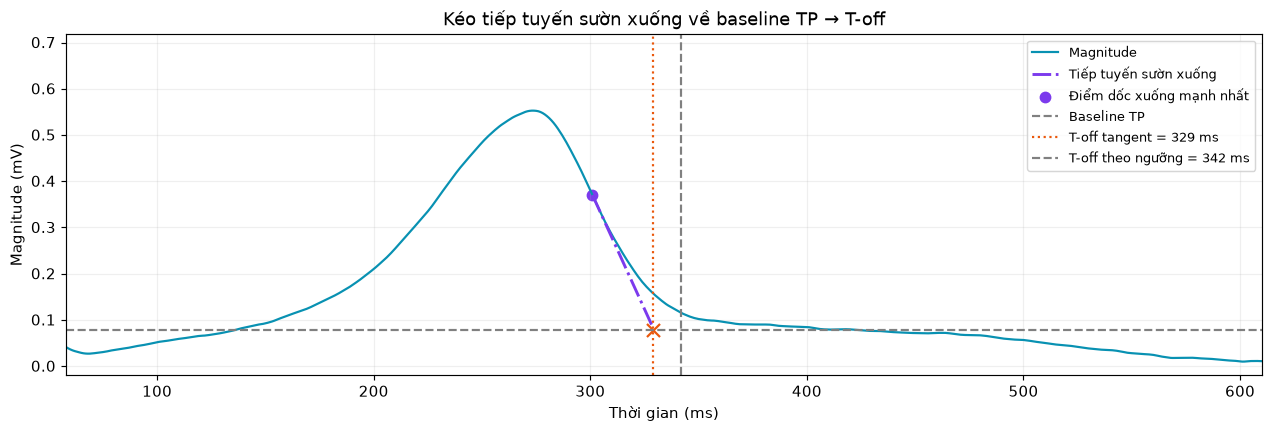

In [22]:
fall=boundaries['t_fall_index']; tangent_off=boundaries['t_tangent_off']
threshold_off=boundaries['t_threshold_off']
fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
ax.plot(t,mag_t,color='#0891b2',label='Magnitude')
if tlo is not None and thi is not None:ax.set_xlim(t[tlo]-10,t[thi]+10)
if t_peak is not None:ax.set_ylim(-.02,max(.05,mag_t[t_peak]*1.3))
if fall is not None and tangent_off is not None:
    slope=boundaries['t_slope'][fall]
    ix=np.array([fall,tangent_off]);yy=mag_t[fall]+slope*(ix-fall)/fs
    ax.plot(t[ix],yy,color='#7c3aed',ls='-.',lw=2,label='Tiếp tuyến sườn xuống')
    ax.scatter(t[fall],mag_t[fall],color='#7c3aed',s=50,label='Điểm dốc xuống mạnh nhất')
    ax.axhline(tp_level,color='.5',ls='--',label='Baseline TP')
    ax.axvline(t[tangent_off],color=T_COLOR,ls=':',label=f'T-off tangent = {t[tangent_off]:.0f} ms')
    ax.scatter(t[tangent_off],tp_level,color=T_COLOR,marker='x',s=80)
    display(pd.DataFrame({'giá trị':['Điểm tiếp tuyến (ms)','Magnitude tại điểm (mV)','Độ dốc (mV/s)','Baseline TP (mV)','Giao điểm T-off (ms)'],
                         'số':[t[fall],mag_t[fall],slope,tp_level,t[tangent_off]]}))
else:print('Không có giao điểm tiếp tuyến T-off hợp lệ; xem cờ QC.')
if threshold_off is not None:ax.axvline(t[threshold_off],color='.5',ls='--',label=f'T-off theo ngưỡng = {t[threshold_off]:.0f} ms')
ax.set(xlabel='Thời gian (ms)',ylabel='Magnitude (mV)',title='Kéo tiếp tuyến sườn xuống về baseline TP → T-off')
ax.legend(fontsize=9);ax.grid(alpha=.2);finish(fig)

## Bước 16 — Đặt bốn mốc lên cùng một biểu đồ XYZ

**Đầu vào:** median XYZ và bốn biên vừa ước lượng.

**Thao tác:** tô hai khoảng thời gian. Xanh từ QRS_on đến QRS_off; cam từ T_on đến T_off. Không lấy đoạn giữa hai khoảng làm QRS hay T.

**Đầu ra:** biểu đồ kiểm tra tổng hợp. Trên HC demo, bạn nên thấy cụm QRS nhọn trong vùng xanh, T rộng hơn trong vùng cam. T hướng âm trên một trục vẫn thuộc cùng đoạn T.

Một vùng tô màu chỉ biểu diễn mốc thuật toán chọn. Nếu cắt mất sườn QRS hoặc lấy nhầm P/T, phải xem lại detector/biên; không chỉ nhìn màu rồi kết luận thành công.

,mốc,chỉ số trong median beat,thời gian (ms)
0,qrs_on,249,-31.0
1,qrs_off,328,48.0
2,t_on,460,180.0
3,t_peak,553,273.0
4,t_off,609,329.0


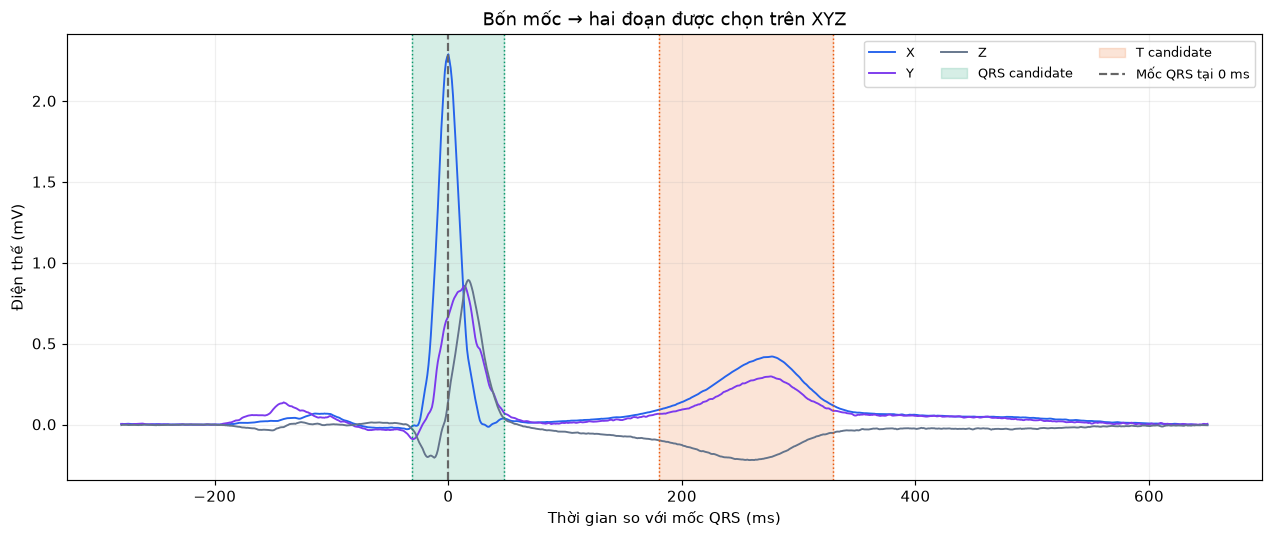

Cờ phân đoạn: Không có cờ heuristic; vẫn cần xem bằng mắt.


In [23]:
names=['qrs_on','qrs_off','t_on','t_peak','t_off']
boundary_table=pd.DataFrame([{'mốc':name,'chỉ số trong median beat':boundaries[name],
    'thời gian (ms)':np.nan if boundaries[name] is None else t[boundaries[name]]} for name in names])
display(boundary_table)
fig,ax=plt.subplots(figsize=(12,5),layout='constrained')
draw_xyz(ax,t,rep_xyz);shade(ax,t,boundaries)
ax.axvline(0,color='.4',ls='--',label='Mốc QRS tại 0 ms')
ax.set(xlabel='Thời gian so với mốc QRS (ms)',title='Bốn mốc → hai đoạn được chọn trên XYZ')
ax.legend(ncol=3,fontsize=9);finish(fig)
print('Cờ phân đoạn:', boundaries['flags'] or 'Không có cờ heuristic; vẫn cần xem bằng mắt.')

## Bước 17 — Cắt mảng thật sự: từ hai vùng màu thành hai tập điểm

**Đầu vào:** `rep_xyz` và các chỉ số biên. Thời gian ms dùng để đọc hình; Python slice dùng **chỉ số mẫu**.

**Thao tác:**

```python
qrs_loop = rep_xyz[qrs_on:qrs_off + 1]
t_loop   = rep_xyz[t_on:t_off + 1]
```

**Đầu ra:** mỗi loop vẫn có ba cột X/Y/Z. Chỉ số tương đối trong median beat khác chỉ số tuyệt đối của recording. Ví dụ, ở fs=1000 Hz và anchor=280, chỉ số 249 ứng với −31 ms, không phải 249 ms sau R.

`+1` giữ cả mẫu cuối vì điểm dừng của Python slice không được lấy. Nếu thiếu biên hoặc thứ tự sai, loop để `None`, không tạo một đoạn giả.

In [24]:
qrs_loop = cut_loop(rep_xyz,boundaries['qrs_on'],boundaries['qrs_off'])
t_loop = cut_loop(rep_xyz,boundaries['t_on'],boundaries['t_off'])
for name,loop,on,off in [('QRS',qrs_loop,'qrs_on','qrs_off'),('T',t_loop,'t_on','t_off')]:
    if loop is None:
        print(name,': chưa có biên hợp lệ');continue
    lo,hi=boundaries[on],boundaries[off]
    print(f'{name}: slice [{lo}:{hi+1}], shape {loop.shape}; {t[lo]:.0f} → {t[hi]:.0f} ms')
    ix=np.unique(np.r_[np.arange(min(3,len(loop))),np.arange(max(0,len(loop)-3),len(loop))])
    display(pd.DataFrame({'hàng trong loop':ix,'sample median beat':lo+ix,'thời gian (ms)':t[lo+ix],
                          'X (mV)':loop[ix,0],'Y (mV)':loop[ix,1],'Z (mV)':loop[ix,2]}))

QRS: slice [249:329], shape (80, 3); -31 → 48 ms


,hàng trong loop,sample median beat,thời gian (ms),X (mV),Y (mV),Z (mV)
0,0,249,-31.0,-0.009676,-0.088594,-0.028198
1,1,250,-30.0,-0.006226,-0.089616,-0.035356
2,2,251,-29.0,-0.004521,-0.086923,-0.045131
3,77,326,46.0,0.037098,0.091769,0.053567
4,78,327,47.0,0.037117,0.079881,0.044174
5,79,328,48.0,0.037493,0.069964,0.038042


T: slice [460:610], shape (150, 3); 180 → 329 ms


,hàng trong loop,sample median beat,thời gian (ms),X (mV),Y (mV),Z (mV)
0,0,460,180.0,0.091519,0.066967,-0.096372
1,1,461,181.0,0.093122,0.066911,-0.097712
2,2,462,182.0,0.094415,0.066788,-0.099422
3,147,607,327.0,0.127642,0.095128,-0.051389
4,148,608,328.0,0.123869,0.090180,-0.051133
5,149,609,329.0,0.120047,0.086133,-0.051761


## Bước 18 — Nối các hàng XYZ theo thời gian thành loop 3D

**Đầu vào:** hai mảng vừa cắt. Mỗi hàng là một điểm trong không gian điện thế.

**Thao tác:** nối hàng 0 → hàng 1 → hàng 2 → … theo đúng thứ tự. Không sắp xếp điểm theo X/Y/Z vì sẽ phá quỹ đạo thời gian.

**Đầu ra:** QRS loop và T loop 3D. Chấm tròn là điểm đầu, dấu × là điểm cuối; chúng không buộc trùng nhau nên loop đo được có thể chưa kín hoàn toàn.

Hai hình dùng cùng giới hạn trục để không phóng đại loop nhỏ hơn. Một đường 3D nhìn trên màn hình có thể chồng nét do góc nhìn; không có nghĩa các thời điểm giống nhau.

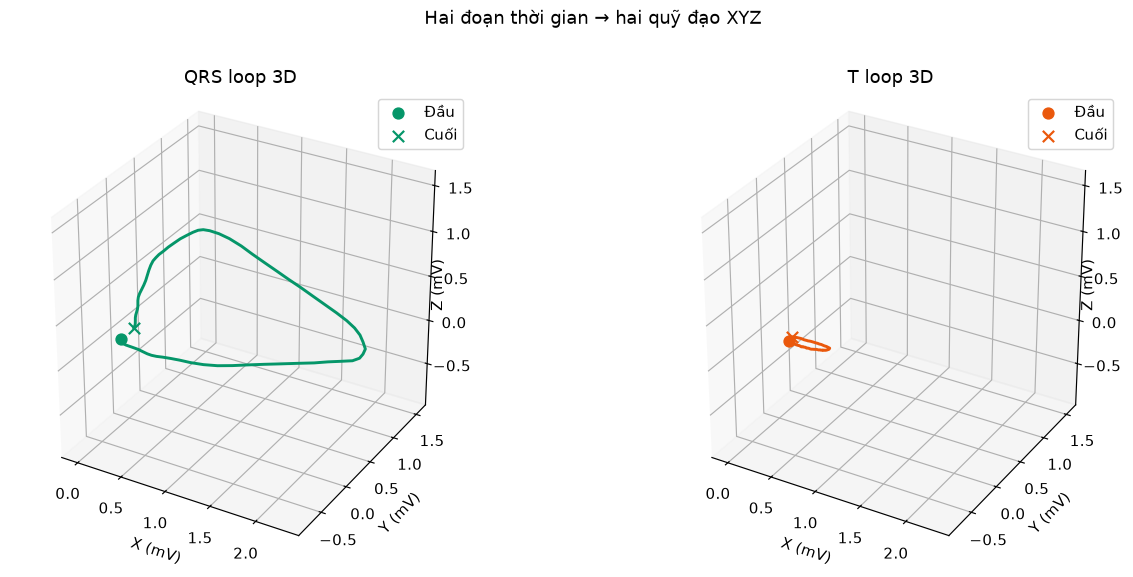

In [25]:
available=[p for p in [qrs_loop,t_loop] if p is not None]
fig=plt.figure(figsize=(13,6))
fig.subplots_adjust(left=.04,right=.92,wspace=.18,top=.85,bottom=.12)
if available:
    points=np.vstack(available);low=points.min(axis=0);high=points.max(axis=0)
    center=(low+high)/2;radius=max((high-low).max()/2,1e-3)*1.15
for pos,loop,color,name in [(1,qrs_loop,QRS_COLOR,'QRS'),(2,t_loop,T_COLOR,'T')]:
    ax=fig.add_subplot(1,2,pos,projection='3d')
    if loop is not None:
        ax.plot(loop[:,0],loop[:,1],loop[:,2],color=color,lw=2)
        ax.scatter(*loop[0],color=color,s=55,marker='o',label='Đầu')
        ax.scatter(*loop[-1],color=color,s=60,marker='x',label='Cuối')
        ax.legend();ax.set_xlim(center[0]-radius,center[0]+radius);ax.set_ylim(center[1]-radius,center[1]+radius);ax.set_zlim(center[2]-radius,center[2]+radius)
        ax.set_box_aspect((1,1,1))
    ax.set(xlabel='X (mV)',ylabel='Y (mV)',zlabel='',title=name+' loop 3D')
    ax.text2D(.93,.58,'Z (mV)',transform=ax.transAxes,rotation=90,ha='center',va='center')
fig.suptitle('Hai đoạn thời gian → hai quỹ đạo XYZ')
finish(fig)

## Bước 19 — Chiếu X–Y và PCA là hai thao tác khác nhau

**Đầu vào:** loop 3D đã tách; bước chiếu không tìm lại biên.

**Chiếu Frank X–Y:** lấy hai cột X/Y, bỏ Z. Vị trí tương đối QRS/T vẫn cùng hệ tọa độ PQ; vòng có thể nhìn hẹp nếu biến thiên nhiều ở Z.

**PCA riêng:** trừ tâm của loop, chọn hai hướng vuông góc giữ nhiều biến thiên nhất rồi chiếu xuống mặt phẳng đó. Dùng PCA để tính Arc/Area. PC1/PC2 không phải X/Y. Mỗi loop có hệ PCA riêng, vì vậy không dùng hai hình PCA để đo vị trí tương đối hoặc góc QRS–T.

**Đầu ra:** mảng `(n,2)` của từng loop. Trong hình, XYZ và X–Y dùng gốc chung; hai hình PCA đặt riêng. Phương sai giữ lại mô tả phép chiếu, không phải độ chính xác phân đoạn.

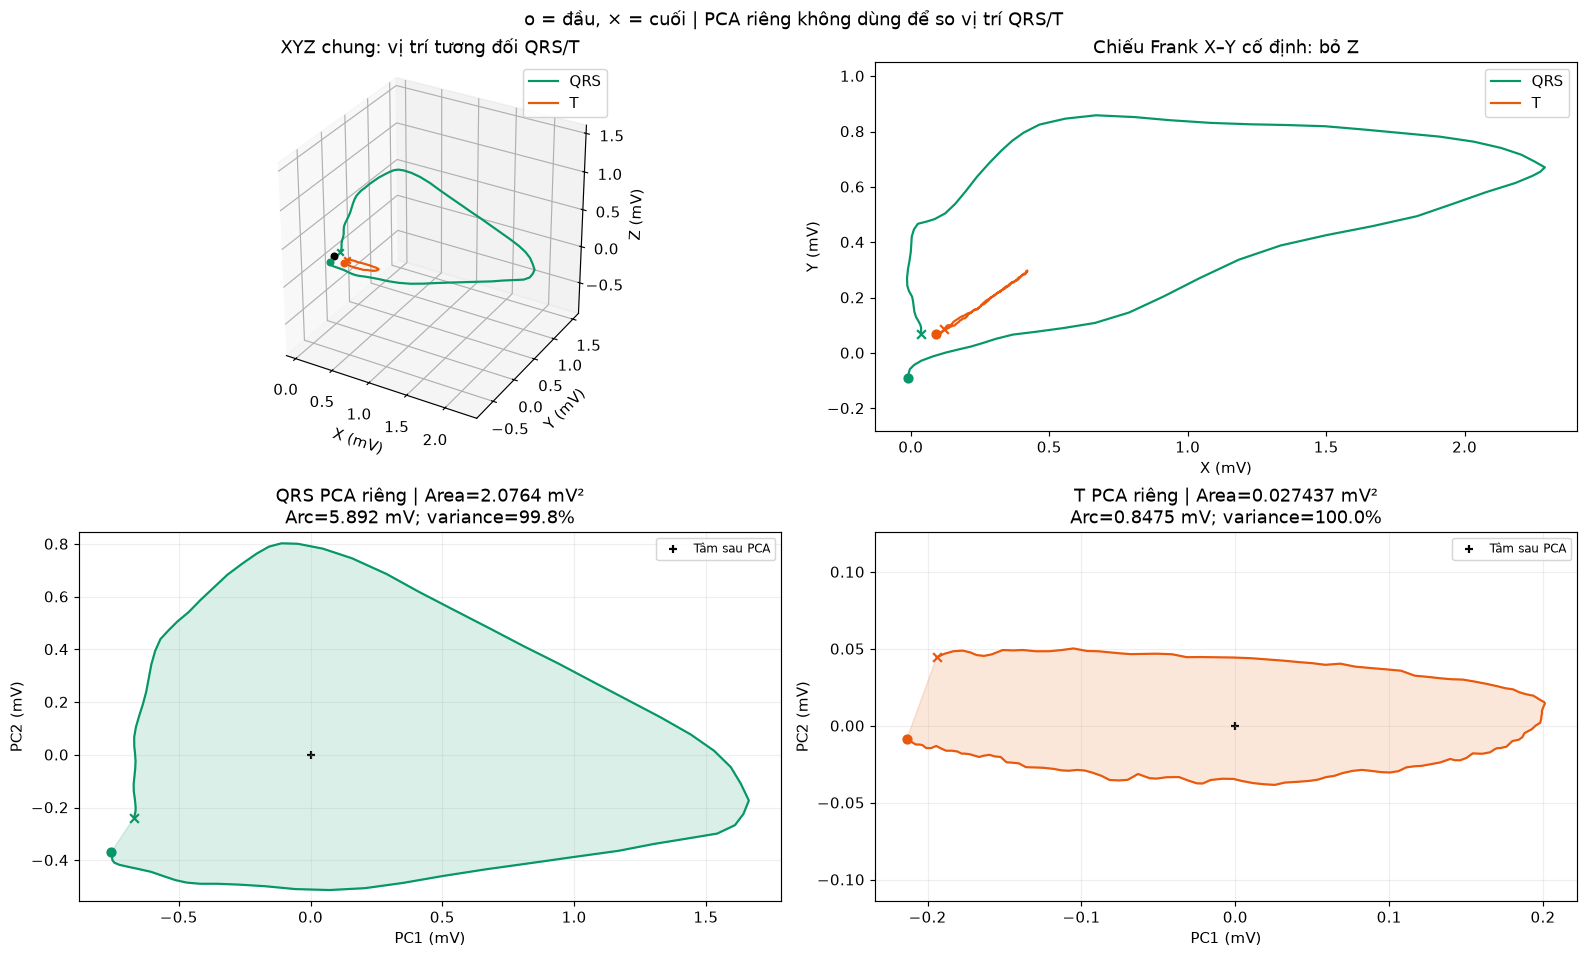

QRS tâm XYZ trước PCA: [0.6441 0.3806 0.2396]


,hệ số X,hệ số Y,hệ số Z
PC1,0.965901,0.258405,0.016183
PC2,-0.155593,0.529364,0.834005


Shape sau chiếu: (80, 2) | variance: 99.82 %
T tâm XYZ trước PCA: [ 0.2629  0.1812 -0.1528]


,hệ số X,hệ số Y,hệ số Z
PC1,0.779409,0.548673,-0.302455
PC2,0.217998,0.215088,0.951953


Shape sau chiếu: (150, 2) | variance: 99.96 %


In [26]:
plot_result={'qrs_loop':qrs_loop,'t_loop':t_loop}
finish(plot_loops(plot_result))
for name,loop in [('QRS',qrs_loop),('T',t_loop)]:
    projection=project_pca(loop)
    if projection is None:continue
    model=projection['model']
    print(name,'tâm XYZ trước PCA:',np.round(model.mean_,4))
    display(pd.DataFrame(model.components_,index=['PC1','PC2'],columns=['hệ số X','hệ số Y','hệ số Z']))
    print('Shape sau chiếu:',projection['xy'].shape,'| variance:',round(projection['variance']*100,2),'%')

## Bước 20 — Từ hai loop đến 12 đặc trưng

**Đầu vào:** hai loop XYZ, hình chiếu PCA và tốc độ trên toàn median beat.

**Thao tác:**

| Đặc trưng | Đo gì | Dữ liệu | Đơn vị |
|---|---|---|---|
| Arc | Tổng độ dài đoạn nối theo thời gian | PCA 2D | mV |
| Area | Diện tích shoelace, đóng cuối về đầu | PCA 2D | mV² |
| MaxVec | Điểm xa gốc PQ nhất | XYZ | mV |
| MaxCentroidDistance | Điểm xa tâm loop nhất | XYZ, chỉ QRS | mV |
| Max/Mean/StdVel | Tốc độ lớn nhất/trung bình/biến thiên | Đạo hàm XYZ | mV/s |

**Đầu ra:** 7 feature QRS + 5 feature T cho một recording. QRS có Arc và MaxCentroidDistance; T không có hai feature này trong bộ 12.

Area không phải diện tích mô tim. Với quỹ đạo tự cắt, shoelace cho trị tuyệt đối diện tích đại số, không bảo đảm bằng tổng mọi vùng tô. Arc ở đây không thêm đoạn đóng vòng. Vận tốc lấy trên toàn median beat rồi mới cắt, tránh tính đạo hàm độc lập tại mép mỗi loop.

In [27]:
loop_speeds={name:None if loop is None else speed[boundaries[on]:boundaries[off]+1]
    for name,loop,on,off in [('QRS',qrs_loop,'qrs_on','qrs_off'),('T',t_loop,'t_on','t_off')]}
features = extract_features(qrs_loop,t_loop,fs,CFG,speeds=loop_speeds)
display(pd.DataFrame([{'feature':name,'giá trị candidate':features[name],
    'đơn vị':'mV²' if name.endswith('Area') else ('mV/s' if name.endswith('Vel') else 'mV')}
    for name in FEATURE_NAMES]))

,feature,giá trị candidate,đơn vị
0,QRS_Arc,5.892343,mV
1,QRS_Area,2.076441,mV²
2,QRS_MaxVec,2.391030,mV
3,QRS_MaxCentroidDistance,1.673200,mV
4,QRS_MaxVel,170.154227,mV/s
5,QRS_MeanVel,74.685192,mV/s
6,QRS_StdVel,48.794393,mV/s
7,T_MaxVec,0.552880,mV
8,T_Area,0.027437,mV²
9,T_MaxVel,11.059858,mV/s


## Bước 21 — Kiểm tra kết quả trước khi coi là feature dùng được

**Đầu vào:** toàn bộ detector, median beat và biên. Có thể tính được feature vẫn chưa đồng nghĩa đã cắt đúng đoạn.

**Thao tác:** kiểm tra RR, số beat, tỷ lệ loại beat, thứ tự/duration của biên, mức ST, độ yên TP, T nhiều lobe và bất đồng tiếp tuyến/ngưỡng. Bảng bên dưới là QC của chính record đang theo dõi.

**Đầu ra:** `auto_candidate`, `needs_review`, hoặc `manual_reviewed` nếu có biên đã sửa bằng tay. `auto_candidate` chỉ có nghĩa chưa vi phạm các quy tắc được cài đặt, không có nghĩa đã khớp annotation chuẩn.

| Cờ thường gặp | Bạn cần xem gì |
|---|---|
| `st_level_requires_review` | Mức ST khác PQ; xem lại vị trí T-on và baseline |
| `t_end_methods_disagree` | Tiếp tuyến và ngưỡng chọn cuối T khác nhiều |
| `t_off_no_baseline_return` | Không tìm được đoạn về nền rõ trong vùng T |
| `qrs_on/off_not_found` | Không có đoạn yên đủ dài để xác định biên QRS |
| `rr_irregular`, `possible_missed_beat` | Detector hoặc nhịp không đều; xem recording |
| `features_incomplete` | Có loop thiếu/không đủ mẫu; không ép đủ 12 số |

Đổi record MI ở ô cấu hình rồi Run All sẽ cho thấy cùng thuật toán có thể gặp hình thái khác. Cần kiểm tra lại tất cả hình, không chỉ bảng feature.

In [28]:
complete_result=process_record(DATA_ROOT/RECORD_ID,CFG)
display(pd.DataFrame([qc_row(complete_result)]))
print('Cờ QC:',complete_result['flags'] or 'Không có cờ heuristic')
print('Qua QC nội bộ:',complete_result['eligible_for_features'])
print('Tổng hợp: nhịp phát hiện',len(anchors),'; beat giữ',rep['n_used'],
      '; QRS samples',None if qrs_loop is None else len(qrs_loop),
      '; T samples',None if t_loop is None else len(t_loop))

,record_id,diagnosis,status,eligible_for_features,n_qrs_detected,n_beats_used,median_rr_ms,t_method,flags,qrs_on_ms,...,morphology_mode,notch_q,powerline_X_status,powerline_X_score_db,powerline_Y_status,powerline_Y_score_db,powerline_Z_status,powerline_Z_score_db,pq_tp_vector_offset_mV,note
0,patient104/s0306lre,Healthy control,auto_candidate,True,31,29,956.0,tangent_on+tangent_end,,-31.0,...,fir,50.0,noise_not_detected,0.424362,noise_not_detected,7.068274,noise_not_detected,-0.552792,0.078299,Offset PQ–TP có thể là drift/tail T; không phả...


Cờ QC: Không có cờ heuristic
Qua QC nội bộ: True
Tổng hợp: nhịp phát hiện 31 ; beat giữ 29 ; QRS samples 80 ; T samples 150


## Bước 22 — So sánh với một ca MI trên cùng cách xử lý

Ô này minh họa vì sao ca bệnh lý cần QC ngay cả khi code vẫn tạo được hai vùng màu. Đây chỉ là một ví dụ; không dùng hai record để kết luận hiệu quả phân loại.

Xem vùng xanh có bao cả các sườn QRS không, vùng cam bắt đầu/kết thúc ở đâu so với hình sóng T, và mức ST/PQ. Nếu có cờ ST, T-on theo tiếp tuyến cần xem lại; feature vẫn là candidate.

,record_id,diagnosis,status,eligible_for_features,n_qrs_detected,n_beats_used,median_rr_ms,t_method,flags,qrs_on_ms,...,morphology_mode,notch_q,powerline_X_status,powerline_X_score_db,powerline_Y_status,powerline_Y_score_db,powerline_Z_status,powerline_Z_score_db,pq_tp_vector_offset_mV,note
0,patient104/s0306lre,Healthy control,auto_candidate,True,31,29,956.0,tangent_on+tangent_end,,-31.0,...,fir,50.0,noise_not_detected,0.424362,noise_not_detected,7.068274,noise_not_detected,-0.552792,0.078299,Offset PQ–TP có thể là drift/tail T; không phả...
1,patient001/s0010_re,Myocardial infarction,needs_review,False,41,39,732.0,tangent_on+tangent_end,st_level_requires_review,-66.0,...,fir,50.0,noise_not_detected,3.665800,noise_not_detected,9.683078,noise_not_detected,2.822626,0.063400,Offset PQ–TP có thể là drift/tail T; không phả...


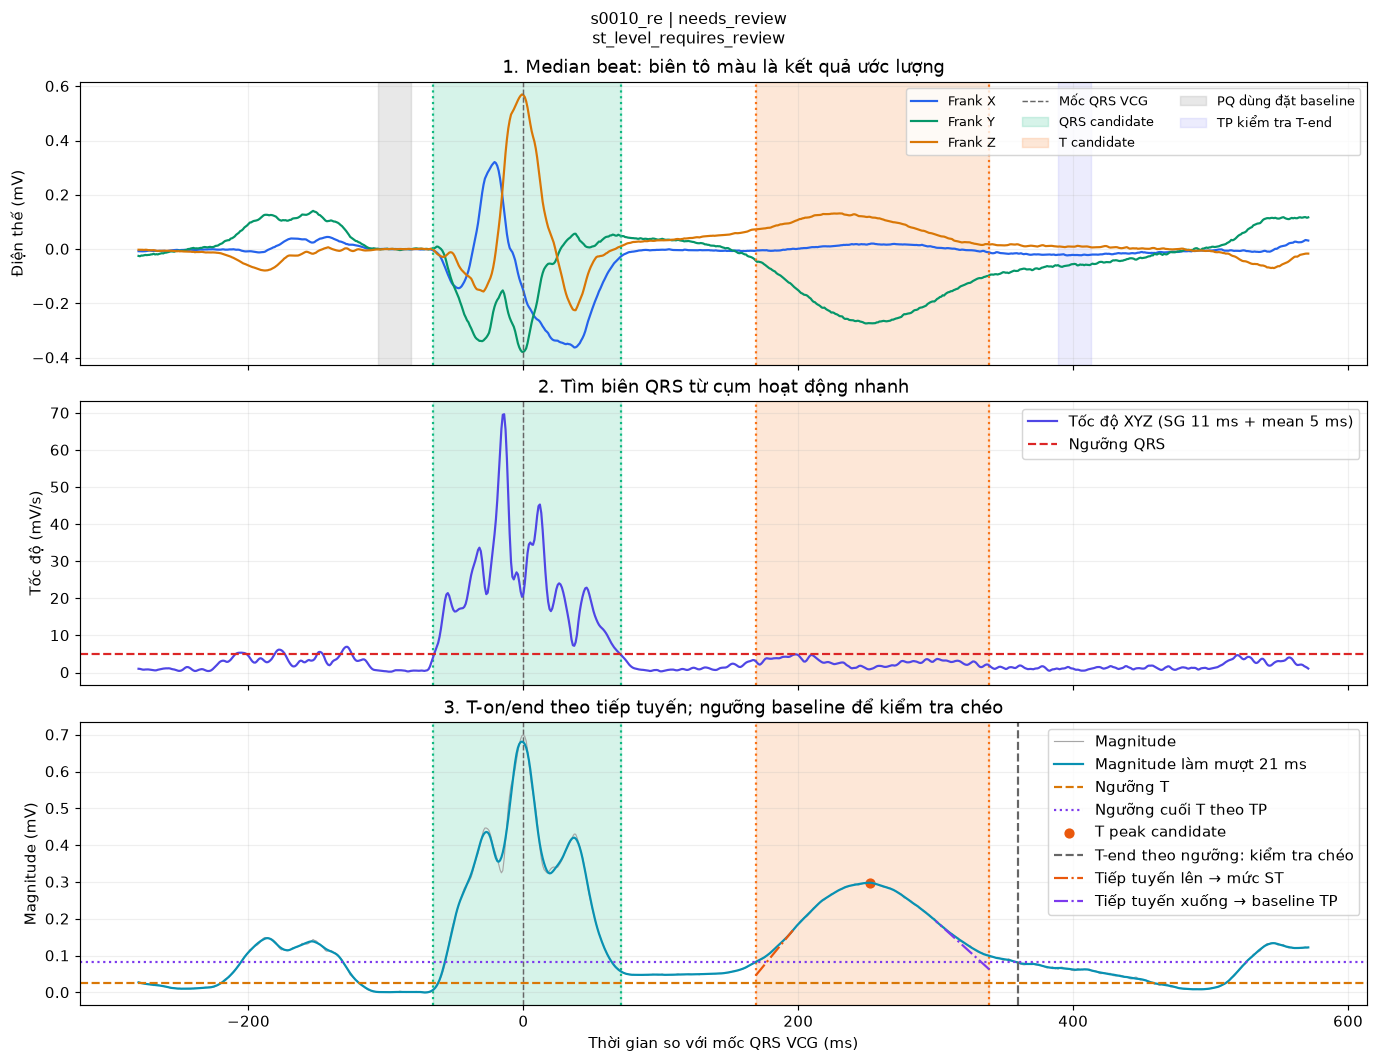

In [29]:
COMPARISON_RECORD = 'patient001/s0010_re'
comparison=process_record(DATA_ROOT/COMPARISON_RECORD,CFG)
display(pd.DataFrame([qc_row(complete_result),qc_row(comparison)]))
finish(plot_delineation(comparison))

## Bản đồ toàn bộ thao tác

| Sau bước nào | Đối tượng đang có | Đã là loop chưa? |
|---|---|---|
| Đọc/lọc | Recording XYZ nhiều nhịp | Chưa |
| Detector | Danh sách thời điểm QRS | Chưa |
| Cắt beat | Nhiều cửa sổ quanh các mốc | Chưa |
| Median | Một beat đại diện | Chưa |
| Phân đoạn | Bốn chỉ số QRS_on/off, T_on/off | Chưa cắt mảng |
| Cắt XYZ | Hai mảng `(n_QRS,3)` và `(n_T,3)` | Có |
| Nối/vẽ | Hai quỹ đạo theo thứ tự thời gian | Có |
| PCA/feature | Hình chiếu và 12 con số | Loop đã được tạo từ trước |

Mấu chốt: **vận tốc và magnitude giúp tìm bốn mốc; XYZ trong hai khoảng đó mới tạo thành hai loop.**

Các hàm nền dùng chung notebook 04, với tiền xử lý có điều kiện và QC giữ hình thái khác thường. Xem nguồn và phạm vi kiểm chứng ở notebook 04: detector energy/speed và các ngưỡng cụ thể là implementation của project, không phải bản sao một thuật toán đã có số liệu validation. Walkthrough theo một record; các mục kiểm chứng riêng chạy thí nghiệm và lưu kết quả vào thư mục riêng. Không ghi đè vcg_12_features.csv hoặc thay logic ML/nhãn của pipeline cũ.

## Đánh giá bộ lọc — A cũ, B FIR/auto, C chưa lọc bổ sung

A: Butterworth 80 Hz + Notch 50 Hz Q=30 luôn bật. B: FIR 401/Kaiser8/cutoff175 + Notch auto Q=50. C: không low-pass/Notch bổ sung. Cả ba dùng cùng detector/phân đoạn/công thức feature và QC mới; A tái hiện bộ lọc cũ, không tái hiện việc loại mọi beat khác hình thái.

**Hai phép kiểm chứng:**

1. `fixed`: dùng cùng anchors, tập beat của B, vùng PQ của từng beat, PQ cuối của median và bốn biên B. Như vậy thay đổi feature chủ yếu phản ánh XYZ sau lọc, không lẫn việc chọn lại mốc/PQ.
2. `full`: chạy lại A/B/C; anchors, beat/PQ và biên có thể khác. Bảng thời gian tính theo mốc căn nhịp của từng nhánh, nên phải đọc cùng số mốc và số beat.

**Hình:** XYZ mV/tốc độ mV/s theo ms; loops 3D có tọa độ điện thế mV, dùng chung thang A/B/C trong mỗi ô. Vùng tô là biên B để tham chiếu. **Bảng feature:** giá trị, sai khác tuyệt đối và phần trăm so với C; khi C gần 0 hoặc thiếu dữ liệu, % để NaN. Gần C không tự chứng minh đúng vì C có thể còn nhiễu.

patient104/s0306lre | errors: {}


config,A_legacy,B_fir_auto,C_unfiltered
n_qrs_detected,31,31,31
n_beats_used,29,29,29
qrs_on_ms,-31.0,-31.0,-31.0
qrs_off_ms,48.0,48.0,48.0
t_on_ms,179.0,180.0,180.0
t_off_ms,330.0,329.0,330.0
notch_applied,True,False,False
powerline_status,noise_not_detected,noise_not_detected,noise_not_detected
flags,,,


,config,axis,rms_difference_uV,50_band_density_after,high_frequency_density_after,notch_applied,powerline_status
0,A_legacy,X,4.497228,3.131073e-07,2.456978e-17,True,noise_not_detected
1,A_legacy,Y,4.679424,1.427524e-07,5.365838e-17,True,noise_not_detected
2,A_legacy,Z,3.156059,3.340094e-08,3.989849e-17,True,noise_not_detected
3,B_fir_auto,X,1.350563,7.293227e-06,3.595712e-21,False,noise_not_detected
4,B_fir_auto,Y,1.828038,6.625903e-06,1.389067e-20,False,noise_not_detected
5,B_fir_auto,Z,1.495433,7.562849e-07,7.255110e-21,False,noise_not_detected
6,C_unfiltered,X,0.000000,7.293219e-06,4.951320e-09,False,noise_not_detected
7,C_unfiltered,Y,0.000000,6.625906e-06,1.025751e-08,False,noise_not_detected
8,C_unfiltered,Z,0.000000,7.562841e-07,6.944500e-09,False,noise_not_detected


Comparison: fixed


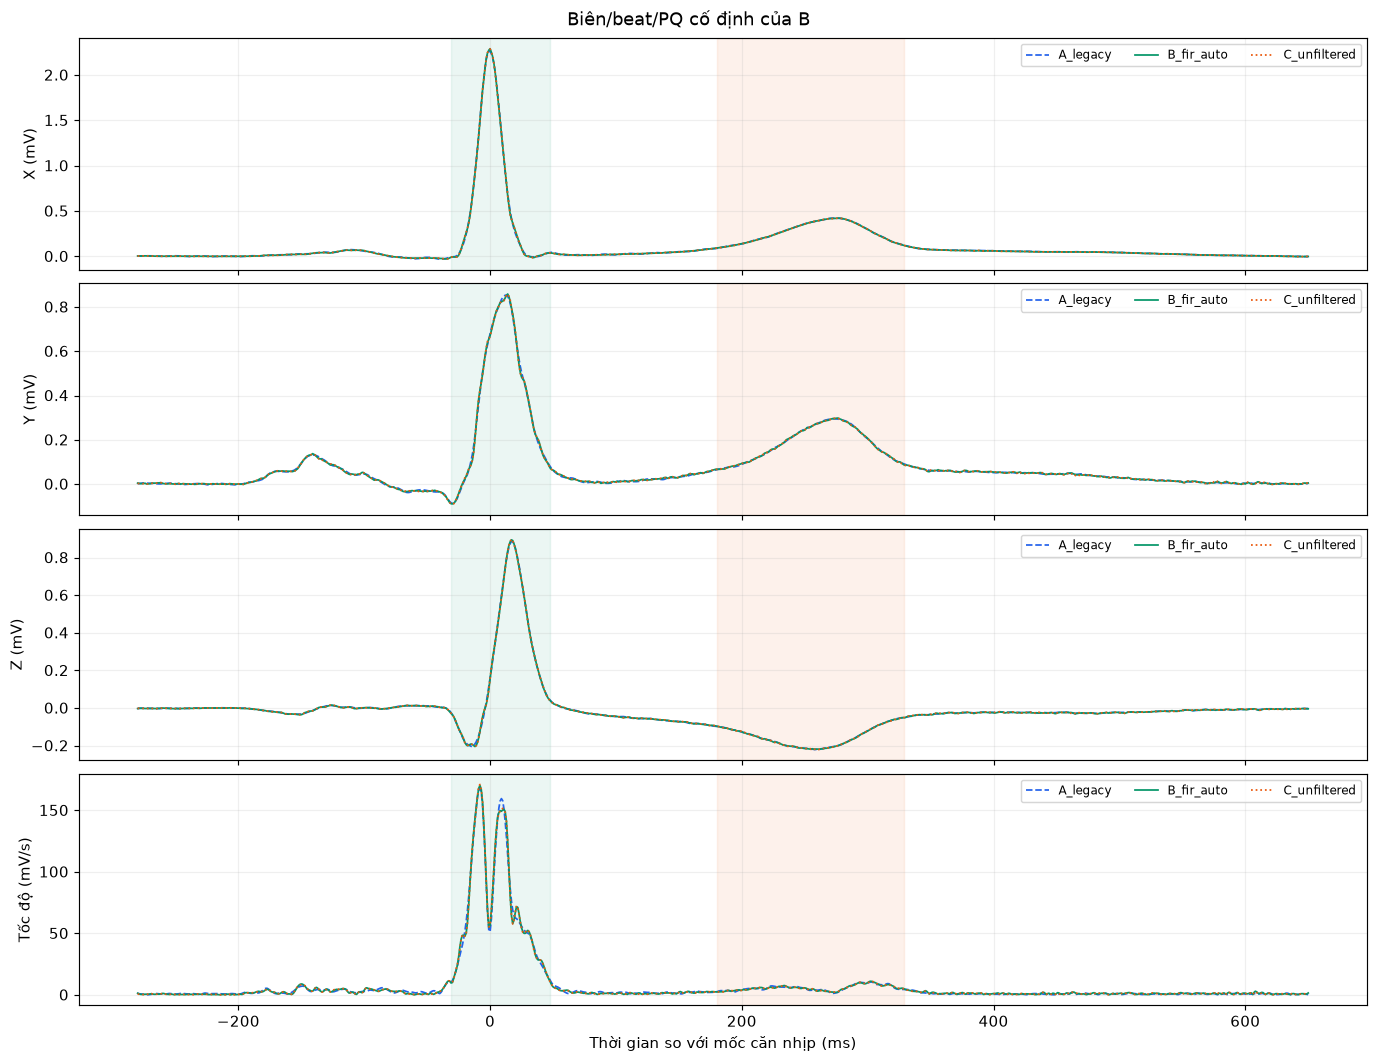

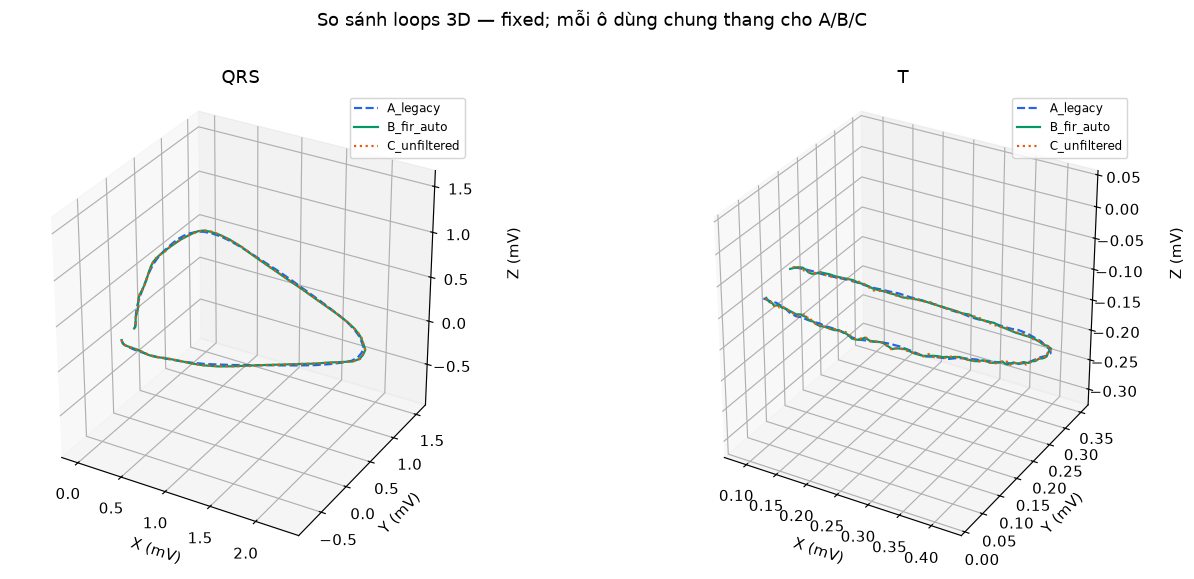

config,A_legacy,B_fir_auto,C_unfiltered
feature,,,
QRS_Arc,5.841190,5.892343,5.898856
QRS_Area,2.082491,2.076441,2.077660
QRS_MaxVec,2.373341,2.391030,2.388193
QRS_MaxCentroidDistance,1.653685,1.673200,1.670250
QRS_MaxVel,167.803545,170.154227,171.001397
QRS_MeanVel,73.855235,74.685192,74.730826
QRS_StdVel,48.573004,48.794393,48.787826
T_MaxVec,0.554033,0.552880,0.553483
T_Area,0.027520,0.027437,0.027420


,config,feature,absolute_change,relative_change_pct
0,A_legacy,QRS_Arc,0.057666,-0.977585
1,A_legacy,QRS_Area,0.004830,0.232493
2,A_legacy,QRS_MaxVec,0.014852,-0.621877
3,A_legacy,QRS_MaxCentroidDistance,0.016565,-0.991781
4,A_legacy,QRS_MaxVel,3.197852,-1.870073
5,A_legacy,QRS_MeanVel,0.875591,-1.171659
6,A_legacy,QRS_StdVel,0.214822,-0.440318
7,A_legacy,T_MaxVec,0.000550,0.099348
8,A_legacy,T_Area,0.000100,0.365448
9,A_legacy,T_MaxVel,0.435969,-3.983498


Comparison: full


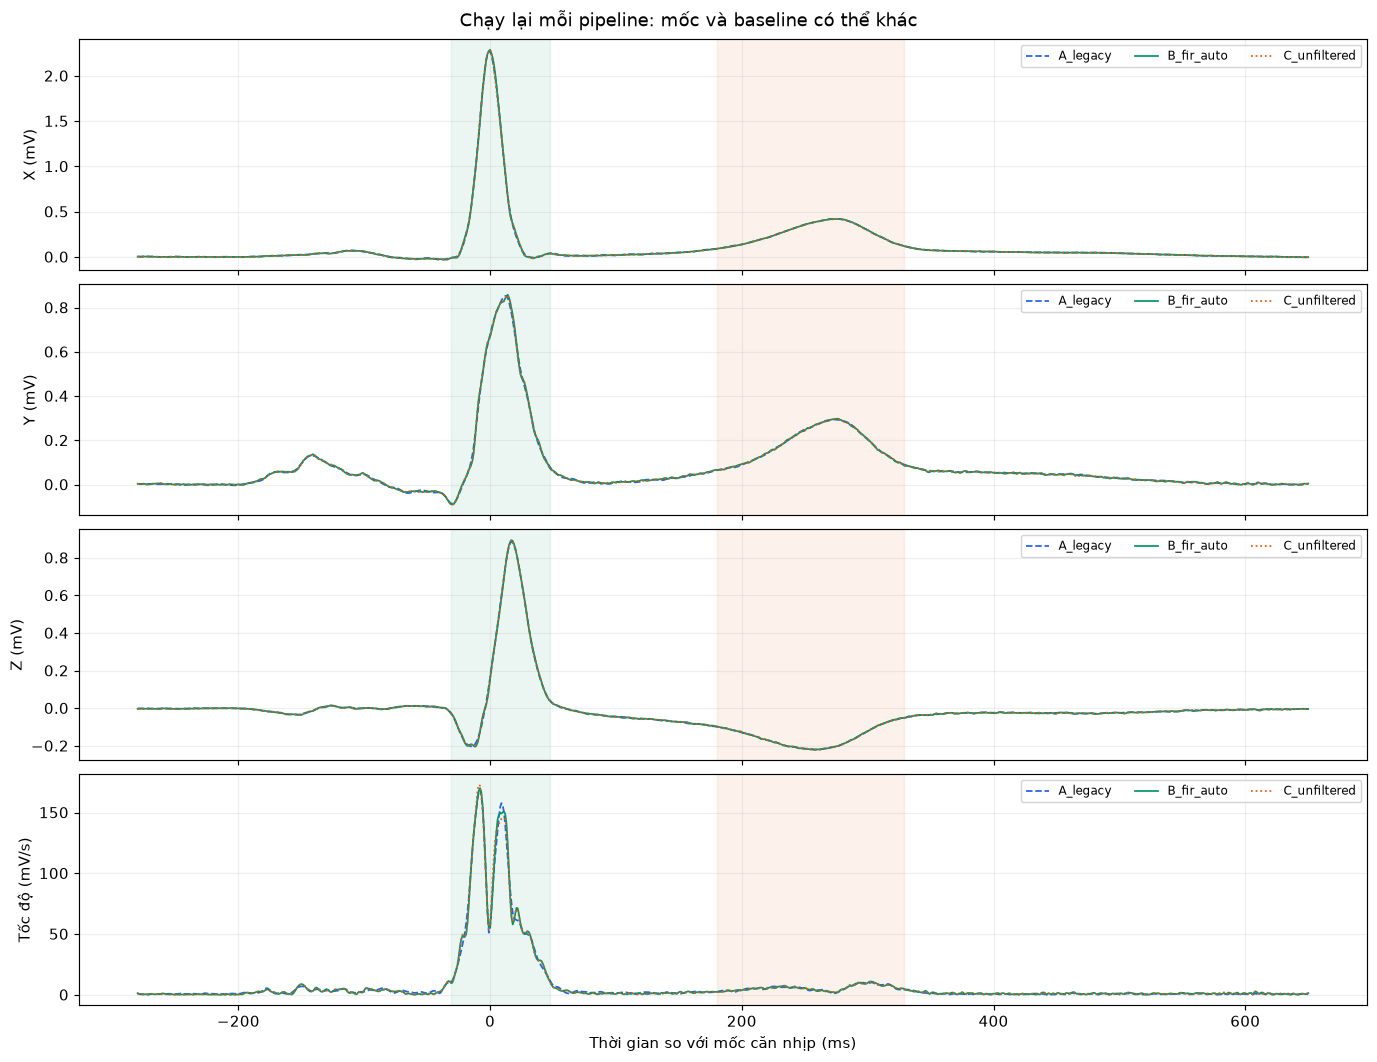

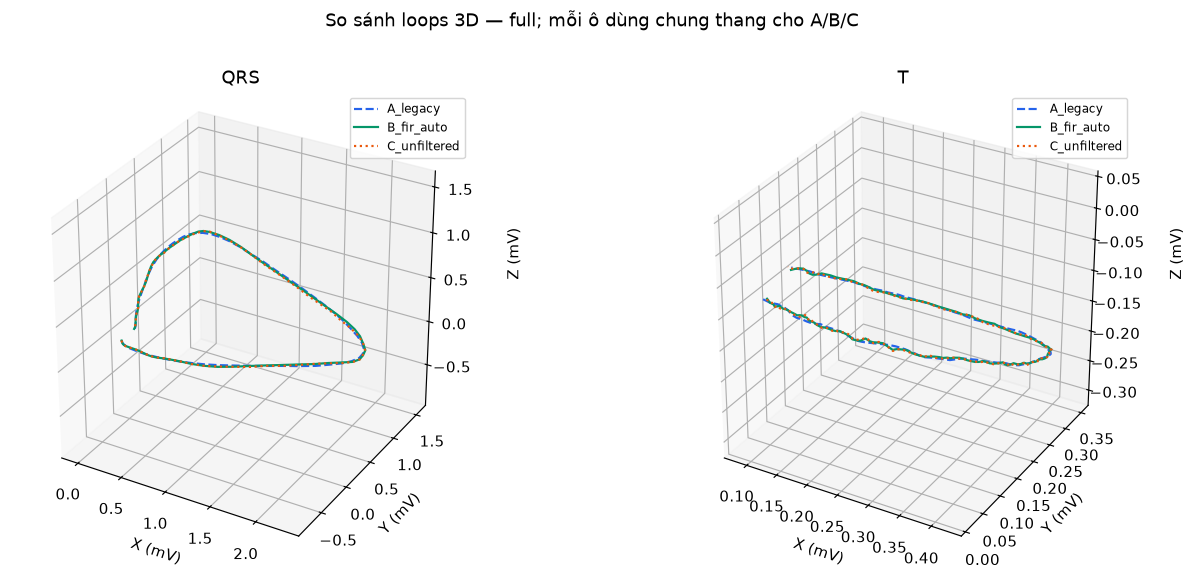

config,A_legacy,B_fir_auto,C_unfiltered
feature,,,
QRS_Arc,5.841023,5.892343,5.884160
QRS_Area,2.076606,2.076441,2.061927
QRS_MaxVec,2.372540,2.391030,2.388193
QRS_MaxCentroidDistance,1.657737,1.673200,1.674091
QRS_MaxVel,168.834116,170.154227,172.949065
QRS_MeanVel,73.825077,74.685192,74.536210
QRS_StdVel,48.331054,48.794393,48.339268
T_MaxVec,0.553950,0.552880,0.553483
T_Area,0.027689,0.027437,0.027329


,config,feature,absolute_change,relative_change_pct
36,A_legacy,QRS_Arc,0.043137,-0.733101
37,A_legacy,QRS_Area,0.014678,0.711863
38,A_legacy,QRS_MaxVec,0.015653,-0.655414
39,A_legacy,QRS_MaxCentroidDistance,0.016354,-0.976906
40,A_legacy,QRS_MaxVel,4.114950,-2.379284
41,A_legacy,QRS_MeanVel,0.711133,-0.954077
42,A_legacy,QRS_StdVel,0.008214,-0.016992
43,A_legacy,T_MaxVec,0.000467,0.084424
44,A_legacy,T_Area,0.000361,1.319371
45,A_legacy,T_MaxVel,0.453908,-4.240552


patient001/s0010_re | errors: {}


config,A_legacy,B_fir_auto,C_unfiltered
n_qrs_detected,41,41,41
n_beats_used,39,39,39
qrs_on_ms,-65.0,-66.0,-66.0
qrs_off_ms,74.0,71.0,69.0
t_on_ms,170.0,169.0,167.0
t_off_ms,335.0,339.0,338.0
notch_applied,True,False,False
powerline_status,noise_not_detected,noise_not_detected,noise_not_detected
flags,st_level_requires_review,st_level_requires_review,st_level_requires_review


,config,axis,rms_difference_uV,50_band_density_after,high_frequency_density_after,notch_applied,powerline_status
0,A_legacy,X,2.728884,2.532294e-08,1.873937e-17,True,noise_not_detected
1,A_legacy,Y,5.558094,1.362589e-08,1.656513e-16,True,noise_not_detected
2,A_legacy,Z,3.494971,8.071168e-08,1.959457e-17,True,noise_not_detected
3,B_fir_auto,X,1.052636,9.132629e-07,8.712826e-22,False,noise_not_detected
4,B_fir_auto,Y,3.081758,6.693123e-06,4.863157e-21,False,noise_not_detected
5,B_fir_auto,Z,1.146627,3.266346e-06,7.161204e-21,False,noise_not_detected
6,C_unfiltered,X,0.000000,9.132629e-07,3.514890e-09,False,noise_not_detected
7,C_unfiltered,Y,0.000000,6.693135e-06,3.043253e-08,False,noise_not_detected
8,C_unfiltered,Z,0.000000,3.266347e-06,4.124770e-09,False,noise_not_detected


Comparison: fixed


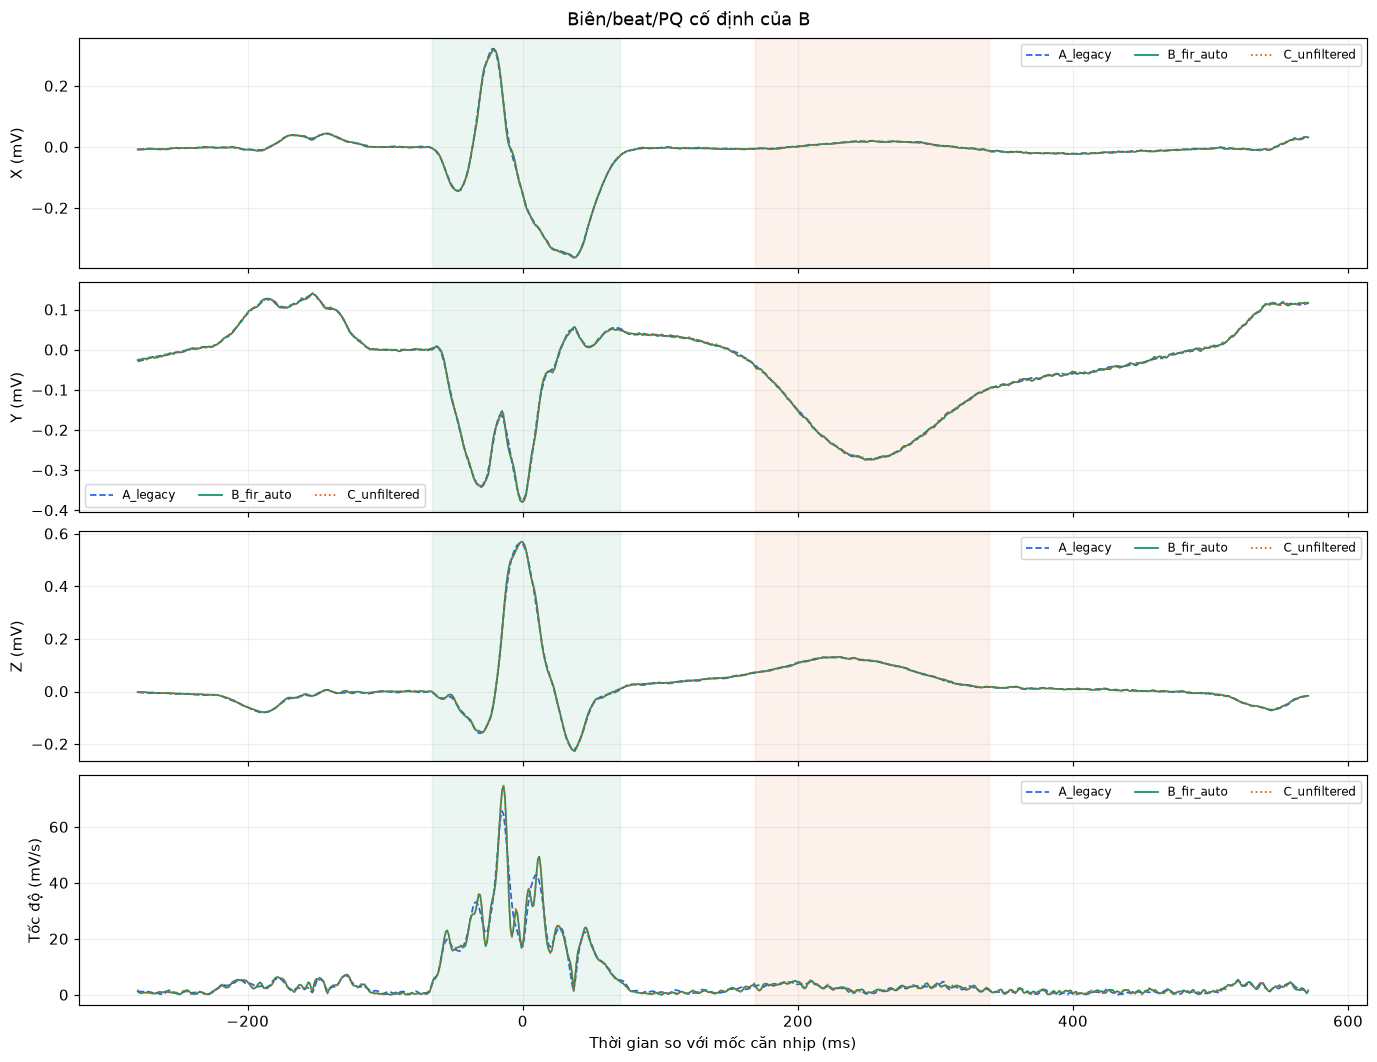

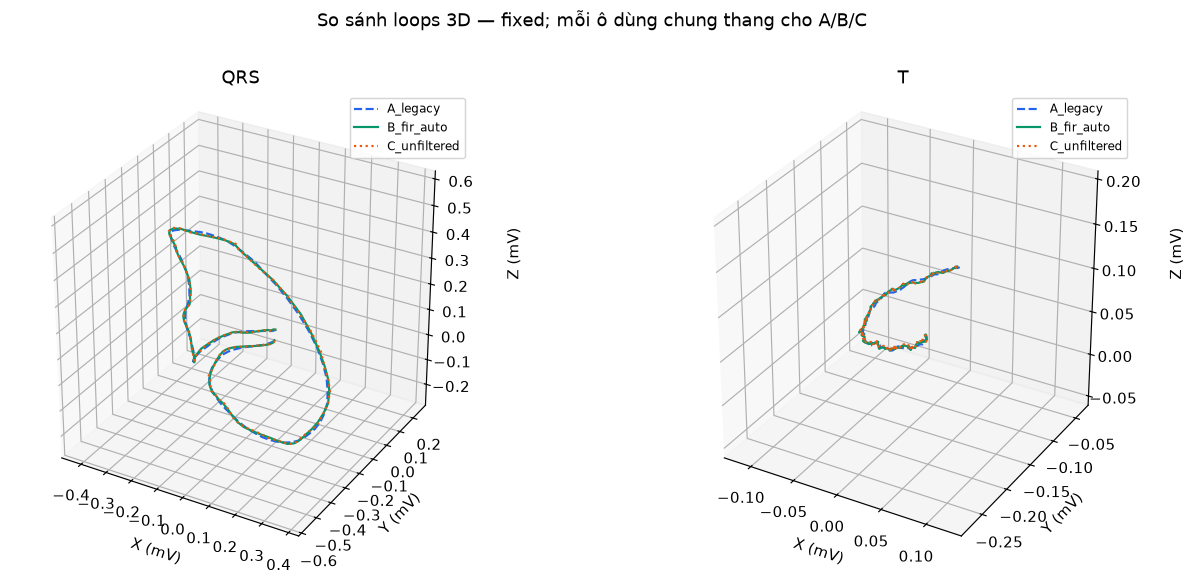

config,A_legacy,B_fir_auto,C_unfiltered
feature,,,
QRS_Arc,2.706865,2.777269,2.790677
QRS_Area,0.274915,0.274356,0.274703
QRS_MaxVec,0.691235,0.699221,0.698745
QRS_MaxCentroidDistance,0.577702,0.583373,0.582569
QRS_MaxVel,65.749576,74.820679,74.696682
QRS_MeanVel,22.943888,23.286680,23.290450
QRS_StdVel,13.486160,14.251230,14.233004
T_MaxVec,0.297528,0.298988,0.299240
T_Area,0.012807,0.012576,0.012502


,config,feature,absolute_change,relative_change_pct
0,A_legacy,QRS_Arc,0.083812,-3.003281
1,A_legacy,QRS_Area,0.000212,0.077094
2,A_legacy,QRS_MaxVec,0.007511,-1.074901
3,A_legacy,QRS_MaxCentroidDistance,0.004868,-0.835558
4,A_legacy,QRS_MaxVel,8.947106,-11.977917
5,A_legacy,QRS_MeanVel,0.346562,-1.488002
6,A_legacy,QRS_StdVel,0.746844,-5.247268
7,A_legacy,T_MaxVec,0.001712,-0.572190
8,A_legacy,T_Area,0.000305,2.438846
9,A_legacy,T_MaxVel,0.302216,-5.963882


Comparison: full


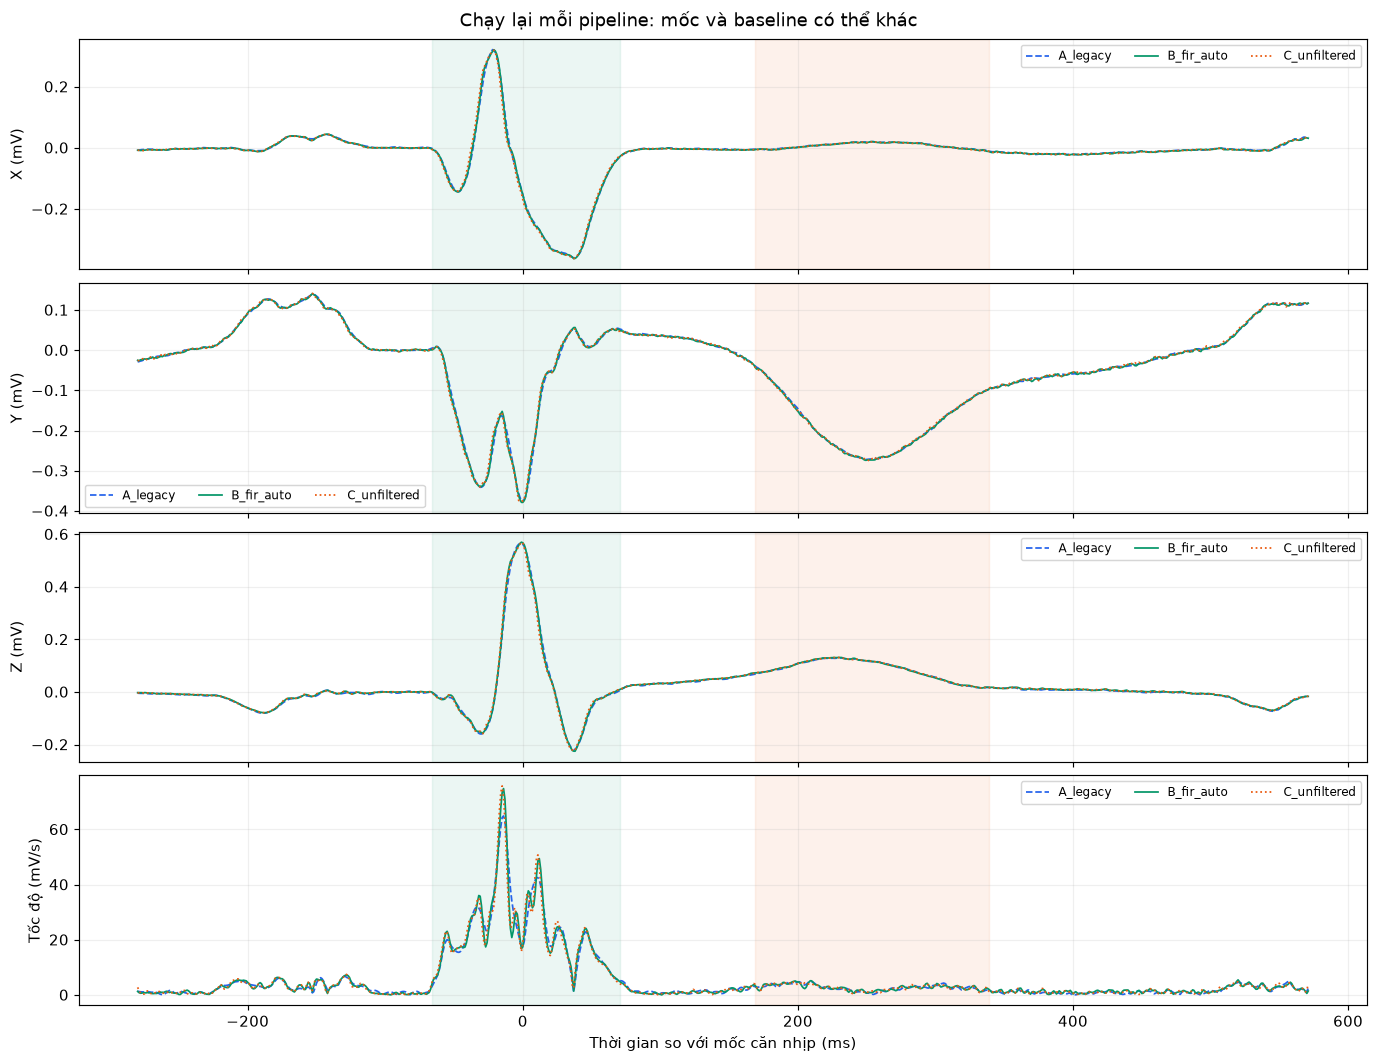

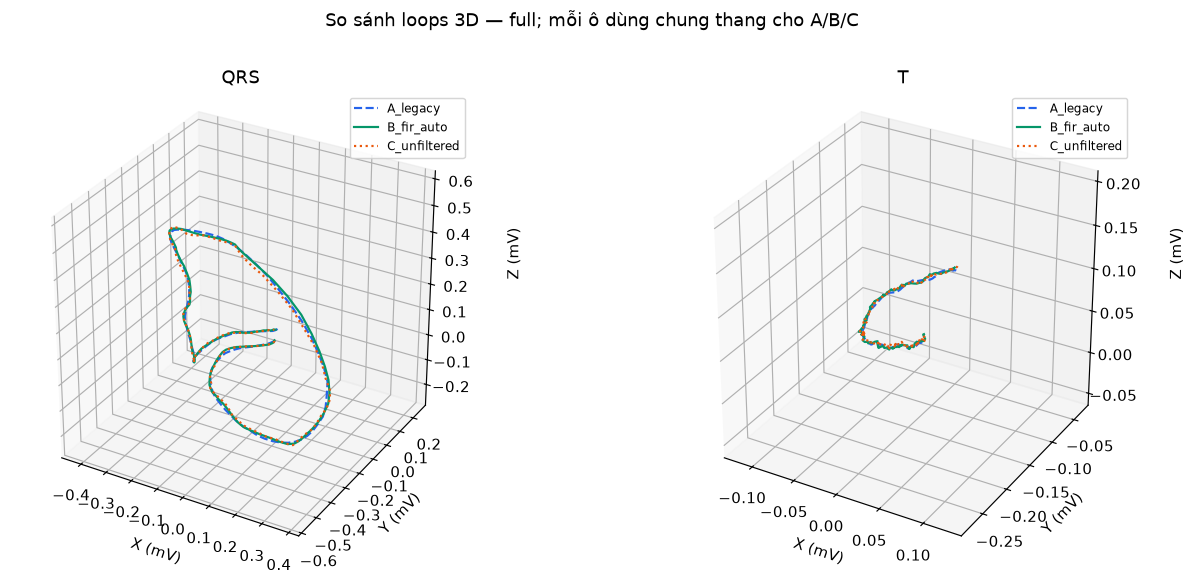

config,A_legacy,B_fir_auto,C_unfiltered
feature,,,
QRS_Arc,2.717899,2.777269,2.772478
QRS_Area,0.271862,0.274356,0.264105
QRS_MaxVec,0.692447,0.699221,0.702636
QRS_MaxCentroidDistance,0.579295,0.583373,0.584030
QRS_MaxVel,64.898797,74.820679,75.782205
QRS_MeanVel,22.652177,23.286680,23.413715
QRS_StdVel,13.472061,14.251230,14.081187
T_MaxVec,0.296954,0.298988,0.300735
T_Area,0.012357,0.012576,0.012535


,config,feature,absolute_change,relative_change_pct
36,A_legacy,QRS_Arc,0.054578,-1.968575
37,A_legacy,QRS_Area,0.007757,2.937218
38,A_legacy,QRS_MaxVec,0.010190,-1.450193
39,A_legacy,QRS_MaxCentroidDistance,0.004735,-0.810781
40,A_legacy,QRS_MaxVel,10.883407,-14.361429
41,A_legacy,QRS_MeanVel,0.761539,-3.252533
42,A_legacy,QRS_StdVel,0.609126,-4.325814
43,A_legacy,T_MaxVec,0.003781,-1.257108
44,A_legacy,T_Area,0.000178,-1.417788
45,A_legacy,T_MaxVel,0.201750,4.187121


Kết quả PTB thật lưu tại: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\vcg_preprocessing_results


In [30]:
preprocessing_comparisons={}
for comparison_record in [RECORD_ID,'patient001/s0010_re']:
    if comparison_record in preprocessing_comparisons:continue
    comparison=compare_preprocessing_configs(DATA_ROOT/comparison_record,CFG)
    preprocessing_comparisons[comparison_record]=comparison
    print(comparison_record,'| errors:',comparison['errors'])
    keep=['config','n_qrs_detected','n_beats_used','qrs_on_ms','qrs_off_ms','t_on_ms','t_off_ms',
          'notch_applied','powerline_status','flags']
    display(comparison['full_qc'][keep].set_index('config').T)
    display(comparison['signal_metrics'])
    for kind in ['fixed','full']:
        print('Comparison:',kind)
        finish(plot_median_config_comparison(comparison,kind))
        finish(plot_3d_config_comparison(comparison,kind))
        values=comparison['feature_values'].query('comparison == @kind')
        display(values.pivot(index='feature',columns='config',values='value').reindex(FEATURE_NAMES))
        display(comparison['feature_changes'].query('comparison == @kind and config != "C_unfiltered"')
                [['config','feature','absolute_change','relative_change_pct']])
output_dir=Path('vcg_preprocessing_results');output_dir.mkdir(exist_ok=True)
for record,comparison in preprocessing_comparisons.items():
    label=record.replace('/','_')
    comparison['full_qc'].to_csv(output_dir/(label+'_qc.csv'),index=False)
    comparison['feature_changes'].to_csv(output_dir/(label+'_feature_changes.csv'),index=False)
    comparison['signal_metrics'].to_csv(output_dir/(label+'_signal_metrics.csv'),index=False)
print('Kết quả PTB thật lưu tại:',output_dir.resolve())

## Kiểm thử tiền xử lý và giới hạn

Các tests A–F trong `tests/test_vcg_preprocessing.py` dùng tín hiệu tổng hợp được ghi rõ là tổng hợp: sạch; sin 50 Hz liên tục; packet 50 Hz ở QRS; không ổn định/thiếu dữ liệu; đáp ứng FIR/Notch hai chiều; shape, NaN, biên và không có beat. Có thêm kiểm tra mode và chỉ Notch riêng trục nghi nhiễu, dữ liệu lỗi, giữ hợp đồng hai mảng và smoke HC/MI.

FIR 401/Kaiser8/cutoff175, Notch Q50, ngưỡng 8 dB/60%, quiet mask và baseline QC đều là lựa chọn nghiên cứu. Các tests này không xác nhận ngưỡng tối ưu trên bệnh nhân. Quiet mask có thể nhầm đoạn ST/T ít dốc; khi không đủ bằng chứng, cần review. High-pass 0,5 Hz không mặc định bật. Feature thay đổi cần đọc cả mức giảm thành phần nghi nhiễu và mức đổi QRS/ST/T.

Thí nghiệm `energy_window_ms` bên dưới giữ nguyên grid/detector/seed và đóng băng bộ lọc cũ qua `WINDOW_PREPROCESSING_CFG=legacy_config(CFG)` để không trộn hai nghiên cứu. 80 **ms** là thời gian làm envelope; 80 **Hz** là cutoff cũ. Dữ liệu tổng hợp 250/500 Hz dùng legacy trong nghiên cứu đó; FIR mới mặc định yêu cầu 1000 Hz.

In [31]:
import unittest
suite=unittest.defaultTestLoader.discover('tests',pattern='test_vcg_preprocessing.py')
test_result=unittest.TextTestRunner(verbosity=2).run(suite)
if not test_result.wasSuccessful():raise RuntimeError('Preprocessing tests failed; không công bố kết quả như đã qua kiểm tra.')

test_E_fir_and_notch_effective_response (test_vcg_preprocessing.TestFilterAndErrors.test_E_fir_and_notch_effective_response) ... ok
test_F_shape_finite_and_invalid_data (test_vcg_preprocessing.TestFilterAndErrors.test_F_shape_finite_and_invalid_data) ... ok
test_different_clean_morphology_is_retained (test_vcg_preprocessing.TestFilterAndErrors.test_different_clean_morphology_is_retained) ... ok
test_fault_detection_not_all_sharp_qrs_are_noise (test_vcg_preprocessing.TestFilterAndErrors.test_fault_detection_not_all_sharp_qrs_are_noise) ... ok
test_legacy_contract_for_window_experiments (test_vcg_preprocessing.TestFilterAndErrors.test_legacy_contract_for_window_experiments) ... ok
test_real_HC_MI_smoke (test_vcg_preprocessing.TestFilterAndErrors.test_real_HC_MI_smoke) ... ok
test_A_clean_no_unnecessary_notch (test_vcg_preprocessing.TestPowerline.test_A_clean_no_unnecessary_notch) ... ok
test_B_continuous_line_and_noise_reduction (test_vcg_preprocessing.TestPowerline.test_B_continuous_lin

### Nguồn và phần do project đề xuất

- [Kligfield et al. 2007](https://www.jacc.org/doi/10.1016/j.jacc.2007.01.024): tham khảo bảo toàn băng thông ECG chẩn đoán; không chứng minh FIR 401/cutoff175 tối ưu cho VCG.
- [Kijonka et al. 2022](https://www.frontiersin.org/journals/physiology/articles/10.3389/fphys.2022.941827/full): paper dùng FIR high-pass và Notch khi có powerline, cùng thuật toán wavelet/PQ. Project giữ PQ và không mặc định dùng high-pass đó.
- [Representative QRS loop, volume 2023, công bố 2024](https://www.frontiersin.org/journals/physiology/articles/10.3389/fphys.2023.1260074/full): tham khảo auto-Notch và bảo toàn ST/T; paper dùng thiết kế FIR khác, không dùng nguyên bộ PSD 8 dB/60% hoặc IIR Q50 ở đây.
- [SciPy firwin](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.firwin.html), [filtfilt](https://docs.scipy.org/doc/scipy/reference/generated/scipy.signal.filtfilt.html): cutoff firwin là half-amplitude; hai chiều có gain |H|². Những con số thực tế ở trên được tính từ hệ số của project.

Notebook 04/05 cùng import `vcg_preprocessing.py`, `vcg_pipeline.py` và `vcg_preprocessing_evaluation.py`; không sao chép hai engine khác nhau. Các notebook 02/03 và script cũ vẫn là phiên bản lịch sử, cần migration riêng trước khi trộn feature/ML. Không thay nhãn HC/MI hoặc công thức 12 feature.

## Bổ sung — Kiểm tra cửa sổ 80 ms bằng nhiều giá trị

Phần này thử **20, 40, 60, 80, 100, 120, 150, 180 và 200 ms** thay vì mặc định coi 80 ms là tối ưu. Giữ nguyên mọi tham số khác; chỉ thay `energy_window_ms`. Phần này đánh giá **phát hiện mốc nhịp**, chưa đánh giá độ chính xác QRS_on/off và T_on/off.

Hai nguồn bằng chứng được tách riêng:

1. **PTB thật:** 30 giây đầu của mọi record MI/HC. Workspace không có annotation nhịp chuẩn được dùng ở đây, nên chỉ đo số mốc, cờ RR và độ đồng thuận giữa các cửa sổ. Đồng thuận không phải độ chính xác.
2. **XYZ tổng hợp:** có đồng hồ nhịp được tạo trước khi chạy detector, nên đo được TP/FP/FN và F1. Đây là mô hình đơn giản, không thay thế validation trên người thật.

Các hình/bảng bên dưới được tính bằng code và lưu sẵn. Không dùng đầu ra 80 ms làm ground truth. Không sửa tín hiệu tổng hợp, tolerance hoặc chọn seed sau khi xem kết quả để ưu tiên 80 ms.

Bộ lọc của nghiên cứu cửa sổ được giữ ở cấu hình A cũ bằng `legacy_config`, độc lập với phần đánh giá FIR mới. Các kết quả detector trong mục này không được dùng để khẳng định tiền xử lý mới đã tối ưu.

### A. Cấu hình phép thử và hàm đánh giá

Tolerance ghép mốc ở phép thử tổng hợp là **50 ms**, ghép một-một theo thời gian. Prediction xa mọi mốc hơn tolerance là FP; mốc không có prediction ghép là FN. F1 = 2TP/(2TP+FP+FN). MAE chỉ tính trên các mốc ghép được, nên phải đọc cùng FP/FN.

Tín hiệu tổng hợp gồm các xung Gaussian Q/R/S/P/T cộng baseline wander, nhiễu trắng và nhiễu 50 Hz, với 5 điều kiện: sạch, nhiễu, T lớn, QRS rộng, RR không đều. Các độ rộng/biên độ được sinh từ khoảng đã đặt trong generator, không từ 80 ms. Các condition là kịch bản kỹ thuật, không phải chẩn đoán.

Có 45 subject tổng hợp, mỗi subject có 2 recording 20 giây. Chia 30 subject cho validation và 15 cho holdout; các record cùng subject chỉ ở một split. Chọn cửa sổ bằng F1 validation, hòa thì MAE thấp hơn, tiếp tục hòa thì cửa sổ nhỏ hơn. Không đổi lựa chọn sau khi xem holdout. Bỏ 1 giây ở mỗi biên cho cả prediction và reference để giảm transient lọc.

In [32]:
from dataclasses import replace
WINDOW_PREPROCESSING_CFG=legacy_config(CFG)

WINDOWS_MS = [20, 40, 60, 80, 100, 120, 150, 180, 200]
WINDOW_BENCHMARK_SEED = 20261010
MATCH_TOLERANCE_MS = 50.0


def match_qrs_events(predicted_s, reference_s, tolerance_ms=50.0):
    """Ghép một-một theo thời gian; không dùng detector 80 ms làm nhãn chuẩn."""
    predicted_s = np.sort(np.asarray(predicted_s, float))
    reference_s = np.sort(np.asarray(reference_s, float))
    tolerance = tolerance_ms / 1000.0
    i = j = 0
    errors = []
    while i < len(predicted_s) and j < len(reference_s):
        delta = predicted_s[i] - reference_s[j]
        if abs(delta) <= tolerance + 1e-12:
            errors.append(abs(delta) * 1000.0)
            i += 1; j += 1
        elif delta < -tolerance:
            i += 1
        else:
            j += 1
    tp = len(errors)
    return {'tp':tp, 'fp':len(predicted_s)-tp, 'fn':len(reference_s)-tp,
            'error_sum_ms':float(np.sum(errors)), 'n_matched':tp}


def summarize_event_scores(frame, groupby):
    result = frame.groupby(groupby, dropna=False)[['tp','fp','fn','error_sum_ms','n_matched']].sum().reset_index()
    result['precision'] = result['tp']/(result['tp']+result['fp']).replace(0,np.nan)
    result['recall'] = result['tp']/(result['tp']+result['fn']).replace(0,np.nan)
    result['f1'] = 2*result['tp']/(2*result['tp']+result['fp']+result['fn']).replace(0,np.nan)
    result['matched_mae_ms'] = result['error_sum_ms']/result['n_matched'].replace(0,np.nan)
    return result


def generate_xyz_case(subject, repetition, duration=20.0):
    """Mô hình tổng hợp đơn giản, không phải mô phỏng sinh lý/clinical benchmark.

    Tất cả cửa sổ nhận đúng cùng arrays; đồng hồ QRS được tạo trước detector.
    Profile/seed không phụ thuộc cửa sổ đang thử hoặc mục tiêu ưu tiên 80 ms.
    """
    profile_rng = np.random.default_rng(WINDOW_BENCHMARK_SEED + subject*1009)
    rng = np.random.default_rng(WINDOW_BENCHMARK_SEED + subject*1009 + repetition*100003)
    condition = ['clean','noisy','large_T','wide_QRS','irregular_RR'][subject % 5]
    fs = [250.0,500.0,1000.0][subject % 3]
    mean_rr = profile_rng.uniform(.50,1.10)
    amplitude = profile_rng.uniform(.40,1.60)
    width_scale = profile_rng.uniform(.8,1.4)
    if condition == 'wide_QRS':width_scale = profile_rng.uniform(1.8,2.6)
    t_ratio = profile_rng.uniform(.15,.45)
    if condition == 'large_T':t_ratio = profile_rng.uniform(.85,1.30)
    rotation, _ = np.linalg.qr(profile_rng.normal(size=(3,3)))
    times = np.arange(int(duration*fs))/fs
    xyz = np.zeros((len(times),3))
    references = []
    clock = 1.20
    while clock < duration-.8:
        references.append(clock)
        scale = amplitude*rng.uniform(.85,1.15)
        pulses = [(-.024*width_scale,.007*width_scale,[-.18,.05,.10]),
                  (0,.010*width_scale,[1.0,.60,.15]),
                  (.032*width_scale,.008*width_scale,[-.36,-.14,.18]),
                  (-min(.18,.28*mean_rr),.025,[.08,.045,-.025])]
        for center,sigma,vector in pulses:
            xyz += np.exp(-.5*((times-clock-center)/sigma)**2)[:,None]*scale*np.asarray(vector)
        t_center = min(.32,.40*mean_rr)
        t_sigma = min(.075,.13*mean_rr)
        if condition=='large_T':t_sigma = profile_rng.uniform(.028,.055)
        xyz += np.exp(-.5*((times-clock-t_center)/t_sigma)**2)[:,None]*scale*t_ratio*np.array([.8,.4,-.3])
        variation = .18 if condition=='irregular_RR' else .035
        clock += max(.35,mean_rr*(1+rng.normal(0,variation)))
    xyz = xyz @ rotation
    drift_amp = profile_rng.uniform(.02,.12)
    xyz += drift_amp*np.sin(2*np.pi*.25*times)[:,None]*np.array([1.,.5,-.3])
    noise_scale = profile_rng.uniform(.001,.005) if condition=='clean' else profile_rng.uniform(.008,.035)
    xyz += noise_scale*rng.normal(size=xyz.shape)
    xyz += profile_rng.uniform(.003,.025)*np.sin(2*np.pi*50*times)[:,None]*np.array([.6,1.,-.4])
    if condition=='noisy':
        burst = np.exp(-.5*((times-duration*.55)/.22)**2)
        xyz += .07*burst[:,None]*rng.normal(size=xyz.shape)
    return {'subject':subject,'repetition':repetition,'condition':condition,'fs':fs,
            'xyz':xyz,'reference_s':np.asarray(references),'duration_s':duration}


def synthetic_window_benchmark(windows=WINDOWS_MS, subjects_per_condition=9, repetitions=2):
    # Chia nhóm trước khi đánh giá; hai recording cùng subject chỉ thuộc một split.
    rng = np.random.default_rng(WINDOW_BENCHMARK_SEED)
    split = {}
    for condition_index in range(5):
        ids = np.arange(condition_index,subjects_per_condition*5,5)
        rng.shuffle(ids)
        n_validation = int(round(len(ids)*2/3))
        split.update({int(s):'validation' if j<n_validation else 'holdout' for j,s in enumerate(ids)})
    rows = []
    for subject in sorted(split):
        for repetition in range(repetitions):
            case = generate_xyz_case(subject,repetition)
            # Bỏ 1 giây mỗi biên cho cả nhãn lẫn prediction để tránh transient lọc.
            low, high = 1.0, case['duration_s']-1.0
            reference = case['reference_s'][(case['reference_s']>=low)&(case['reference_s']<=high)]
            morphology,detection = preprocess_xyz(case['xyz'],case['fs'],WINDOW_PREPROCESSING_CFG)
            for w in windows:
                error = ''
                try:
                    found = detect_qrs_anchors(morphology,detection,case['fs'],replace(WINDOW_PREPROCESSING_CFG,energy_window_ms=float(w)))
                    predicted = found['anchors']/case['fs']
                    predicted = predicted[(predicted>=low)&(predicted<=high)]
                except ValueError as exc:
                    predicted = np.array([]);error = str(exc)
                rows.append({'subject':subject,'repetition':repetition,'condition':case['condition'],
                             'fs':case['fs'],'split':split[subject],'window_ms':w,
                             'error':error,**match_qrs_events(predicted,reference,MATCH_TOLERANCE_MS)})
    details = pd.DataFrame(rows)
    summary = summarize_event_scores(details,['split','window_ms'])
    validation = summary[summary['split']=='validation'].sort_values(
        ['f1','matched_mae_ms','window_ms'],ascending=[False,True,True])
    selected = int(validation.iloc[0]['window_ms'])
    return details,summary,selected,split


def ptb_window_stability(data_root, windows=WINDOWS_MS):
    """Đếm nhịp/độ đồng thuận, không đánh giá accuracy vì PTB không có nhãn ở đây."""
    rows = [];errors = []
    # Khảo sát option chỉ trên train/valid trong manifest nghiên cứu.
    manifest=pd.read_csv(Path('data/split_manifest.csv'))
    manifest['split']=manifest['split'].replace({'valid':'val','validation':'val'})
    if not manifest.record_id.is_unique or manifest.groupby('patient_id').split.nunique().max()!=1:
        raise ValueError('Record trùng hoặc patient leakage trong manifest')
    development=manifest[manifest.split.isin(['train','val'])]
    split_by_id=development.set_index('record_id').split.to_dict()
    paths=[(Path(data_root)/r.record_id,r.label_name) for r in development.itertuples(index=False)]
    for number,(path,label) in enumerate(paths,1):
        rid = path.relative_to(data_root).as_posix()
        try:
            raw_case = load_xyz(path,CFG.seconds)
            morphology,detection = preprocess_xyz(raw_case['xyz'],raw_case['fs'],WINDOW_PREPROCESSING_CFG)
        except Exception as exc:
            errors.append({'record_id':rid,'error':str(exc)});continue
        found_by_window = {}
        for w in windows:
            try:
                found = detect_qrs_anchors(morphology,detection,raw_case['fs'],replace(WINDOW_PREPROCESSING_CFG,energy_window_ms=float(w)))
                found_by_window[w] = found
            except ValueError as exc:
                errors.append({'record_id':rid,'window_ms':w,'error':str(exc)})
        # Mode tính đối xứng từ tất cả cửa sổ; không đặt 80 ms làm ground truth.
        counts = [len(found_by_window[w]['anchors']) for w in found_by_window]
        modal = int(pd.Series(counts).mode().iloc[0]) if counts else np.nan
        for w,found in found_by_window.items():
            pair_f1 = []
            for other,other_found in found_by_window.items():
                if other==w:continue
                scores=match_qrs_events(found['anchors']/raw_case['fs'],other_found['anchors']/raw_case['fs'],30.0)
                denominator=2*scores['tp']+scores['fp']+scores['fn']
                pair_f1.append(2*scores['tp']/denominator if denominator else np.nan)
            rows.append({'record_id':rid,'patient_id':path.parent.name,'label':label,'split':split_by_id[rid],'window_ms':w,
                         'n_anchors':len(found['anchors']),'modal_count':modal,
                         'agrees_with_modal_count':len(found['anchors'])==modal,
                         'mean_pairwise_agreement':float(np.mean(pair_f1)),
                         'rr_warning':bool(found['flags']),'flags':'; '.join(found['flags'])})
        if number%100==0 or number==len(paths):print(f'PTB: {number}/{len(paths)} records')
    columns=['record_id','patient_id','label','split','window_ms','n_anchors','modal_count',
             'agrees_with_modal_count','mean_pairwise_agreement','rr_warning','flags']
    return pd.DataFrame(rows,columns=columns),pd.DataFrame(errors,columns=['record_id','window_ms','error']),len(paths)


def paired_subject_bootstrap(details, split, selected, baseline=80, repetitions=500):
    """CI của F1(selected)-F1(80), bootstrap theo subject, chỉ trên synthetic."""
    grouped = details[details['split']==split].groupby(['subject','window_ms'])[['tp','fp','fn']].sum()
    subjects = sorted(details.loc[details['split']==split,'subject'].unique())
    left=np.array([grouped.loc[(s,selected)].to_numpy() for s in subjects])
    right=np.array([grouped.loc[(s,baseline)].to_numpy() for s in subjects])
    rng=np.random.default_rng(WINDOW_BENCHMARK_SEED+771)
    deltas=[]
    def f1(a):return 2*a[0]/max(2*a[0]+a[1]+a[2],1)
    for _ in range(repetitions):
        sample=rng.integers(0,len(subjects),len(subjects))
        deltas.append(f1(left[sample].sum(axis=0))-f1(right[sample].sum(axis=0)))
    return np.quantile(deltas,[.025,.975])


### B. Nhìn trực tiếp đường bao khi đổi cửa sổ

Cùng một XYZ và cùng bộ lọc; chỉ độ rộng trung bình thay đổi. Các dấu × là mốc sau tinh chỉnh; đường đứt là ngưỡng thích nghi của từng cửa sổ. Đường bao thấp/cao hơn không tự cho biết detector tốt hơn.

Vùng phóng to được chọn ở nơi hai cửa sổ ngắn/dài bất đồng lớn nhất về mốc. Đây là lựa chọn để nhìn rõ sự khác nhau, không phải nhãn xác nhận mốc nào đúng. Số mốc in trong legend là số trong toàn recording đang phân tích.

,window_ms,error


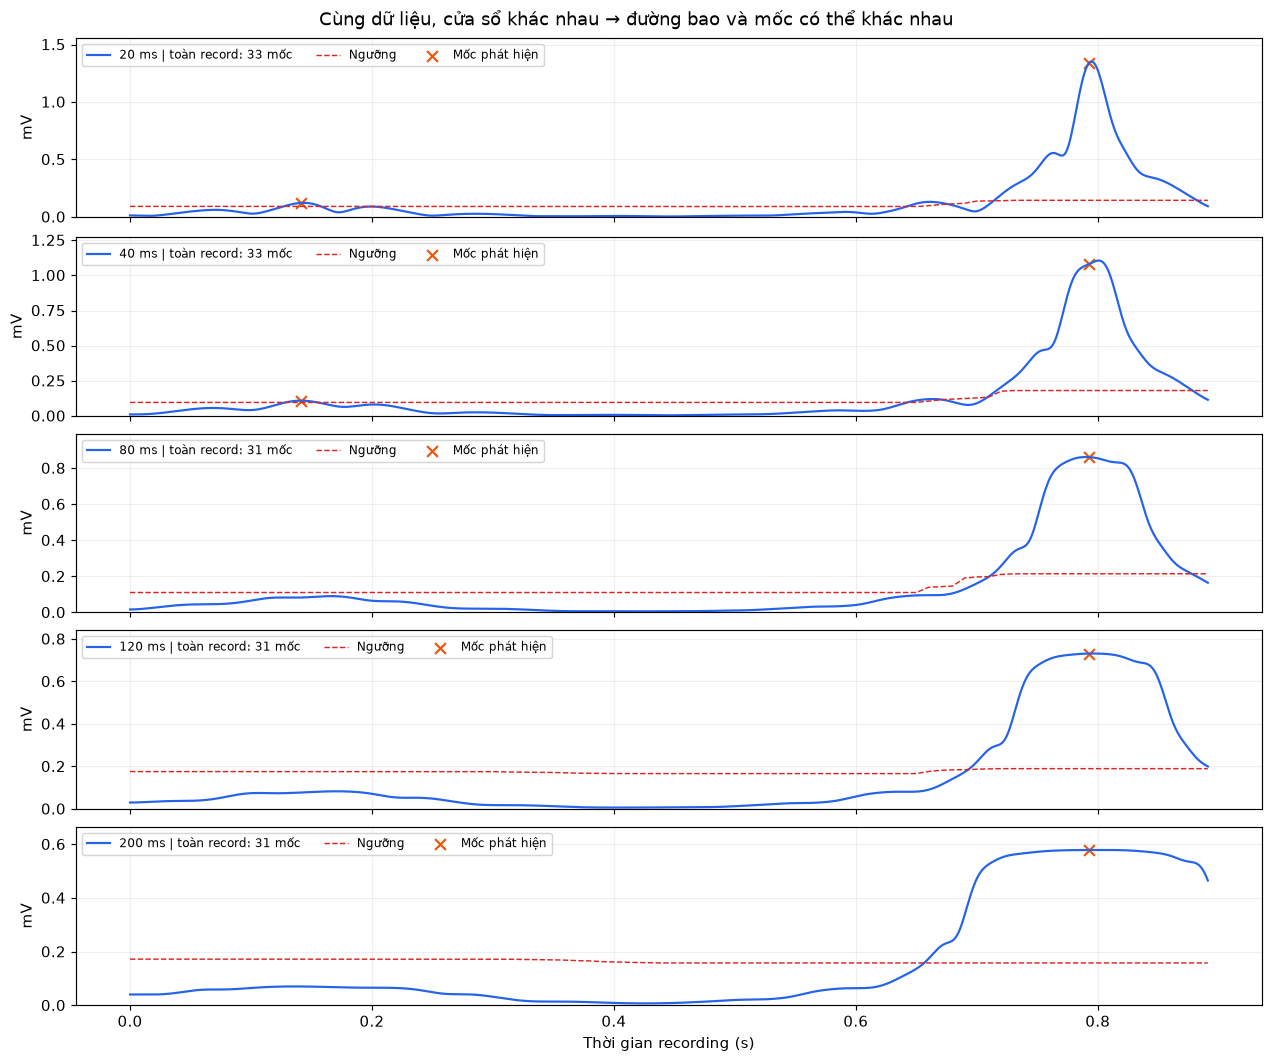

In [33]:
window_morph,window_detection=preprocess_xyz(raw_xyz,fs,WINDOW_PREPROCESSING_CFG)
visual_windows=[20,40,80,120,200]
visual_detections={};window_visual_errors=[]
for w in visual_windows:
    try:
        visual_detections[w]=detect_qrs_anchors(window_morph,window_detection,fs,
            replace(WINDOW_PREPROCESSING_CFG,energy_window_ms=w))
    except ValueError as exc:
        window_visual_errors.append(dict(window_ms=w,error=str(exc)))
display(pd.DataFrame(window_visual_errors,columns=["window_ms","error"]))
zoom_center=len(morph)/(2*fs)
if 20 in visual_detections and 200 in visual_detections:
    a_short=visual_detections[20]["anchors"];a_long=visual_detections[200]["anchors"]
    if len(a_short) and len(a_long):
        nearest=np.min(np.abs(a_short[:,None]-a_long[None,:]),axis=1)
        zoom_center=float(a_short[int(np.argmax(nearest))]/fs)
zoom_left=max(0,zoom_center-.75);zoom_right=min(len(morph)/fs,zoom_center+.75)
timeline=np.arange(len(morph))/fs
mask=(timeline>=zoom_left)&(timeline<=zoom_right)
fig,axs=plt.subplots(len(visual_windows),1,figsize=(12,10),sharex=True,layout='constrained')
for ax,w in zip(axs,visual_windows):
    found=visual_detections.get(w)
    if found is None:
        ax.text(.03,.5,f"{w} ms: detector không tạo được mốc; xem bảng lỗi phía trên.",
                transform=ax.transAxes)
        ax.set_ylabel("mV")
        continue
    ax.plot(timeline[mask],found['envelope'][mask],color='#2563eb',label=f'{w} ms | toàn record: {len(found["anchors"])} mốc')
    ax.plot(timeline[mask],found['threshold'][mask],color='#dc2626',ls='--',lw=1,label='Ngưỡng')
    peaks=found['anchors'][(found['anchors']/fs>=zoom_left)&(found['anchors']/fs<=zoom_right)]
    ax.scatter(peaks/fs,found['envelope'][peaks],color='#ea580c',marker='x',s=55,label='Mốc phát hiện')
    visible_max=max(float(np.max(found['envelope'][mask])),float(np.max(found['threshold'][mask])),float(np.max(found['envelope'][peaks])) if len(peaks) else 0)
    ax.set_ylim(0,1.15*visible_max)
    ax.set_ylabel('mV');ax.legend(loc='upper left',fontsize=8,ncol=3);ax.grid(alpha=.2)
axs[-1].set_xlabel('Thời gian recording (s)')
fig.suptitle('Cùng dữ liệu, cửa sổ khác nhau → đường bao và mốc có thể khác nhau')
finish(fig)

### C. Chạy mọi cửa sổ trên train/valid trong manifest MI/HC

`modal_count` là số mốc phổ biến nhất trong các cửa sổ thử của cùng record; nếu hòa lấy mode nhỏ nhất. Độ đồng thuận thời điểm dùng ghép một-một trong ±30 ms giữa từng cặp cửa sổ rồi lấy trung bình. Các đại lượng này được tính đối xứng từ mọi cửa sổ, không đặt 80 ms làm chuẩn.

Phép thử không đọc ECG II để tạo nhãn. Cờ RR chỉ là dấu hiệu cần xem lại, không xác nhận detector sai vì nhịp thật cũng có thể không đều. Thống kê PTB ở mức recording; một bệnh nhân có thể có nhiều recording.
Không quét test để khảo sát/chọn cửa sổ. Kết quả cuối của cấu hình cố định trên test nằm ở phụ lục đánh giá đồng bộ, tách riêng với train/valid.


In [34]:
ptb_window_details,ptb_window_errors,n_ptb_attempted=ptb_window_stability(DATA_ROOT)
ptb_window_summary=ptb_window_details.groupby(['split','window_ms']).agg(
    n_records=('record_id','size'),total_anchors=('n_anchors','sum'),
    modal_count_agreement_pct=('agrees_with_modal_count',lambda a:100*a.mean()),
    pairwise_agreement_pct=('mean_pairwise_agreement',lambda a:100*a.mean()),
    rr_warning_records=('rr_warning','sum')).reset_index()
print('Record thử:',n_ptb_attempted,'| lỗi record/cửa sổ:',len(ptb_window_errors))
display(ptb_window_summary.round(3))
if not ptb_window_errors.empty:display(ptb_window_errors)

demo_counts=ptb_window_details[ptb_window_details['record_id'].isin([RECORD_ID,COMPARISON_RECORD])]
display(demo_counts.pivot(index='window_ms',columns='record_id',values='n_anchors'))
print('Các số ở đây là độ ổn định/đồng thuận, chưa phải accuracy.')

PTB: 100/333 records
PTB: 200/333 records
PTB: 300/333 records
PTB: 333/333 records
Record thử: 333 | lỗi record/cửa sổ: 0


,split,window_ms,n_records,total_anchors,modal_count_agreement_pct,pairwise_agreement_pct,rr_warning_records
0,train,20,263,11230,47.148,95.480,79
1,train,40,263,10571,58.555,97.704,63
2,train,60,263,10209,75.285,98.740,39
3,train,80,263,10151,83.270,98.828,35
4,train,100,263,10125,90.875,98.883,25
5,train,120,263,10100,94.677,98.860,20
6,train,150,263,10085,90.114,98.825,19
7,train,180,263,10081,88.213,98.775,18
8,train,200,263,10076,83.650,98.710,18
9,val,20,70,2932,45.714,95.241,24


record_id,patient001/s0010_re,patient104/s0306lre
window_ms,,
20,41,33
40,41,33
60,41,31
80,41,31
100,41,31
120,41,31
150,41,31
180,40,31
200,40,31


Các số ở đây là độ ổn định/đồng thuận, chưa phải accuracy.


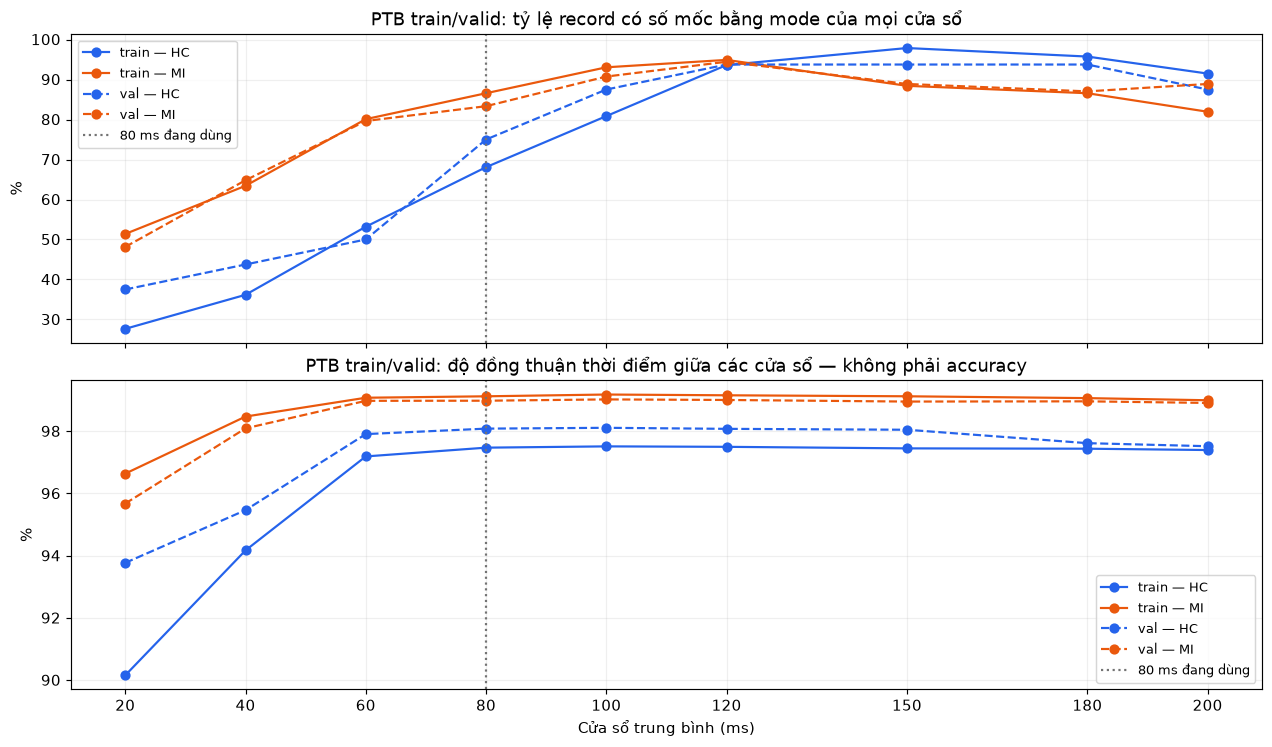

In [35]:
fig,axs=plt.subplots(2,1,figsize=(12,7),sharex=True,layout='constrained')
for (split,label),part in ptb_window_details.groupby(['split','label']):
    color='#2563eb' if label=='HC' else '#ea580c'
    group=part.groupby('window_ms')
    modal=group['agrees_with_modal_count'].mean()*100
    agreement=group['mean_pairwise_agreement'].mean()*100
    axs[0].plot(modal.index,modal.values,marker='o',color=color,label=split+' — '+label,ls='-' if split=='train' else '--')
    axs[1].plot(agreement.index,agreement.values,marker='o',color=color,label=split+' — '+label,ls='-' if split=='train' else '--')
for ax in axs:
    ax.axvline(80,color='.45',ls=':',label='80 ms đang dùng')
    ax.legend(fontsize=9);ax.grid(alpha=.2);ax.set_ylabel('%')
axs[0].set_title('PTB train/valid: tỷ lệ record có số mốc bằng mode của mọi cửa sổ')
axs[1].set_title('PTB train/valid: độ đồng thuận thời điểm giữa các cửa sổ — không phải accuracy')
axs[1].set_xlabel('Cửa sổ trung bình (ms)');axs[1].set_xticks(WINDOWS_MS)
finish(fig)

### D. Dữ liệu tổng hợp có mốc biết trước: đánh giá đúng, nhầm và bỏ sót

Các cửa sổ nhận cùng một bộ arrays và cùng reference. Generator dùng seed cố định, có tần số lấy mẫu 250/500/1000 Hz và các hình thái khác nhau. Các phép đo bên dưới mô tả đúng bộ tổng hợp này; không được chuyển thành tuyên bố độ chính xác trên PTB hoặc độ chính xác lâm sàng.

Validation dùng chọn cửa sổ; holdout chỉ dùng kiểm tra khả năng giữ kết quả trên subject tổng hợp khác. Toàn bộ grid được công bố, không chỉ công bố giá trị có lợi cho 80 ms.

In [36]:
synthetic_window_details,synthetic_window_summary,selected_window_ms,synthetic_split=synthetic_window_benchmark()
display(synthetic_window_details[['subject','condition','fs','split']].drop_duplicates()
        .groupby(['split','condition']).size().rename('số subject').to_frame())
display(synthetic_window_summary[['split','window_ms','tp','fp','fn','precision','recall','f1','matched_mae_ms']].round(5))
print('Cửa sổ được chọn CHỈ trên validation tổng hợp:',selected_window_ms,'ms')
print('Tolerance ghép mốc:',MATCH_TOLERANCE_MS,'ms; MAE chỉ trên các mốc ghép được.')

số subject
split      condition               
holdout    clean                  3
           irregular_RR           3
           large_T                3
           noisy                  3
           wide_QRS               3
validation clean                  6
           irregular_RR           6
           large_T                6
           noisy                  6
           wide_QRS               6

,split,window_ms,tp,fp,fn,precision,recall,f1,matched_mae_ms
0,holdout,20,649,100,0,0.86649,1.0,0.92847,0.74743
1,holdout,40,649,79,0,0.89148,1.0,0.94263,0.74743
2,holdout,60,649,44,0,0.93651,1.0,0.96721,0.74577
3,holdout,80,649,51,0,0.92714,1.0,0.96219,0.74434
4,holdout,100,649,53,0,0.92450,1.0,0.96077,0.74589
5,holdout,120,649,56,0,0.92057,1.0,0.95864,0.74657
6,holdout,150,649,52,0,0.92582,1.0,0.96148,0.74657
7,holdout,180,649,36,0,0.94745,1.0,0.97301,0.74657
8,holdout,200,649,34,0,0.95022,1.0,0.97447,0.74577
9,validation,20,1445,134,0,0.91514,1.0,0.95569,0.73715


Cửa sổ được chọn CHỈ trên validation tổng hợp: 80 ms
Tolerance ghép mốc: 50.0 ms; MAE chỉ trên các mốc ghép được.


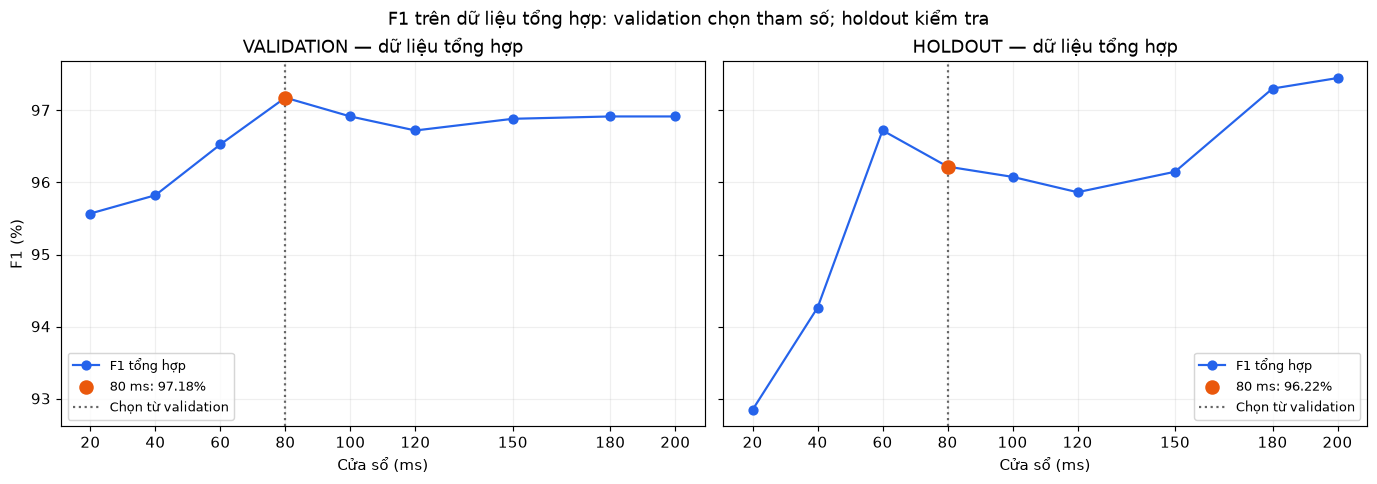

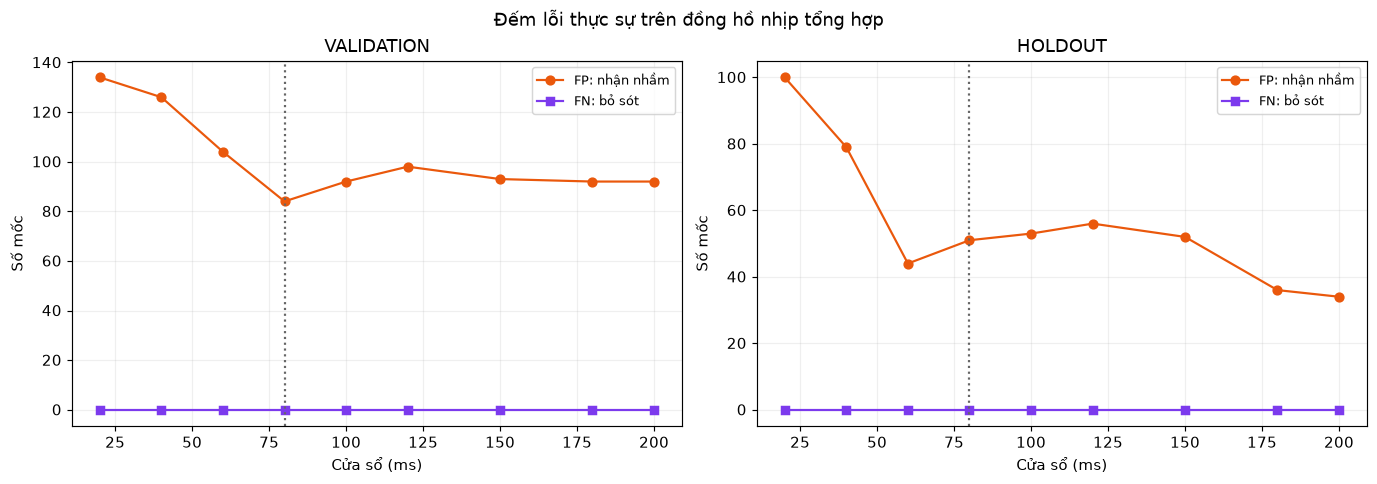

In [37]:
fig,axs=plt.subplots(1,2,figsize=(13,4.5),sharey=True,layout='constrained')
for ax,split in zip(axs,['validation','holdout']):
    summary=synthetic_window_summary[synthetic_window_summary['split']==split]
    ax.plot(summary['window_ms'],100*summary['f1'],color='#2563eb',marker='o',label='F1 tổng hợp')
    eighty=summary[summary['window_ms']==80].iloc[0]
    ax.scatter(80,100*eighty['f1'],color='#ea580c',s=80,zorder=5,label=f'80 ms: {100*eighty["f1"]:.2f}%')
    ax.axvline(selected_window_ms,color='.4',ls=':',label='Chọn từ validation')
    ax.set(xlabel='Cửa sổ (ms)',title=split.upper()+' — dữ liệu tổng hợp')
    ax.grid(alpha=.2);ax.legend(fontsize=9);ax.set_xticks(WINDOWS_MS)
axs[0].set_ylabel('F1 (%)')
fig.suptitle('F1 trên dữ liệu tổng hợp: validation chọn tham số; holdout kiểm tra')
finish(fig)

fig,axs=plt.subplots(1,2,figsize=(13,4.5),layout='constrained')
for ax,split in zip(axs,['validation','holdout']):
    summary=synthetic_window_summary[synthetic_window_summary['split']==split]
    ax.plot(summary['window_ms'],summary['fp'],marker='o',color='#ea580c',label='FP: nhận nhầm')
    ax.plot(summary['window_ms'],summary['fn'],marker='s',color='#7c3aed',label='FN: bỏ sót')
    ax.axvline(80,color='.4',ls=':');ax.set(xlabel='Cửa sổ (ms)',ylabel='Số mốc',title=split.upper())
    ax.grid(alpha=.2);ax.legend(fontsize=9)
fig.suptitle('Đếm lỗi thực sự trên đồng hồ nhịp tổng hợp')
finish(fig)

### E. Kết quả có giữ được ở từng điều kiện và subject khác không

F1 tổng cao có thể che một kịch bản khó. Hình sau tách từng điều kiện tổng hợp trên holdout. Bảng bootstrap so F1(80 ms) − F1(cửa sổ khác) theo subject, có giữ hai recording cùng subject đi cùng nhau. Khoảng 95% chứa 0 nghĩa phép thử này chưa tách rõ hai lựa chọn; CI âm hoàn toàn nghiêng về cửa sổ khác.

Bootstrap này chỉ đo biến thiên của mô hình tổng hợp đã tạo, không lượng hóa bất định trên bệnh nhân thật. Không bootstrap 80 ms so với chính nó.

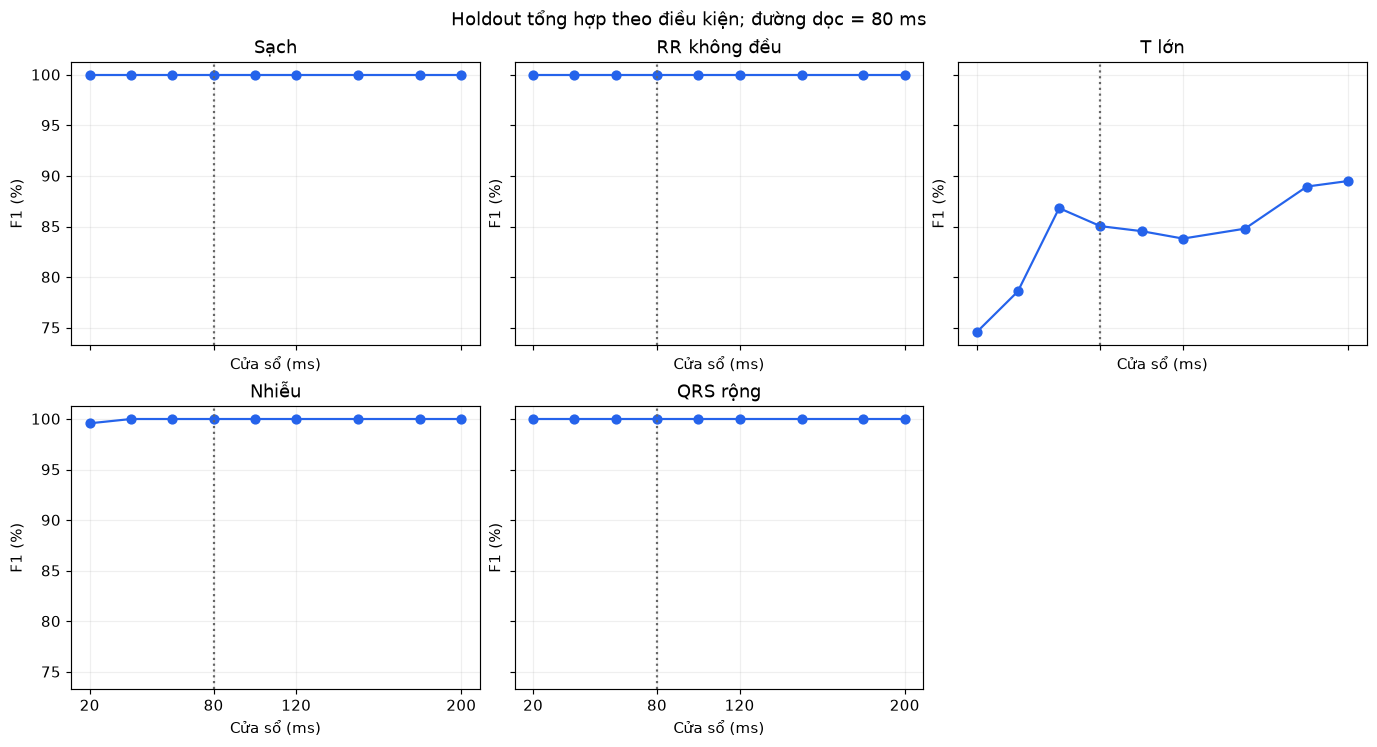

,so sánh,ΔF1 (điểm %),CI 95% dưới (điểm %),CI 95% trên (điểm %)
0,80 − 60 ms,-0.5019,-2.6501,0.8867
1,80 − 100 ms,0.1424,0.0000,0.3476
2,80 − 200 ms,-1.2280,-3.9424,0.6340


In [38]:
scenario_summary=summarize_event_scores(
    synthetic_window_details[synthetic_window_details['split']=='holdout'],['condition','window_ms'])
fig,axes=plt.subplots(2,3,figsize=(13,7),sharex=True,sharey=True,layout='constrained')
condition_names={'clean':'Sạch','noisy':'Nhiễu','large_T':'T lớn','wide_QRS':'QRS rộng','irregular_RR':'RR không đều'}
for ax,(condition,group) in zip(axes.flat,scenario_summary.groupby('condition')):
    ax.plot(group['window_ms'],100*group['f1'],marker='o',color='#2563eb')
    ax.axvline(80,color='.4',ls=':')
    ax.set(xlabel='Cửa sổ (ms)',ylabel='F1 (%)',title=condition_names[condition])
    ax.set_xticks([20,80,120,200]);ax.grid(alpha=.2)
axes.flat[-1].set_visible(False)
fig.suptitle('Holdout tổng hợp theo điều kiện; đường dọc = 80 ms')
finish(fig)

ci_rows=[]
holdout=synthetic_window_summary[synthetic_window_summary['split']=='holdout'].set_index('window_ms')
for other in [60,100,200]:
    low,high=paired_subject_bootstrap(synthetic_window_details,'holdout',80,baseline=other)
    ci_rows.append({'so sánh':f'80 − {other} ms','ΔF1 (điểm %)':100*(holdout.loc[80,'f1']-holdout.loc[other,'f1']),
                    'CI 95% dưới (điểm %)':100*low,'CI 95% trên (điểm %)':100*high})
window_pairwise_ci=pd.DataFrame(ci_rows)
display(window_pairwise_ci.round(4))

### F. Kết luận tính trực tiếp từ kết quả, không chốt trước 80 ms

Ô dưới tự nêu cửa sổ tốt nhất theo tiêu chí đã đặt trên validation, và báo vị trí 80 ms trên holdout. Việc xem holdout không được dùng để thay lại tham số lựa chọn ở bước trước.

PTB không có nhãn chuẩn ở phép thử này, nên dù 80 ms có đồng thuận cao, chưa thể viết “80 ms tối ưu trên PTB”. Nếu 80 ms tốt nhất validation tổng hợp, cách viết đúng là **“80 ms được chọn trên bộ validation tổng hợp của phép thử này”**. Cần annotation độc lập trên dữ liệu thật để chốt lựa chọn cho nghiên cứu.

In [39]:
validation_summary=synthetic_window_summary[synthetic_window_summary['split']=='validation'].set_index('window_ms')
holdout_summary=synthetic_window_summary[synthetic_window_summary['split']=='holdout'].set_index('window_ms')
best_holdout_f1=float(holdout_summary['f1'].max())
best_holdout_windows=holdout_summary.index[np.isclose(holdout_summary['f1'],best_holdout_f1,rtol=0,atol=1e-12)].tolist()
print(f'Validation tổng hợp chọn: {selected_window_ms} ms (F1={100*validation_summary.loc[selected_window_ms,"f1"]:.3f}%).')
print(f'80 ms trên holdout tổng hợp: F1={100*holdout_summary.loc[80,"f1"]:.3f}%.')
print(f'F1 cao nhất quan sát trên holdout: {best_holdout_windows} ms, {100*best_holdout_f1:.3f}%.')
if selected_window_ms==80:
    print('80 ms có bằng chứng hỗ trợ trong validation tổng hợp; chưa chứng minh tối ưu trên PTB thật.')
else:
    print('80 ms không đứng đầu validation tổng hợp của phép thử này; không có cơ sở gọi là tối ưu.')
if 80 not in best_holdout_windows:
    print('80 ms cũng không có F1 cao nhất trên holdout tổng hợp. Không kết luận tối ưu phổ quát.')
print('Giữ CFG=80 ms cho walkthrough hiện tại; không tự đổi pipeline theo kết quả holdout.')

experiment_dir=Path('vcg_window_validation');experiment_dir.mkdir(exist_ok=True)
ptb_window_details.to_csv(experiment_dir/'ptb_stability_details.csv',index=False)
ptb_window_summary.to_csv(experiment_dir/'ptb_stability_summary.csv',index=False)
synthetic_window_details.to_csv(experiment_dir/'synthetic_event_details.csv',index=False)
synthetic_window_summary.to_csv(experiment_dir/'synthetic_summary.csv',index=False)
window_pairwise_ci.to_csv(experiment_dir/'synthetic_paired_ci.csv',index=False)
print('Đã lưu dữ liệu số của các biểu đồ tại:',experiment_dir.resolve())

Validation tổng hợp chọn: 80 ms (F1=97.176%).
80 ms trên holdout tổng hợp: F1=96.219%.
F1 cao nhất quan sát trên holdout: [200] ms, 97.447%.
80 ms có bằng chứng hỗ trợ trong validation tổng hợp; chưa chứng minh tối ưu trên PTB thật.
80 ms cũng không có F1 cao nhất trên holdout tổng hợp. Không kết luận tối ưu phổ quát.
Giữ CFG=80 ms cho walkthrough hiện tại; không tự đổi pipeline theo kết quả holdout.
Đã lưu dữ liệu số của các biểu đồ tại: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\vcg_window_validation


### Cơ sở phương pháp và giới hạn

[Pan & Tompkins, 1985 — paper gốc](https://courses.csail.mit.edu/18.337/2017/projects/subramanian_sandya/Papers/Pan%2BTompkins.pdf) mô tả tác động của độ rộng moving-window và chọn 150 ms thực nghiệm cho detector của họ. Detector notebook này có cấu trúc khác, nên không thừa hưởng tham số hay số liệu hiệu quả đó.

[Hướng dẫn WQRS của PhysioNet](https://physionet.org/physiotools/wag/wqrs-1.htm) minh họa đánh giá detector bằng cách so output với annotation tham chiếu. Ở đây chỉ dữ liệu tổng hợp có reference; phần PTB chỉ là kiểm tra độ ổn định.

Phép thử chỉ thay một tham số. Nó chưa tối ưu đồng thời band-pass, ngưỡng, refractory hoặc quy tắc tinh chỉnh. Bộ tổng hợp đơn giản có thể bỏ qua nhiều hình thái bệnh lý; do đó thứ hạng cửa sổ có thể thay đổi khi có annotation thật. Một cửa sổ tốt cho tìm nhịp cũng chưa bảo đảm biên QRS/T hoặc 12 feature đúng.

## Phụ lục mới — cùng giao thức so sánh V1 / V2 / V3

Phần từng bước V1 phía trên giữ nguyên. Phụ lục này chạy lại từ raw cùng config và evaluate cả ba method trên cùng median để tránh so các CSV từ những lần chạy khác nhau. Cùng bộ hàm, option và metric được nhúng trực tiếp trong notebook 05, 09 và 10; không cần chạy script sinh notebook hoặc phụ thuộc output V3.

Chạy từ cell cấu hình dưới đến hết phụ lục. Muốn đối chiếu ba notebook: đặt cùng CX_DEMO_ID, seconds, scope, limit, tolerance, seeds và cấu hình; kiểm tra protocol ID và signal hash giống nhau. Mặc định chạy toàn bộ manifest, đánh giá riêng từng split và lưu báo cáo. Hướng dẫn từng bước V3 xem notebook 10.

Nếu các mục cũ phía trên đang tự chạy batch/prerequisites thì chúng thuộc workflow cũ; có thể chạy riêng toàn bộ phụ lục này vì nó tự import và đọc raw. Data raw cần có sẵn tại content/ptbdb/.../1.0.0; các JSON/split ở data/ chỉ là manifest.

### Chạy hết dữ liệu đang sử dụng và tránh leakage

Mặc định phần đánh giá chạy **mọi record trong `data/split_manifest.csv`** (hiện 448 MI/HC), không giới hạn 20 record. Mỗi record dùng tối đa `CX_SECONDS=30` giây như pipeline hiện hành; “toàn bộ cohort” không có nghĩa đọc hết thời lượng từng recording. Các hình từng bước phía trên dùng một ca minh họa, không thay thế đánh giá cohort.

- Cùng raw, median, QRS, RR, split và tiêu chí cho V1/V2/C/V3; mỗi method giữ đủ các record kể cả lỗi. Notebook 05 có báo cáo riêng V1, 09 riêng V2, 10 riêng V3; bảng chung chứa mọi method.
- Train, valid và test có bảng/hình riêng; kiểm tra patient ID trùng split sẽ dừng. Không gộp ba split thành một điểm chất lượng tổng.
- Các option chỉ sweep trên train/valid và hiển thị riêng từng split. Cấu hình mặc định V3 đã cố định trước khi chạy; code không chọn option theo test. Khi đổi phương pháp, dùng train/valid và khóa lại trước một lần báo cáo test mới.
- Imputer, scaler, Logistic Regression chỉ fit train; valid/test chỉ transform/predict, ngưỡng MI=0.5 cố định. Nhãn MI/HC không truyền vào delineation.
- Noise, beat bootstrap và feature sensitivity mặc định chạy trên toàn bộ cohort, dùng cùng seeds/scenarios cho các method; số liệu vẫn tách theo split. Đây là kiểm tra độ ổn định, chưa là accuracy biên T.
- Mỗi notebook tự chạy độc lập từ raw. Checkpoint chung ở `outputs/vcg_shared_comparison/_cache/<protocol>` kiểm tra hash header/waveform và protocol/package/config trước khi tái sử dụng. Lần đầu lâu hơn; tiến độ in mỗi 10 record. Thời gian lấy từ cache là thời gian lần tính đầu, không dùng để xếp hạng tốc độ giữa notebook.
- Kết quả tự lưu CSV/PNG dưới `outputs/vcg_shared_comparison/<notebook>/<run_tag_protocol>/`; `methods/V1`, `methods/V2`, `methods/C`, `methods/V3` là báo cáo riêng. Cell cuối đối chiếu manifest và kết quả số giữa ba lần chạy nếu đã có đủ file.

Khởi động lại kernel rồi chạy từ trên xuống. Có thể chạy riêng phụ lục đánh giá của 05/09 khi raw đã có. Không cần chạy script sinh notebook. Muốn thử nhanh, đổi `CX_COHORT_LIMIT=20`; kết quả khi đó được ghi protocol khác và không dùng làm báo cáo toàn bộ. Không bật khảo sát option trên test.


In [40]:
CX_NOTEBOOK = "05_QRS_T_Loops_Step_by_Step.ipynb"
from pathlib import Path
from dataclasses import asdict, replace
from itertools import combinations, product
import hashlib, json, sys, time, copy, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

CX_ROOT = next((p for p in [Path.cwd(), Path.cwd() / "VCG", *Path.cwd().parents]
                if (p / "vcg_pipeline.py").is_file()), None)
if CX_ROOT is None:
    raise FileNotFoundError("Mở notebook từ thư mục vcg/VCG hoặc vcg.")
CX_ROOT = CX_ROOT.resolve()
if str(CX_ROOT) not in sys.path: sys.path.insert(0, str(CX_ROOT))
from vcg_preprocessing import Config, assess_input_quality, welch_xyz
from vcg_pipeline import (FEATURE_NAMES, load_xyz, preprocess_xyz, detect_qrs_anchors,
    representative_beat, delineate_loops, cut_loop, extract_features, spatial_speed,
    project_pca, flattest_pq, ms_samples, plot_delineation)
from vcg_t_almeida import AlmeidaConfig, delineate_t, wavelet_transform, json_safe

# Cùng các giá trị này trong 05, 09 và 10 để so sánh được.
CX_DATA_ROOT = CX_ROOT / "content/ptbdb/physionet.org/files/ptbdb/1.0.0"
CX_DEMO_ID = "patient104/s0306lre"
CX_RUN_COHORT = True
CX_COHORT_LIMIT = None           # None = toàn bộ phạm vi đã chọn
CX_SCOPE = "all"       # train_valid / test / all
CX_SECONDS = 30.0
CX_TOLERANCE_MS = 25.0
CX_MIN_VOTES = 2
CX_DURATION_MS = (60.0, 400.0)  # màn kiểm tra chung; không clip/ép kéo dài sóng
CX_NOISE_LEVELS = (0.005, 0.01, 0.02)
CX_SEEDS = (0, 1, 2, 3, 4)
CX_RUN_STABILITY = True        # toàn cohort, tách split; noise lên median
CX_RUN_BOOTSTRAP = True        # toàn cohort; resample các beat đã giữ
CX_BOOTSTRAP_REPEATS = 10
CX_RUN_SENSITIVITY = True
CX_RUN_ML = True              # chỉ có ý nghĩa khi đủ cohort train/val/test
CX_SAVE_REPORTS = True
CX_SAVE_FIGURES = True
CX_RUN_COHORT_OPTIONS = True   # chỉ train/valid; không sweep test
CX_REUSE_CACHE = True
CX_RAW_IDENTITIES = {}
CX_FOCUS_METHOD = "V1"
CX_RUN_TAG = "full_cohort_01"   # đổi khi thay cấu hình hoặc thực hiện final test
CX_V1_CFG, CX_V2_CFG = Config(seconds=CX_SECONDS), AlmeidaConfig()
CX_METHODS = ("V1", "V2", "C", "V3")
CX_COLORS = {"V1":"#d97706", "V2":"#7c3aed", "C":"#0891b2", "V3":"#dc2765"}
pd.set_option("display.max_columns", 40)
plt.rcParams.update({"font.family":"DejaVu Sans", "figure.dpi":105, "font.size":10})

def cx_file_hash(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""): h.update(block)
    return h.hexdigest()

def cx_signal_hash(xyz):
    return hashlib.sha256(np.ascontiguousarray(xyz, dtype="<f8").tobytes()).hexdigest()

def cx_index(value, n):
    try: return np.isfinite(value) and int(value) == value and 0 <= int(value) < n
    except (TypeError, ValueError, OverflowError): return False

def cx_ms(value, st):
    return (int(value)-st["rep"]["anchor"])*1000/st["fs"] if cx_index(value,len(st["rep"]["xyz"])) else np.nan

CX_SPLIT = pd.read_csv(CX_ROOT / "data/split_manifest.csv")
CX_SPLIT["split"] = CX_SPLIT["split"].replace({"valid":"val", "validation":"val"})
assert CX_SPLIT.record_id.is_unique, "record_id lặp trong split manifest"
assert CX_SPLIT.groupby("patient_id").split.nunique().max() == 1, "Patient leakage!"
assert CX_SPLIT.groupby("patient_id").label_name.nunique().max() == 1, "Patient label mismatch"
assert CX_SPLIT.label_name.isin(["MI","HC"]).all()
_cx_notebook = json.loads((CX_ROOT/CX_NOTEBOOK).read_text(encoding="utf-8"))
_cx_shared_sources = ["".join(c["source"]) for c in _cx_notebook["cells"]
                      if "cx_shared_definition" in c.get("metadata",{}).get("tags",[])]
CX_SHARED_CODE_SHA256 = hashlib.sha256("\n".join(_cx_shared_sources).encode()).hexdigest()
cx_config = dict(shared_code_sha256=CX_SHARED_CODE_SHA256, protocol="vcg-shared-split-cohort-2.0", seconds=CX_SECONDS,
    tolerance_ms=CX_TOLERANCE_MS, min_votes=CX_MIN_VOTES, duration_ms=CX_DURATION_MS,
    v1=asdict(CX_V1_CFG), v2=asdict(CX_V2_CFG), scope=CX_SCOPE,
    noise_levels=CX_NOISE_LEVELS, seeds=CX_SEEDS, cohort_limit=CX_COHORT_LIMIT,
    run_stability=CX_RUN_STABILITY, run_bootstrap=CX_RUN_BOOTSTRAP, bootstrap_repeats=CX_BOOTSTRAP_REPEATS,
    run_sensitivity=CX_RUN_SENSITIVITY, run_ml=CX_RUN_ML, cohort_options=CX_RUN_COHORT_OPTIONS,
    ml_feature_policy="valid", classifier="balanced LogisticRegression; threshold=.5; train-only preprocessing",
    packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","matplotlib","wfdb","scikit-learn")},
    files_manifest_sha256=cx_file_hash(CX_ROOT/"data/ptbdb-files.json"),
    resources_sha256=cx_file_hash(CX_ROOT/"data/resources.json"),
    split_sha256=cx_file_hash(CX_ROOT/"data/split_manifest.csv"),
    source_sha256={p:cx_file_hash(CX_ROOT/p) for p in
        ["vcg_pipeline.py","vcg_preprocessing.py","vcg_t_almeida.py"]})
CX_PROTOCOL_ID = hashlib.sha256(json.dumps(cx_config,sort_keys=True).encode()).hexdigest()[:16]
CX_OUT = CX_ROOT/"outputs"/"vcg_shared_comparison"/Path(CX_NOTEBOOK).stem/(CX_RUN_TAG+"_"+CX_PROTOCOL_ID)
CX_CACHE = CX_ROOT/"outputs/vcg_shared_comparison/_cache"/CX_PROTOCOL_ID
CX_RESULTS = {}
def cx_show(fig, name):
    # Nhúng PNG tĩnh để VS Code/Jupyter không phụ thuộc widget/backend hiện tại.
    from io import BytesIO
    from IPython.display import Image
    fig.canvas.draw()
    with BytesIO() as png:
        fig.savefig(png,format="png",dpi=plt.rcParams["figure.dpi"],bbox_inches="tight")
        display(Image(data=png.getvalue()))
    if CX_SAVE_FIGURES:
        CX_OUT.mkdir(parents=True, exist_ok=True)
        fig.savefig(CX_OUT/(name+".png"), dpi=180, bbox_inches="tight")
    plt.close(fig)
print("Root:", CX_ROOT, "\nData:", CX_DATA_ROOT, "\nProtocol:", CX_PROTOCOL_ID)
print("Output:", CX_OUT, "\nCohort:", CX_RUN_COHORT, "| scope:", CX_SCOPE)
print("Mặc định FULL manifest:",len(CX_SPLIT),"record | riêng:",CX_FOCUS_METHOD,"| split tách biệt; checkpoint:",CX_CACHE)


Root: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG 
Data: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\content\ptbdb\physionet.org\files\ptbdb\1.0.0 
Protocol: 59fcbe5ae8e1cc06
Output: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\05_QRS_T_Loops_Step_by_Step\full_cohort_01_59fcbe5ae8e1cc06 
Cohort: True | scope: all
Mặc định FULL manifest: 448 record | riêng: V1 | split tách biệt; checkpoint: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\_cache\59fcbe5ae8e1cc06


### Bộ hàm đồng bộ (có thể mở cell để đọc)

V1/V2/C được adapter vào cùng schema, V3 dùng joint complete-link consensus. Cùng bộ kiểm tra thứ tự, duration, input flags và feature extraction được dùng cho mọi method. Flags native vẫn được giữ. Code/hash phải giống trong cả ba notebook.

In [41]:
def cx_load_state(rid):
    started = time.perf_counter()
    raw = load_xyz(CX_DATA_ROOT / rid, CX_V1_CFG.seconds)
    fs = raw["fs"]
    morph, detection, prep = preprocess_xyz(raw["xyz"], fs, CX_V1_CFG, return_diagnostics=True)
    detector = detect_qrs_anchors(morph, detection, fs, CX_V1_CFG)
    rep = representative_beat(morph, detector["anchors"], fs, CX_V1_CFG, quality=prep["input_quality"])
    common_flags = sorted(set(detector["flags"] + rep["quality_flags"] +
                             prep.get("warnings", [])))
    if rep["n_used"] < 5: common_flags.append("few_representative_beats")
    if rep["n_excluded"]/max(len(detector["anchors"]),1) > .4:
        common_flags.append("many_excluded_beats")
    return dict(record_id=rid, raw=raw, fs=fs, morph=morph, detection=detection,
                preprocessing=prep, detector=detector, rep=rep,
                common_flags=sorted(set(common_flags)),
                shared_seconds=time.perf_counter()-started)

def cx_order(st, b):
    n = len(st["rep"]["xyz"])
    q0,q1,on,off = [b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    if not all(cx_index(v,n) for v in (q0,q1,on,off)): return False
    if not q0 < st["rep"]["anchor"] < q1 < on < off: return False
    peaks = b.get("peaks", [])
    return all(cx_index(p,n) and on < p < off for p in peaks if p is not None)

def cx_derivative(st, q):
    # C là magnitude-baseline threshold kiểm tra chéo, không phải detector độc lập.
    from scipy.signal import savgol_filter, find_peaks
    fs,rep=st["fs"],st["rep"]; xyz=rep["xyz"]; n=len(xyz)
    out=dict(method="C",status="unresolved",flags=[],qrs_on=q.get("qrs_on"),qrs_off=q.get("qrs_off"),
             t_on=None,t_off=None,peaks=[],trace={})
    if not cx_index(q.get("qrs_off"),n):
        out["flags"]=["missing_qrs_off"]; return out
    win=min(n if n%2 else n-1, max(5,ms_samples(21,fs)|1))
    smooth=savgol_filter(np.linalg.norm(xyz,axis=1),win,3)
    lo=int(q["qrs_off"])+ms_samples(20,fs)
    hi=min(n-1,rep["anchor"]+int(min(.60,.70*rep["rr_seconds"])*fs))
    if hi-lo < ms_samples(100,fs):
        out["flags"]=["short_t_window"]; return out
    pq=smooth[slice(*rep["pq"])]
    base=float(np.median(pq)); noise=max(float(1.4826*np.median(abs(pq-base))),1e-6)
    peaks,props=find_peaks(smooth[lo:hi+1],prominence=max(3*noise,1e-6),
                           distance=ms_samples(40,fs))
    peaks=peaks+lo
    out["trace"]=dict(smooth=smooth,search=(lo,hi),baseline=base,noise=noise)
    if not len(peaks):
        out["flags"]=["no_t_peak"]; return out
    peak=int(peaks[np.argmax(props["prominences"])])
    threshold=base+max(3*noise,.08*max(smooth[peak]-base,0)); run=ms_samples(20,fs)
    def crossing(start,stop,step):
        count=0
        for i in range(start,stop+step,step):
            count=count+1 if smooth[i] <= threshold else 0
            if count >= run: return i-run+1 if step>0 else i+run-1
        return None
    out.update(t_on=crossing(peak,lo,-1), t_off=crossing(peak,hi,1), peaks=[peak])
    out["trace"].update(threshold=threshold,peak=peak)
    if smooth[peak]-base<=5*noise: out["flags"].append("t_low_amplitude")
    if out["t_on"] is None or out["t_off"] is None: out["flags"].append("threshold_crossing_missing")
    out["status"]="detected" if cx_order(st,out) else "unresolved"
    return out

def cx_candidates(st):
    rep,fs=st["rep"],st["fs"]
    started=time.perf_counter(); q=delineate_loops(rep,fs,CX_V1_CFG)
    v1=dict(method="V1",status="detected",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=q["t_on"],t_off=q["t_off"],peaks=[q["t_peak"]] if q["t_peak"] is not None else [],
            flags=list(q["flags"]),trace=q)
    if not cx_order(st,v1): v1["status"]="unresolved"
    v1["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter()
    v2=dict(method="V2",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
            t_on=None,t_off=None,peaks=[],flags=[],trace={})
    if cx_index(q["qrs_on"],len(rep["xyz"])) and cx_index(q["qrs_off"],len(rep["xyz"])):
        try:
            trace=delineate_t(rep["xyz"],fs,rep["anchor"],q["qrs_on"],q["qrs_off"],
                              rep["rr_seconds"],CX_V2_CFG)
            peaks=[]
            for boundary,pick in (("t_on",0),("t_off",-1)):
                pp=trace.get("branches",{}).get(boundary,{}).get("peaks",[])
                if pp: peaks.append(pp[pick])
            v2.update(status=trace["status"],t_on=trace.get("t_on_sample"),t_off=trace.get("t_off_sample"),
                      flags=list(trace.get("review_flags",[])),peaks=peaks,trace=trace)
            if trace.get("failure_reason"): v2["flags"].append(trace["failure_reason"])
        except (ValueError, RuntimeError, np.linalg.LinAlgError) as exc:
            v2.update(status="error",flags=[type(exc).__name__+": "+str(exc)])
    else: v2["flags"]=["missing_qrs"]
    v2["algorithm_seconds"]=time.perf_counter()-started
    started=time.perf_counter(); c=cx_derivative(st,v1)
    c["algorithm_seconds"]=time.perf_counter()-started
    return {"V1":v1,"V2":v2,"C":c}

def cx_consensus(st, candidates, tolerance_ms=None, min_votes=None, members=("V1","V2","C")):
    # Chọn một nhóm phương pháp hỗ trợ CẢ cặp biên.
    # Complete-link: max-min <= tolerance ở cả onset và offset; tránh chuỗi nối xa.
    tolerance_ms=CX_TOLERANCE_MS if tolerance_ms is None else float(tolerance_ms)
    min_votes=CX_MIN_VOTES if min_votes is None else int(min_votes)
    assert tolerance_ms>0 and 2<=min_votes<=len(members)
    start=time.perf_counter(); fs=st["fs"]
    q=candidates["V1"]
    out=dict(method="V3",status="unresolved",qrs_on=q["qrs_on"],qrs_off=q["qrs_off"],
             t_on=None,t_off=None,peaks=[],flags=[],trace={})
    usable=[m for m in members if candidates[m]["status"] in ("detected","needs_review")
            and cx_order(st,candidates[m])]
    groups=[]
    for size in range(min_votes,len(usable)+1):
        for g in combinations(usable,size):
            on=np.array([candidates[m]["t_on"] for m in g]); off=np.array([candidates[m]["t_off"] for m in g])
            if max(np.ptp(on),np.ptp(off))*1000/fs <= tolerance_ms + 1e-9:
                groups.append((g,on,off))
    out["trace"].update(usable=usable,tolerance_ms=tolerance_ms,min_votes=min_votes)
    if not groups:
        out["flags"]=["no_joint_boundary_agreement"]
    else:
        # Tie không phụ thuộc nhãn; ít dispersion nhất rồi alphabet.
        groups.sort(key=lambda e:(-len(e[0]),float(np.std(e[1])+np.std(e[2])),e[0]))
        g,on,off=groups[0]
        out.update(t_on=int(np.floor(np.median(on)+.5)),t_off=int(np.floor(np.median(off)+.5)))
        out["trace"].update(voters=list(g),votes=len(g),
            on_spread_ms=float(np.std(on)*1000/fs),off_spread_ms=float(np.std(off)*1000/fs),
            on_range_ms=float(np.ptp(on)*1000/fs),off_range_ms=float(np.ptp(off)*1000/fs))
        # Mỗi candidate giữ peak riêng; không chế tạo "consensus peak" cho V2.
        member_peaks=[p for m in g for p in candidates[m].get("peaks",[]) if p is not None]
        if not all(out["t_on"]<p<out["t_off"] for p in member_peaks):
            out["flags"].append("consensus_excludes_member_peak")
        out["flags"] += [m+":"+f for m in g for f in candidates[m].get("flags",[])]
        duration=(out["t_off"]-out["t_on"])*1000/fs
        if not CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1]: out["flags"].append("duration_review")
        out["status"]="detected" if cx_order(st,out) and not out["flags"] else "needs_review"
    out["algorithm_seconds"]=time.perf_counter()-start
    out["flags"]=sorted(set(out["flags"]))
    return out

def cx_all(st):
    candidates=cx_candidates(st)
    candidates["V3"]=cx_consensus(st,candidates)
    return candidates

def cx_evaluate(st,b):
    rep,fs=st["rep"],st["fs"]; xyz=rep["xyz"]; n=len(xyz)
    valid=cx_order(st,b)
    q0,q1,on,off=[b.get(k) for k in ("qrs_on","qrs_off","t_on","t_off")]
    duration=(off-on)*1000/fs if valid else np.nan
    plausible=bool(valid and CX_DURATION_MS[0]<=duration<=CX_DURATION_MS[1])
    flags=sorted(set(st["common_flags"]+b.get("flags",[])))
    if not valid: flags.append("invalid_or_missing_T_pair")
    if valid and not plausible: flags.append("duration_review")
    accepted=bool(valid and plausible and not flags and b["status"] in ("detected","needs_review"))
    speed=spatial_speed(xyz,fs,CX_V1_CFG)
    qloop=cut_loop(xyz,q0,q1) if all(cx_index(v,n) for v in (q0,q1)) else None
    # Candidate feature để chẩn đoán; accepted-feature được mask riêng khi export/ML.
    tloop=cut_loop(xyz,on,off) if valid else None
    features=extract_features(qloop,tloop,fs,CX_V1_CFG,speeds={
        "QRS":speed[q0:q1+1] if qloop is not None else None,
        "T":speed[on:off+1] if tloop is not None else None})
    pqmag=np.linalg.norm(xyz[slice(*rep["pq"])],axis=1)
    noise=max(float(1.4826*np.median(abs(pqmag-np.median(pqmag)))),1e-9)
    p=project_pca(tloop) if tloop is not None else None
    tr=b.get("trace",{})
    row=dict(record_id=st["record_id"],patient_id=st["record_id"].split("/")[0],method=b["method"],
        protocol_id=CX_PROTOCOL_ID,signal_sha256=cx_signal_hash(xyz),fs_hz=fs,anchor=rep["anchor"],
        native_status=b["status"],boundary_present=all(cx_index(v,n) for v in (on,off)),
        onset_present=cx_index(on,n),offset_present=cx_index(off,n),
        valid_pair=valid,duration_plausible=plausible,accepted=accepted,
        t_on_ms=cx_ms(on,st),t_off_ms=cx_ms(off,st),qrs_on_ms=cx_ms(q0,st),qrs_off_ms=cx_ms(q1,st),
        duration_ms=duration,flags=";".join(sorted(set(flags))),
        common_flags=";".join(st["common_flags"]),method_flags=";".join(b.get("flags",[])),
        feature_complete=bool(np.isfinite(list(features.values())).all()),
        n_used=rep["n_used"],n_excluded=rep["n_excluded"],median_rr_ms=rep["rr_seconds"]*1000,
        shared_seconds=st.get("shared_seconds",0),algorithm_seconds=b.get("algorithm_seconds",np.nan),
        total_method_seconds=b.get("algorithm_seconds",np.nan),
        pq_noise_proxy_mV=noise,
        amplitude_to_PQ_noise_proxy=(features["T_MaxVec"]/noise if valid else np.nan),
        loop_closure_mV=(float(np.linalg.norm(tloop[-1]-tloop[0])) if valid else np.nan),
        closure_normalized=(float(np.linalg.norm(tloop[-1]-tloop[0]))/max(features["T_MaxVec"],1e-9) if valid else np.nan),
        pca_variance_2d=(p["variance"] if p else np.nan),
        votes=tr.get("votes",np.nan),on_spread_ms=tr.get("on_spread_ms",np.nan),off_spread_ms=tr.get("off_spread_ms",np.nan),
        **features)
    # V3 end-to-end cost = shared preprocessing + tất cả candidate + aggregation.
    return row,dict(qrs_loop=qloop,t_loop=tloop,features=features,accepted=accepted,flags=flags)

def cx_record_rows(st,results):
    rows=[]
    for name,b in results.items():
        row,_=cx_evaluate(st,b)
        row["total_method_seconds"]=st.get("shared_seconds",0)+(
            sum(results[m].get("algorithm_seconds",0) for m in ("V1","V2","C","V3"))
            if name=="V3" else results["V1"].get("algorithm_seconds",0)+b.get("algorithm_seconds",0)
            if name in ("V2","C") else b.get("algorithm_seconds",0))
        rows.append(row)
    return rows

def cx_failure_row(rid, method):
    # Giữ cùng schema khi mọi record đều lỗi: bảng/plot vẫn có cột numeric.
    numeric = ("fs_hz", "anchor", "t_on_ms", "t_off_ms", "qrs_on_ms", "qrs_off_ms",
        "duration_ms", "n_used", "n_excluded", "median_rr_ms", "shared_seconds",
        "algorithm_seconds", "total_method_seconds", "pq_noise_proxy_mV",
        "amplitude_to_PQ_noise_proxy", "loop_closure_mV", "closure_normalized",
        "pca_variance_2d", "votes", "on_spread_ms", "off_spread_ms")
    row = dict.fromkeys((*numeric, *FEATURE_NAMES), np.nan)
    row.update(record_id=rid, patient_id=rid.split("/")[0], method=method,
        protocol_id=CX_PROTOCOL_ID, signal_sha256=None, native_status="error",
        accepted=False, valid_pair=False, boundary_present=False, onset_present=False,
        offset_present=False, feature_complete=False, duration_plausible=False,
        flags="input_or_pipeline_error", common_flags="input_or_pipeline_error", method_flags="")
    return row



In [42]:
def cx_summary(frame):
    rows=[]
    for method,g in frame.groupby("method",sort=False):
        row=dict(method=method,attempted=len(g),patients=g.patient_id.nunique())
        for c in ("onset_present","offset_present","boundary_present","valid_pair","duration_plausible","accepted","feature_complete"):
            row[c+"_n"]=int(g[c].fillna(False).astype(bool).sum())
            row[c+"_pct"]=100*row[c+"_n"]/len(g)
        row["error_n"]=int(g.native_status.eq("error").sum())
        for c in ("duration_ms","closure_normalized","pca_variance_2d","algorithm_seconds","total_method_seconds"):
            if c in g:
                x=pd.to_numeric(g[c],errors="coerce").dropna()
                row[c+"_n"]=len(x)
                row[c+"_median"]=x.median()
                row[c+"_p90"]=x.quantile(.9)
        rows.append(row)
    return pd.DataFrame(rows)

def cx_pairwise(frame):
    from scipy.stats import spearmanr
    rows=[]; details=[]
    for left,right in combinations(frame.method.unique(),2):
        a=frame[frame.method.eq(left)]; b=frame[frame.method.eq(right)]
        p=a.merge(b,on=["record_id","patient_id"],suffixes=("_a","_b"),validate="one_to_one")
        good=p.valid_pair_a.fillna(False).astype(bool)&p.valid_pair_b.fillna(False).astype(bool)
        r=dict(left=left,right=right,attempted_pairs=len(p),valid_pairs=int(good.sum()),
               both_accepted=int((p.accepted_a.fillna(False)&p.accepted_b.fillna(False)).sum()))
        q=p[good].copy()
        if not q.empty:
            assert (q.signal_sha256_a==q.signal_sha256_b).all(), "Không cùng median XYZ"
            for boundary in ("t_on_ms","t_off_ms"):
                delta=q[boundary+"_b"]-q[boundary+"_a"]
                r[boundary+"_bias"]=delta.mean()
                r[boundary+"_median_signed"]=delta.median()
                r[boundary+"_median_abs"]=delta.abs().median()
                r[boundary+"_p90_abs"]=delta.abs().quantile(.9)
                r[boundary+"_sd"]=delta.std(ddof=1)
                r[boundary+"_loa_low"]=delta.mean()-1.96*delta.std(ddof=1)
                r[boundary+"_loa_high"]=delta.mean()+1.96*delta.std(ddof=1)
                for tol in (10,20,25,40,50):
                    r[boundary+f"_within_{tol}ms_pct"]=100*delta.abs().le(tol).mean()
            intersection=np.maximum(0,np.minimum(q.t_off_ms_a,q.t_off_ms_b)-np.maximum(q.t_on_ms_a,q.t_on_ms_b))
            la=q.t_off_ms_a-q.t_on_ms_a; lb=q.t_off_ms_b-q.t_on_ms_b
            union=la+lb-intersection
            q["interval_iou"]=intersection/union
            q["interval_dice"]=2*intersection/(la+lb)
            r["median_iou"]=q.interval_iou.median(); r["median_dice"]=q.interval_dice.median()
            r["duration_median_abs_difference_ms"]=(lb-la).abs().median()
            for feature in FEATURE_NAMES:
                va=pd.to_numeric(q[feature+"_a"],errors="coerce")
                vb=pd.to_numeric(q[feature+"_b"],errors="coerce")
                ok=np.isfinite(va)&np.isfinite(vb)
                r[feature+"_paired_n"]=int(ok.sum())
                r[feature+"_median_abs_delta"]=(vb-va)[ok].abs().median()
                r[feature+"_median_relative_delta_pct"]=(100*(vb-va)/va.abs().where(va.abs()>1e-9))[ok].median()
                r[feature+"_spearman"]=(spearmanr(va[ok],vb[ok]).statistic if ok.sum()>=3 and va[ok].nunique()>1 and vb[ok].nunique()>1 else np.nan)
            for _,v in q.iterrows():
                details.append(dict(record_id=v.record_id,patient_id=v.patient_id,left=left,right=right,
                    on_delta_ms=v.t_on_ms_b-v.t_on_ms_a,off_delta_ms=v.t_off_ms_b-v.t_off_ms_a,
                    on_mean_ms=(v.t_on_ms_a+v.t_on_ms_b)/2,off_mean_ms=(v.t_off_ms_a+v.t_off_ms_b)/2,
                    interval_iou=v.interval_iou,interval_dice=v.interval_dice))
        rows.append(r)
    return pd.DataFrame(rows),pd.DataFrame(details)

def cx_patient_ci(frame, repeats=500):
    # Cluster bootstrap: resample patients; retain every record within each sampled patient.
    rng=np.random.default_rng(2026); rows=[]
    for method,g in frame.groupby("method"):
        patients=g.patient_id.unique()
        if len(patients)<10:
            rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
                             low=np.nan,high=np.nan,patients=len(patients),note="too_few_patients_for_CI")); continue
        blocks=[g[g.patient_id.eq(p)] for p in patients]; values=[]
        for _ in range(repeats):
            chosen=[blocks[i] for i in rng.integers(0,len(blocks),len(blocks))]
            values.append(sum(v.accepted.sum() for v in chosen)/sum(len(v) for v in chosen))
        rows.append(dict(method=method,metric="accepted_rate",estimate=g.accepted.mean(),
            low=np.quantile(values,.025),high=np.quantile(values,.975),patients=len(patients),
            note="95% percentile patient-cluster bootstrap; descriptive"))
    return pd.DataFrame(rows)

def cx_perturb(st, base_results):
    rows=[]; xyz=st["rep"]["xyz"]
    # Một scalar robust scale từ median đã bỏ baseline theo từng trục.
    sigma=max(float(1.4826*np.median(abs(xyz-np.median(xyz,axis=0)))),1e-9)
    for level,seed in product(CX_NOISE_LEVELS,CX_SEEDS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        clone["rep"]["xyz"]=xyz+np.random.default_rng(seed).normal(0,sigma*level,xyz.shape)
        changed=cx_all(clone)
        for method,r in changed.items():
            original=base_results[method]; row,_=cx_evaluate(clone,r)
            base_valid=cx_order(st,original); valid=cx_order(clone,r)
            rows.append(dict(method=method,level=level,seed=seed,sigma_mV=sigma*level,
                base_valid=base_valid,perturbed_valid=valid,accepted=row["accepted"],
                native_status=r["status"],status_changed=r["status"]!=original["status"],
                on_delta_ms=(cx_ms(r["t_on"],clone)-cx_ms(original["t_on"],st) if base_valid and valid else np.nan),
                off_delta_ms=(cx_ms(r["t_off"],clone)-cx_ms(original["t_off"],st) if base_valid and valid else np.nan)))
    return pd.DataFrame(rows)

def cx_bootstrap(st,base_results):
    rng=np.random.default_rng(2026); rows=[]; beats=st["rep"]["beats"]
    for repeat in range(CX_BOOTSTRAP_REPEATS):
        clone=dict(st); clone["rep"]=dict(st["rep"])
        median=np.median(beats[rng.integers(0,len(beats),len(beats))],axis=0)
        median=median-np.median(median[slice(*st["rep"]["pq"])],axis=0)
        clone["rep"]["xyz"]=median
        # QRS detector raw không chạy lại; QRS boundary trên median mới có thể thay đổi.
        rs=cx_all(clone)
        for method,r in rs.items():
            base=base_results[method]; valid=cx_order(clone,r) and cx_order(st,base)
            rows.append(dict(method=method,repeat=repeat,valid=valid,
                on_delta_ms=cx_ms(r.get("t_on"),clone)-cx_ms(base.get("t_on"),st) if valid else np.nan,
                off_delta_ms=cx_ms(r.get("t_off"),clone)-cx_ms(base.get("t_off"),st) if valid else np.nan))
    return pd.DataFrame(rows)

def cx_sensitivity(st,results):
    rows=[]; baseline={m:cx_evaluate(st,b)[0] for m,b in results.items()}
    for method,b in results.items():
        base_valid=cx_order(st,b)
        for scenario,so,sf in cx_shift_scenarios():
            valid=False; row={}
            if base_valid:
                moved=dict(b,t_on=b['t_on']+round(so*st['fs']/1000),t_off=b['t_off']+round(sf*st['fs']/1000))
                valid=cx_order(st,moved); row,_=cx_evaluate(st,moved)
            for feature in FEATURE_NAMES:
                base=baseline[method][feature]; val=row.get(feature,np.nan) if valid else np.nan
                delta=val-base
                rows.append(dict(method=method,scenario=scenario,on_shift_ms=so,off_shift_ms=sf,
                    represented_on_shift_ms=round(so*st['fs']/1000)*1000/st['fs'],
                    represented_off_shift_ms=round(sf*st['fs']/1000)*1000/st['fs'],
                    valid=valid,reason='' if valid else 'invalid_baseline' if not base_valid else 'order_peak_or_array_boundary',
                    feature=feature,baseline=base,value=val,delta=delta,abs_delta=abs(delta),
                    relative_delta_pct=100*delta/abs(base) if np.isfinite(base) and abs(base)>1e-9 else np.nan))
    return pd.DataFrame(rows)

def cx_options(st,results):
    rows=[]
    for tol in (10.,25.,40.):
        for members,votes in [(("V1","V2","C"),2),(("V1","V2","C"),3),
                              (("V1","V2"),2),(("V2","C"),2),(("V1","C"),2)]:
            r=cx_consensus(st,results,tol,votes,members)
            row,_=cx_evaluate(st,r)
            row.update(option="+".join(members)+f" | votes={votes} | tol={tol:g}ms")
            rows.append(row)
    return pd.DataFrame(rows)


def cx_assert_split(frame):
    required={"record_id","patient_id","label_name","split"}
    if not required.issubset(frame.columns): raise ValueError("Manifest thiếu cột: "+str(required-set(frame.columns)))
    if frame.empty or not frame.record_id.is_unique: raise ValueError("Manifest rỗng hoặc record ID lặp")
    if not frame.split.isin(["train","val","test"]).all(): raise ValueError("Split không hợp lệ")
    if not frame.label_name.isin(["MI","HC"]).all(): raise ValueError("Nhãn không hợp lệ")
    if frame[list(required)].isna().any().any(): raise ValueError("Manifest có giá trị trống")
    if not frame.patient_id.eq(frame.record_id.str.split('/').str[0]).all(): raise ValueError("Patient ID khác đường dẫn record")
    if frame.groupby("patient_id").split.nunique().max()!=1: raise ValueError("Patient leakage giữa train/valid/test")
    if frame.groupby("patient_id").label_name.nunique().max()!=1: raise ValueError("Patient có nhãn mâu thuẫn")

def cx_select_records():
    cx_assert_split(CX_SPLIT)
    selected=CX_SPLIT.copy()
    if CX_SCOPE=="train_valid": selected=selected[selected.split.isin(["train","val"])]
    elif CX_SCOPE=="test": selected=selected[selected.split.eq("test")]
    elif CX_SCOPE!="all": raise ValueError("CX_SCOPE phải là train_valid/test/all")
    selected=selected.sort_values("record_id").copy()
    selected["_rank"]=selected.groupby(["split","label_name"]).cumcount()
    selected=selected.sort_values(["_rank","split","label_name"]).drop(columns="_rank")
    if CX_COHORT_LIMIT is not None:
        if int(CX_COHORT_LIMIT)!=CX_COHORT_LIMIT or CX_COHORT_LIMIT<1: raise ValueError("Limit phải là số nguyên dương hoặc None")
        selected=selected.head(int(CX_COHORT_LIMIT))
    if selected.empty: raise ValueError("Không có record trong scope")
    return selected.reset_index(drop=True)

def cx_stamp(rid):
    # Hash đúng file waveform được header tham chiếu, một lần/record/phiên.
    if rid not in CX_RAW_IDENTITIES:
        import wfdb
        record=CX_DATA_ROOT/rid
        header=wfdb.rdheader(str(record))
        paths=[record.with_suffix('.hea')]+[record.parent/name for name in sorted(set(header.file_name))]
        identity={str(p.relative_to(CX_DATA_ROOT)):cx_file_hash(p) for p in paths}
        CX_RAW_IDENTITIES[rid]=hashlib.sha256(json.dumps(identity,sort_keys=True).encode()).hexdigest()
    return CX_RAW_IDENTITIES[rid]

def cx_checkpoint(rid, stage, compute):
    stamp=cx_stamp(rid)
    path=CX_CACHE/stage/(rid.replace('/','_')+'.json')
    if CX_REUSE_CACHE and path.is_file():
        try:
            saved=json.loads(path.read_text(encoding="utf-8"))
            if saved['protocol_id']==CX_PROTOCOL_ID and saved['raw_sha256']==stamp and saved['stage']==stage:
                return saved['rows'],True
        except (ValueError,KeyError,TypeError): pass
    rows=compute()
    if CX_REUSE_CACHE:
        path.parent.mkdir(parents=True,exist_ok=True)
        import tempfile, os
        with tempfile.NamedTemporaryFile(mode='w',encoding='utf-8',dir=path.parent,suffix='.tmp',delete=False) as stream:
            json.dump(json_safe(dict(protocol_id=CX_PROTOCOL_ID,raw_sha256=stamp,stage=stage,rows=rows)),stream,ensure_ascii=False,allow_nan=False)
            temporary=stream.name
        os.replace(temporary,path)
    return rows,False

def cx_run_cohort():
    selected=cx_select_records(); rows=[]; errors=[]; reused=0
    for i,rid in enumerate(selected.record_id,1):
        try:
            def compute():
                st=cx_load_state(rid)
                return cx_record_rows(st,cx_all(st))
            result,cached=cx_checkpoint(rid,'baseline',compute)
            if len(result)!=len(CX_METHODS) or {r['method'] for r in result}!=set(CX_METHODS):
                raise ValueError('Checkpoint thiếu method')
            rows.extend(result); reused+=int(cached)
        except Exception as exc:
            errors.append(dict(record_id=rid,error=type(exc).__name__+': '+str(exc)))
            rows.extend(cx_failure_row(rid,m) for m in CX_METHODS)
        if i==1 or i%10==0 or i==len(selected):
            print(f'Baseline {i}/{len(selected)} | cache {reused} | failures {len(errors)}',flush=True)
    return pd.DataFrame(rows),pd.DataFrame(errors,columns=['record_id','error']),selected

def cx_failure_task(rid,stage):
    baseline_frame=globals().get('cx_eval')
    known_valid=({v.method:bool(v.valid_pair) for v in baseline_frame[baseline_frame.record_id.eq(rid)].itertuples()}
                 if baseline_frame is not None and not baseline_frame.empty else {})
    if stage=='stability':
        return [dict(method=m,level=l,seed=s,base_valid=known_valid.get(m,False),perturbed_valid=False,accepted=False,
            native_status='error',status_changed=np.nan,on_delta_ms=np.nan,off_delta_ms=np.nan)
            for m,l,s in product(CX_METHODS,CX_NOISE_LEVELS,CX_SEEDS)]
    if stage=='bootstrap':
        return [dict(method=m,repeat=r,valid=False,on_delta_ms=np.nan,off_delta_ms=np.nan)
                for m,r in product(CX_METHODS,range(CX_BOOTSTRAP_REPEATS))]
    if stage=='sensitivity':
        return [dict(method=m,scenario=sc,on_shift_ms=so,off_shift_ms=sf,valid=False,
            reason='input_or_pipeline_error',feature=f,baseline=np.nan,value=np.nan,
            delta=np.nan,abs_delta=np.nan,relative_delta_pct=np.nan)
            for m,(sc,so,sf),f in product(CX_METHODS,cx_shift_scenarios(),FEATURE_NAMES)]
    rows=[]
    for tol,members,votes in cx_option_specs():
        row=cx_failure_row(rid,'V3')
        row['option']='+'.join(members)+f' | votes={votes} | tol={tol:g}ms'; rows.append(row)
    return rows

def cx_run_task(stage,selected):
    if stage=='options' and not selected.split.isin(['train','val']).all():
        raise ValueError('Không khảo sát option trên test')
    rows=[]; errors=[]; reused=0
    functions={'stability':cx_perturb,'bootstrap':cx_bootstrap,'sensitivity':cx_sensitivity,'options':cx_options}
    for i,r in enumerate(selected.itertuples(index=False),1):
        try:
            def compute():
                st=cx_load_state(r.record_id); rs=cx_all(st)
                return functions[stage](st,rs).to_dict('records')
            values,cached=cx_checkpoint(r.record_id,stage,compute); reused+=int(cached)
        except Exception as exc:
            errors.append(dict(record_id=r.record_id,stage=stage,error=type(exc).__name__+': '+str(exc)))
            values=cx_failure_task(r.record_id,stage)
        rows.extend(dict(v,record_id=r.record_id,patient_id=r.patient_id,split=r.split,label_name=r.label_name) for v in values)
        if i==1 or i%10==0 or i==len(selected):
            print(f'{stage} {i}/{len(selected)} | cache {reused} | failures {len(errors)}',flush=True)
    return pd.DataFrame(rows),pd.DataFrame(errors,columns=['record_id','stage','error'])

def cx_shift_scenarios():
    return [('baseline',0,0)]+[(sc,so,sf) for shift in (-20,-10,-5,5,10,20)
        for sc,so,sf in [('on_only',shift,0),('off_only',0,shift),('translate',shift,shift)]]

def cx_option_specs():
    return [(tol,members,votes) for tol in (10.,25.,40.) for members,votes in
        [(('V1','V2','C'),2),(('V1','V2','C'),3),(('V1','V2'),2),(('V2','C'),2),(('V1','C'),2)]]

def cx_split_summary(frame):
    return pd.concat([cx_summary(g).assign(split=s) for s,g in frame.groupby('split',sort=False)],ignore_index=True)

def cx_preview(table,n=16):
    print(f'{len(table):,} dòng; hiển thị {min(n,len(table))}; bảng đầy đủ được lưu CSV.')
    display(table.head(n))


def cx_cohort_sweep(selected):
    return cx_run_task("options",selected)[0]


In [43]:
cx_demo = cx_load_state(CX_DEMO_ID)
cx_demo_results = cx_all(cx_demo)
print("Shared comparison median:",cx_signal_hash(cx_demo["rep"]["xyz"]))

Shared comparison median: 93836b8abbee1af5351f737e3dc3655efb11d1fc2bc3181b6d3e1a4493d1f605


## Đánh giá đồng bộ V1 / V2 / V3 — đọc kết quả theo đúng mẫu số

Mọi method được chạy trên cùng median XYZ, QRS, RR, đơn vị mV và thời gian tương đối ms. C là nhánh threshold kiểm tra chéo. Hai loại kết quả luôn được giữ: **candidate** có biên hợp lệ về hình học và **accepted** qua màn kiểm tra chung + cờ phương pháp. Accepted ở đây là heuristic screening, chưa là nhãn đúng.

| Chỉ số | Mẫu số / cách tính | Cách đọc |
|---|---|---|
| Onset/offset/pair coverage | Số trả được mốc / tất cả record đã thử | Có đo được hay không; giữ cả ca lỗi |
| Valid pair | QRS-on < anchor < QRS-off < T-on < T-off, peaks nằm trong T | Kiểm tra logic |
| Accepted rate | Valid + duration trong 60–400 ms + không cờ | Cùng màn kiểm tra; không phải accuracy |
| Feature completeness | Đủ 12 số hữu hạn / tất cả record | Đủ số khác với đủ chất lượng |
| Pairwise delta | B − A trên đúng các record cùng có cặp biên | Bias, median absolute difference, p90; không gọi MAE với truth |
| Temporal IoU / Dice | Độ chồng khoảng liên tục giữa endpoints | Agreement của khoảng T, không phải segmentation accuracy |
| Bland–Altman | Mean delta ± 1.96 SD delta | Limits of agreement, không phải CI của bias |
| Stability | Cùng Gaussian noise/seeds cho mọi method | Validity retention, status flip, boundary jitter |
| Sensitivity | Dịch riêng onset/offset và dịch cả khoảng | Hệ quả lên features, ghi lại ca shift không hợp lệ |
| Morphology proxies | Closure, PCA variance, amplitude/PQ noise proxy | Mô tả; loop không kín vẫn có thể là thật |
| Runtime | Candidate stage và total dependency cost | V3 gồm mọi nhánh; máy/cache ảnh hưởng |
| Patient CI | Bootstrap theo patient, giữ mọi record trong patient | Tôn trọng repeated measurements |

Đọc coverage trên tất cả ca trước, sau đó mới đọc delta trên common pairs. Mặc định chạy toàn bộ manifest, tách riêng train/valid/test; nếu đổi limit thì chỉ kết luận cho tập con đã chọn. Không chỉnh option dựa trên test.

In [44]:
# Đánh giá toàn manifest; record demo phía trên chỉ dùng giải thích từng bước.
cx_assert_split(CX_SPLIT)
cx_demo=cx_load_state(CX_DEMO_ID); cx_demo_results=cx_all(cx_demo)
cx_demo_rows=pd.DataFrame(cx_record_rows(cx_demo,cx_demo_results)).merge(
    CX_SPLIT[['record_id','label_name','split']],on='record_id',validate='many_to_one')
cx_cohort=pd.DataFrame(); cx_errors=pd.DataFrame(columns=['record_id','error'])
cx_selected=cx_select_records() if CX_RUN_COHORT else CX_SPLIT[CX_SPLIT.record_id.eq(CX_DEMO_ID)].copy()
if CX_RUN_COHORT:
    cx_cohort,cx_errors,cx_selected=cx_run_cohort()
    cx_cohort=cx_cohort.merge(CX_SPLIT[['record_id','label_name','split']],on='record_id',validate='many_to_one')
cx_eval=cx_cohort if CX_RUN_COHORT else cx_demo_rows
assert not cx_eval.duplicated(['record_id','method']).any()
assert len(cx_eval)==len(cx_selected)*len(CX_METHODS)
for method,g in cx_eval.groupby('method'):
    assert set(g.record_id)==set(cx_selected.record_id), 'Khác tập record giữa các method'
cx_coverage=cx_split_summary(cx_eval)
cx_manifest_counts=cx_selected.groupby(['split','label_name']).agg(records=('record_id','size'),patients=('patient_id','nunique')).reset_index()
display(cx_manifest_counts); display(cx_coverage); display(cx_errors)
print('Tổng record:',len(cx_selected),'/',len(CX_SPLIT),'| protocol:',CX_PROTOCOL_ID)
print('Metric tách riêng train/valid/test. Cache runtime là thời gian lần tính đầu, không phải benchmark mới.')
cx_own_rows=cx_eval[cx_eval.method.eq(CX_FOCUS_METHOD)].copy()
cx_own_summary=cx_coverage[cx_coverage.method.eq(CX_FOCUS_METHOD)].copy()
display(Markdown('### Đánh giá riêng '+CX_FOCUS_METHOD+' trên từng split'))
display(cx_own_summary)
cx_own_by_label=pd.concat([cx_summary(g).assign(split=s,label_name=l)
    for (s,l),g in cx_own_rows.groupby(['split','label_name'])],ignore_index=True)
display(cx_own_by_label)
cx_preview(cx_own_rows[['record_id','split','label_name','native_status','valid_pair','accepted','duration_ms','flags']])
CX_RESULTS.update(demo_rows=cx_demo_rows,cohort=cx_cohort,errors=cx_errors,selected_records=cx_selected,
    manifest_counts=cx_manifest_counts,coverage=cx_coverage,own_record_results=cx_own_rows,
    own_summary=cx_own_summary,own_summary_by_label=cx_own_by_label)


Baseline 1/448 | cache 1 | failures 0
Baseline 10/448 | cache 10 | failures 0
Baseline 20/448 | cache 20 | failures 0
Baseline 30/448 | cache 30 | failures 0
Baseline 40/448 | cache 40 | failures 0
Baseline 50/448 | cache 50 | failures 0
Baseline 60/448 | cache 60 | failures 0
Baseline 70/448 | cache 70 | failures 0
Baseline 80/448 | cache 80 | failures 0
Baseline 90/448 | cache 90 | failures 0
Baseline 100/448 | cache 100 | failures 0
Baseline 110/448 | cache 110 | failures 0
Baseline 120/448 | cache 120 | failures 0
Baseline 130/448 | cache 130 | failures 0
Baseline 140/448 | cache 140 | failures 0
Baseline 150/448 | cache 150 | failures 0
Baseline 160/448 | cache 160 | failures 0
Baseline 170/448 | cache 169 | failures 1
Baseline 180/448 | cache 178 | failures 2
Baseline 190/448 | cache 188 | failures 2
Baseline 200/448 | cache 198 | failures 2
Baseline 210/448 | cache 208 | failures 2
Baseline 220/448 | cache 218 | failures 2
Baseline 230/448 | cache 228 | failures 2
Baseline 240/4

,split,label_name,records,patients
0,test,HC,17,13
1,test,MI,98,37
2,train,HC,47,31
3,train,MI,216,89
4,val,HC,16,8
5,val,MI,54,22


,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split
0,V1,115,50,115,100.000000,115,100.000000,115,100.000000,115,100.000000,114,99.130435,0,0.0,115,100.000000,0,115,150.0,184.2,115,0.234428,0.575683,115,0.998295,0.999508,115,0.003056,0.004358,115,0.337644,0.393125,test
1,V2,115,50,90,78.260870,113,98.260870,90,78.260870,90,78.260870,90,78.260870,0,0.0,90,78.260870,0,90,211.0,244.3,90,0.217161,0.530839,90,0.998012,0.999450,115,0.107677,0.123771,115,0.451988,0.511465,test
2,C,115,50,7,6.086957,51,44.347826,4,3.478261,4,3.478261,4,3.478261,0,0.0,4,3.478261,0,4,242.5,341.6,4,0.088773,0.094892,4,0.997745,0.999191,115,0.001318,0.002003,115,0.338936,0.394379,test
3,V3,115,50,4,3.478261,4,3.478261,4,3.478261,4,3.478261,4,3.478261,0,0.0,4,3.478261,0,4,180.0,214.8,4,0.395287,0.566463,4,0.998459,0.999090,115,0.000103,0.000184,115,0.453603,0.513159,test
4,V1,263,120,259,98.479087,260,98.859316,259,98.479087,259,98.479087,257,97.718631,0,0.0,259,98.479087,3,259,151.0,185.0,259,0.294763,0.673471,259,0.998035,0.999504,260,0.002908,0.004368,260,0.331239,0.385431,train
5,V2,263,120,177,67.300380,243,92.395437,176,66.920152,176,66.920152,176,66.920152,0,0.0,176,66.920152,3,176,208.0,240.0,176,0.212160,0.609432,176,0.997803,0.999390,260,0.105890,0.125852,260,0.440584,0.495268,train
6,C,263,120,19,7.224335,110,41.825095,14,5.323194,14,5.323194,10,3.802281,0,0.0,14,5.323194,3,14,284.5,435.3,14,0.055867,0.136965,14,0.999279,0.999822,260,0.001285,0.001840,260,0.332433,0.387130,train
7,V3,263,120,10,3.802281,10,3.802281,10,3.802281,10,3.802281,10,3.802281,0,0.0,10,3.802281,3,10,182.0,206.4,10,0.221501,0.562096,10,0.999290,0.999667,260,0.000102,0.000166,260,0.441907,0.496891,train
8,V1,70,30,67,95.714286,67,95.714286,67,95.714286,67,95.714286,67,95.714286,0,0.0,67,95.714286,2,67,158.0,187.0,67,0.236489,0.618817,67,0.998442,0.999584,68,0.003068,0.004485,68,0.344282,0.392772,val
9,V2,70,30,47,67.142857,62,88.571429,46,65.714286,46,65.714286,46,65.714286,0,0.0,46,65.714286,2,46,220.0,254.5,46,0.163002,0.566214,46,0.998703,0.999549,68,0.108062,0.126524,68,0.456099,0.495621,val


,record_id,error
0,patient079/s0256lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
1,patient079/s0257lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
2,patient033/s0157lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
3,patient038/s0162lre,ValueError: Không đủ 3 beat sau kiểm tra biên/...
4,patient292/s0555_re,ValueError: Không đủ 3 beat sau kiểm tra biên/...


Tổng record: 448 / 448 | protocol: 59fcbe5ae8e1cc06
Metric tách riêng train/valid/test. Cache runtime là thời gian lần tính đầu, không phải benchmark mới.


### Đánh giá riêng V1 trên từng split

,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split
0,V1,115,50,115,100.000000,115,100.000000,115,100.000000,115,100.000000,114,99.130435,0,0.0,115,100.000000,0,115,150.0,184.2,115,0.234428,0.575683,115,0.998295,0.999508,115,0.003056,0.004358,115,0.337644,0.393125,test
4,V1,263,120,259,98.479087,260,98.859316,259,98.479087,259,98.479087,257,97.718631,0,0.0,259,98.479087,3,259,151.0,185.0,259,0.294763,0.673471,259,0.998035,0.999504,260,0.002908,0.004368,260,0.331239,0.385431,train
8,V1,70,30,67,95.714286,67,95.714286,67,95.714286,67,95.714286,67,95.714286,0,0.0,67,95.714286,2,67,158.0,187.0,67,0.236489,0.618817,67,0.998442,0.999584,68,0.003068,0.004485,68,0.344282,0.392772,val


,method,attempted,patients,onset_present_n,onset_present_pct,offset_present_n,offset_present_pct,boundary_present_n,boundary_present_pct,valid_pair_n,valid_pair_pct,duration_plausible_n,duration_plausible_pct,accepted_n,accepted_pct,feature_complete_n,feature_complete_pct,error_n,duration_ms_n,duration_ms_median,duration_ms_p90,closure_normalized_n,closure_normalized_median,closure_normalized_p90,pca_variance_2d_n,pca_variance_2d_median,pca_variance_2d_p90,algorithm_seconds_n,algorithm_seconds_median,algorithm_seconds_p90,total_method_seconds_n,total_method_seconds_median,total_method_seconds_p90,split,label_name
0,V1,17,13,17,100.000000,17,100.000000,17,100.000000,17,100.000000,17,100.000000,0,0.0,17,100.000000,0,17,166.0,186.0,17,0.160376,0.231468,17,0.999122,0.999654,17,0.003127,0.004672,17,0.353241,0.400841,test,HC
1,V1,98,37,98,100.000000,98,100.000000,98,100.000000,98,100.000000,97,98.979592,0,0.0,98,100.000000,0,98,144.5,179.3,98,0.287413,0.580618,98,0.998033,0.999419,98,0.002991,0.004248,98,0.335922,0.386891,test,MI
2,V1,47,31,47,100.000000,47,100.000000,47,100.000000,47,100.000000,47,100.000000,0,0.0,47,100.000000,0,47,155.0,181.0,47,0.139371,0.182582,47,0.999368,0.999812,47,0.003262,0.004583,47,0.351929,0.392631,train,HC
3,V1,216,89,212,98.148148,213,98.611111,212,98.148148,212,98.148148,210,97.222222,0,0.0,212,98.148148,3,212,148.0,190.3,212,0.337861,0.729923,212,0.997567,0.999300,213,0.002891,0.004279,213,0.327680,0.381130,train,MI
4,V1,16,8,16,100.000000,16,100.000000,16,100.000000,16,100.000000,16,100.000000,0,0.0,16,100.000000,0,16,168.0,184.0,16,0.155295,0.213374,16,0.999390,0.999779,16,0.003220,0.004102,16,0.333524,0.370938,val,HC
5,V1,54,22,51,94.444444,51,94.444444,51,94.444444,51,94.444444,51,94.444444,0,0.0,51,94.444444,2,51,156.0,188.0,51,0.303680,0.636691,51,0.997892,0.999369,52,0.003026,0.004542,52,0.345211,0.394272,val,MI


448 dòng; hiển thị 16; bảng đầy đủ được lưu CSV.


,record_id,split,label_name,native_status,valid_pair,accepted,duration_ms,flags
0,patient150/s0287lre,test,HC,detected,True,False,154.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
4,patient002/s0015lre,test,MI,detected,True,False,150.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
8,patient104/s0306lre,train,HC,detected,True,False,149.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
12,patient001/s0010_re,train,MI,detected,True,False,170.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
16,patient117/s0291lre,val,HC,detected,True,False,169.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
20,patient003/s0017lre,val,MI,detected,True,False,150.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
24,patient165/s0322lre,test,HC,detected,True,False,183.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
28,patient004/s0020are,test,MI,detected,True,False,157.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
32,patient105/s0303lre,train,HC,detected,True,False,153.0,Các ngưỡng PSD/persistence/quiet là heuristic ...
36,patient001/s0014lre,train,MI,detected,True,False,147.0,Các ngưỡng PSD/persistence/quiet là heuristic ...


### Visual coverage, missingness và phân bố interval

Cột xanh là valid pair, cột đỏ là accepted theo cùng màn kiểm tra. Nếu chênh lệch lớn, xem bảng flags bên dưới. Histogram chỉ có ca valid; coverage ở bên trái cho biết số ca đã bị thiếu. Cùng duration không đủ chứng minh cùng onset/offset.

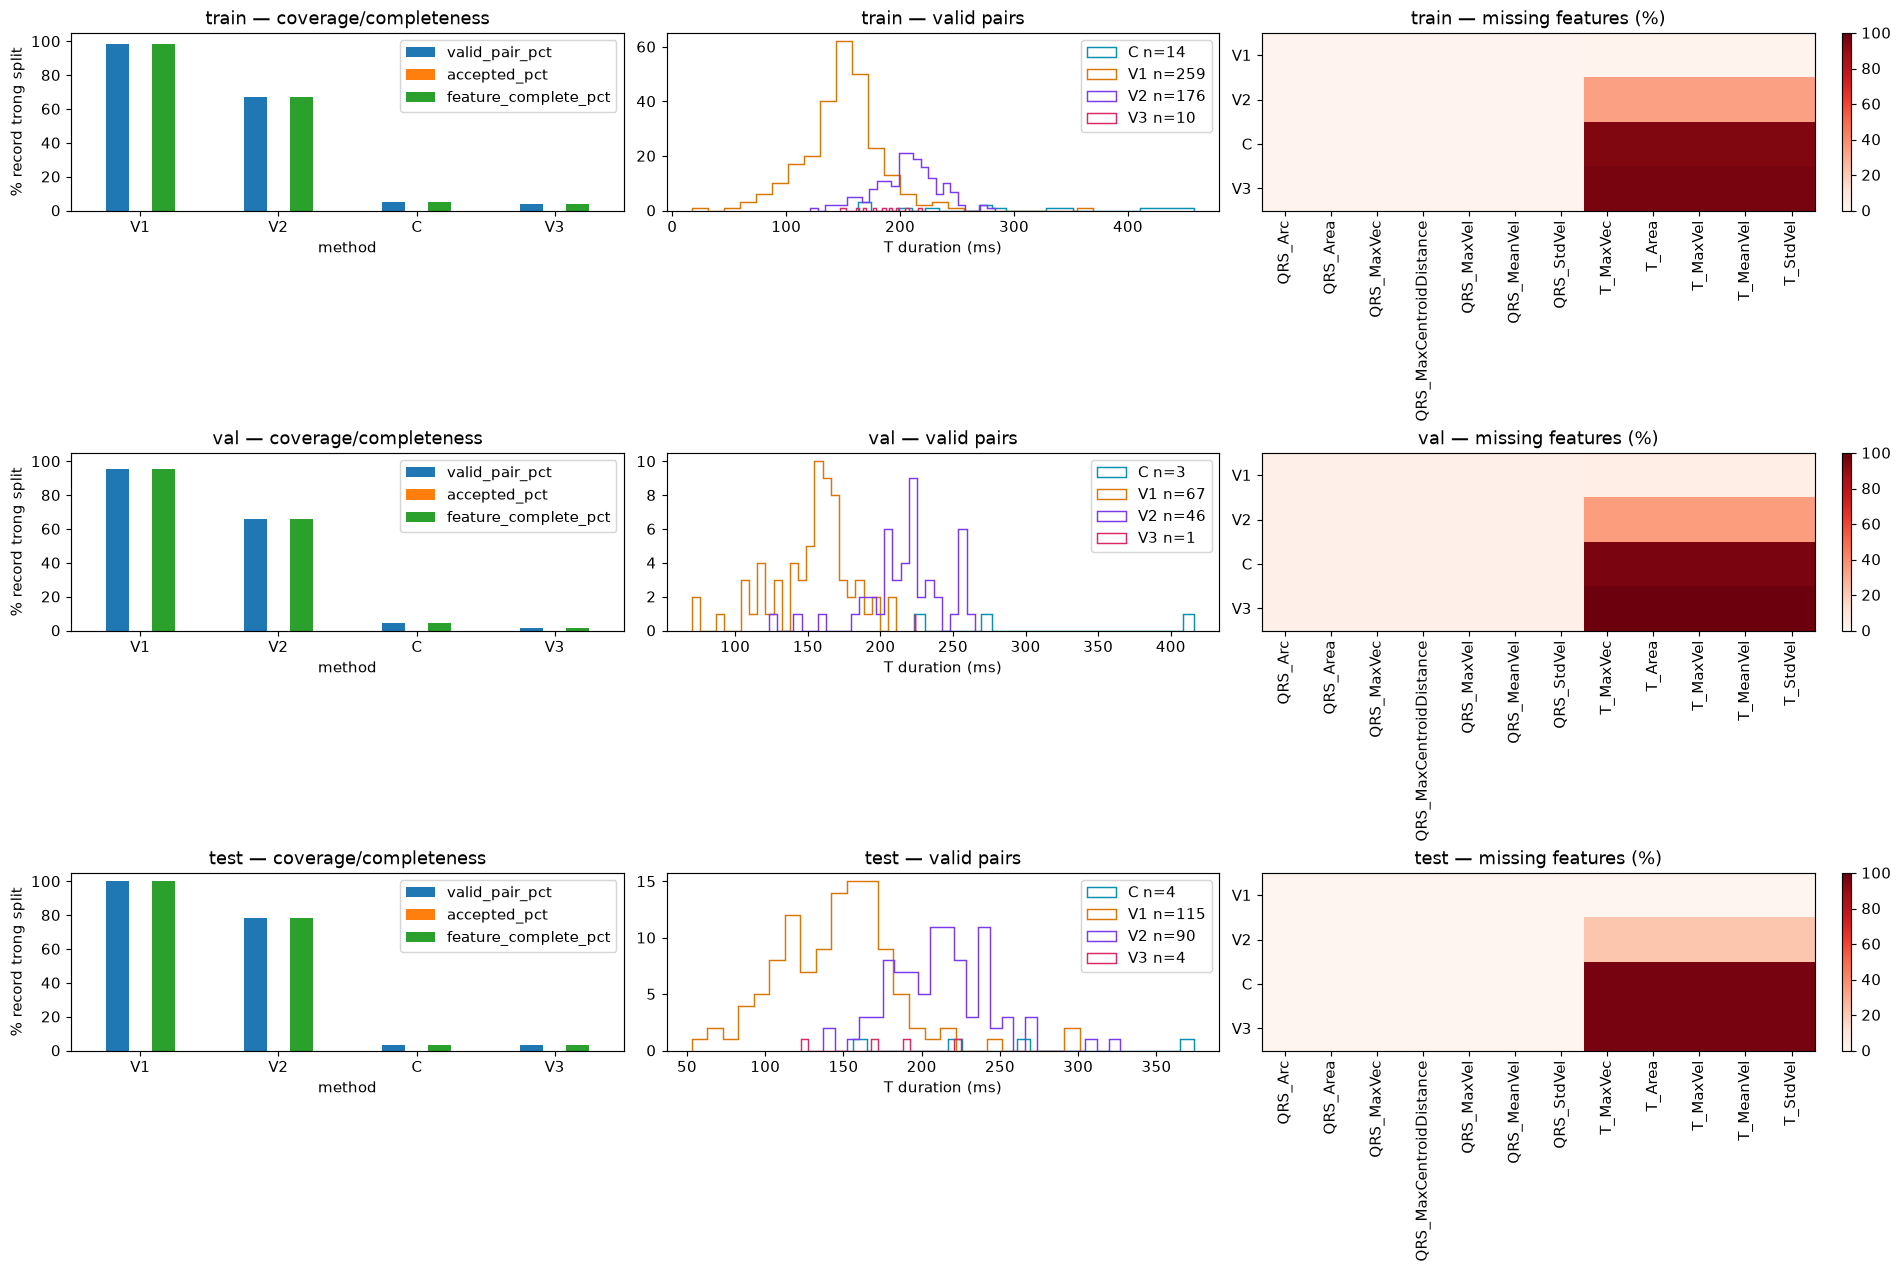

,method,split,label_name,attempted,patients,valid,accepted,feature_complete
0,C,test,HC,17,13,0,0,0
1,C,test,MI,98,37,4,0,4
2,C,train,HC,47,31,8,0,8
3,C,train,MI,216,89,6,0,6
4,C,val,HC,16,8,0,0,0
5,C,val,MI,54,22,3,0,3
6,V1,test,HC,17,13,17,0,17
7,V1,test,MI,98,37,98,0,98
8,V1,train,HC,47,31,47,0,47
9,V1,train,MI,216,89,212,0,212


,split,method,flag,records
0,test,C,Các ngưỡng PSD/persistence/quiet là heuristic ...,115
3,test,C,invalid_or_missing_T_pair,111
14,test,C,threshold_crossing_missing,111
2,test,C,different_morphology_retained_review,26
9,test,C,powerline_inconclusive_review,22
...,...,...,...,...
190,val,V3,Không đủ khoảng ít hoạt động/độ dài/span để ki...,3
192,val,V3,input_or_pipeline_error,2
195,val,V3,many_excluded_beats,2
202,val,V3,rr_irregular,2


In [45]:
cx_splits=[s for s in ('train','val','test') if s in set(cx_eval.split)]
fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4*len(cx_splits)),squeeze=False,layout='constrained')
for s,ax in zip(cx_splits,axes):
    part=cx_eval[cx_eval.split.eq(s)]; summary=cx_coverage[cx_coverage.split.eq(s)]
    summary.set_index('method')[['valid_pair_pct','accepted_pct','feature_complete_pct']].plot.bar(ax=ax[0],rot=0)
    ax[0].set(ylabel='% record trong split',ylim=(0,105),title=s+' — coverage/completeness')
    for m,g in part.groupby('method'):
        x=pd.to_numeric(g.duration_ms,errors='coerce').dropna()
        if len(x): ax[1].hist(x,bins=25,histtype='step',label=f'{m} n={len(x)}',color=CX_COLORS[m])
    ax[1].set(xlabel='T duration (ms)',title=s+' — valid pairs')
    if ax[1].has_data(): ax[1].legend()
    missing=part.groupby('method')[FEATURE_NAMES].agg(lambda x:100*x.isna().mean()).reindex(CX_METHODS)
    im=ax[2].imshow(missing.to_numpy(dtype=float),aspect='auto',vmin=0,vmax=100,cmap='Reds')
    ax[2].set(yticks=range(len(missing)),yticklabels=missing.index,xticks=range(len(FEATURE_NAMES)),
              xticklabels=FEATURE_NAMES,title=s+' — missing features (%)')
    ax[2].tick_params(axis='x',rotation=90);fig.colorbar(im,ax=ax[2])
cx_show(fig,'coverage_missingness_by_split')
cx_subgroups=cx_eval.groupby(['method','split','label_name'],dropna=False).agg(
    attempted=('record_id','size'),patients=('patient_id','nunique'),valid=('valid_pair','sum'),
    accepted=('accepted','sum'),feature_complete=('feature_complete','sum')).reset_index()
display(cx_subgroups)
cx_flags=cx_eval.assign(flag=cx_eval['flags'].fillna('').str.split(';')).explode('flag')
cx_flags=cx_flags[cx_flags.flag.ne('')].groupby(['split','method','flag']).size().rename('records').reset_index()
display(cx_flags.sort_values(['split','method','records'],ascending=[True,True,False]))
CX_RESULTS.update(flags=cx_flags,coverage_by_label=cx_subgroups)


### Chênh lệch từng cặp, Bland–Altman và overlap

Ở mọi cột delta, dấu dương nghĩa là method bên phải đặt mốc muộn hơn method bên trái. Ví dụ V1→V3 onset +20 ms là onset V3 muộn hơn 20 ms. Median absolute delta là khoảng cách giữa hai phương pháp, không phải sai số với nhãn thật. Với một record không tính được SD/limits đáng tin; đợi cohort.

Các feature QRS phải giữ nguyên giữa V1/V2/C/V3 vì chưa thay QRS hay preprocessing. Bảng pairwise đầy đủ còn có các cột chênh lệch từng feature, relative delta và Spearman trên paired valid records.

**Nếu hình ít điểm hoặc trống:** xem `valid_pairs` trong bảng cell 92 và `valid_pair/flags` ở cell 88–90. Một demo chỉ có 1 điểm cho mỗi cặp hợp lệ; V3 unresolved sẽ không có điểm cho các cặp chứa V3. Hình mới vẽ tất cả cặp có dữ liệu, kèm tên và số điểm; vùng không có dữ liệu được ghi rõ, không thay NaN bằng 0.

,split,left,right,attempted_pairs,valid_pairs,both_accepted,median_iou,median_dice,t_on_ms_median_abs,t_off_ms_median_abs,duration_median_abs_difference_ms
0,test,V1,V2,115,90,0,0.661993,0.796626,41.0,27.0,73.0
1,test,V1,C,115,4,0,0.541971,0.700941,48.0,64.5,112.5
2,test,V1,V3,115,4,0,0.896423,0.945352,10.5,10.0,18.5
3,test,V2,C,115,4,0,0.742307,0.851161,16.5,41.0,43.0
4,test,V2,V3,115,4,0,0.916818,0.956594,9.0,7.0,15.0
5,test,C,V3,115,1,0,0.923077,0.960000,7.0,6.0,13.0
6,train,V1,V2,263,176,0,0.694608,0.819786,39.0,27.0,63.0
7,train,V1,C,263,14,0,0.499975,0.666123,66.0,35.5,148.5
8,train,V1,V3,263,10,0,0.874761,0.933170,12.0,10.5,21.0
9,train,V2,C,263,12,0,0.618706,0.764423,43.5,67.5,88.5


,left,right,attempted_pairs,valid_pairs,both_accepted,t_on_ms_bias,t_on_ms_median_signed,t_on_ms_median_abs,t_on_ms_p90_abs,t_on_ms_sd,t_on_ms_loa_low,t_on_ms_loa_high,t_on_ms_within_10ms_pct,t_on_ms_within_20ms_pct,t_on_ms_within_25ms_pct,t_on_ms_within_40ms_pct,t_on_ms_within_50ms_pct,t_off_ms_bias,t_off_ms_median_signed,t_off_ms_median_abs,...,T_MaxVec_median_abs_delta,T_MaxVec_median_relative_delta_pct,T_MaxVec_spearman,T_Area_paired_n,T_Area_median_abs_delta,T_Area_median_relative_delta_pct,T_Area_spearman,T_MaxVel_paired_n,T_MaxVel_median_abs_delta,T_MaxVel_median_relative_delta_pct,T_MaxVel_spearman,T_MeanVel_paired_n,T_MeanVel_median_abs_delta,T_MeanVel_median_relative_delta_pct,T_MeanVel_spearman,T_StdVel_paired_n,T_StdVel_median_abs_delta,T_StdVel_median_relative_delta_pct,T_StdVel_spearman,split
0,V1,V2,115,90,0,-36.900000,-39.5,41.0,59.1,28.595611,-92.947398,19.147398,0.000000,4.444444,8.888889,48.888889,74.444444,30.244444,27.0,27.0,...,0.0,0.0,0.999095,90,0.001691,16.296561,0.971108,90,0.0,0.0,0.959567,90,0.494671,-15.374065,0.979948,90,0.106402,6.694502,0.938923,test
1,V1,C,115,4,0,-46.500000,-48.0,48.0,65.9,21.641010,-88.916380,-4.083620,0.000000,0.000000,25.000000,50.000000,50.000000,80.250000,64.5,64.5,...,0.0,0.0,1.000000,4,0.000894,8.151191,1.000000,4,0.0,0.0,1.000000,4,1.069771,-19.790606,0.800000,4,0.114785,8.159943,1.000000,test
2,V1,V3,115,4,0,-13.750000,-10.5,10.5,23.6,10.500000,-34.330000,6.830000,50.000000,75.000000,75.000000,100.000000,100.000000,14.250000,10.0,10.0,...,0.0,0.0,1.000000,4,0.000713,7.073352,1.000000,4,0.0,0.0,1.000000,4,0.099923,-3.504249,1.000000,4,0.017785,1.719140,1.000000,test
3,V2,C,115,4,0,-6.250000,-1.0,16.5,33.1,26.986108,-59.142771,46.642771,0.000000,75.000000,75.000000,100.000000,100.000000,49.250000,31.5,41.0,...,0.0,0.0,1.000000,4,0.000176,-0.554129,1.000000,4,0.0,0.0,1.000000,4,0.447489,-8.187942,0.800000,4,0.057120,-0.162067,1.000000,test
4,V2,V3,115,4,0,9.000000,9.0,9.0,11.7,2.943920,3.229916,14.770084,50.000000,100.000000,100.000000,100.000000,100.000000,-7.250000,-7.0,7.0,...,0.0,0.0,1.000000,4,0.000563,-3.952865,1.000000,4,0.0,0.0,1.000000,4,0.116454,4.705380,1.000000,4,0.035054,-2.771372,1.000000,test
5,C,V3,115,1,0,-7.000000,-7.0,7.0,7.0,NaN,NaN,NaN,100.000000,100.000000,100.000000,100.000000,100.000000,6.000000,6.0,6.0,...,0.0,0.0,NaN,1,0.000060,-0.710721,NaN,1,0.0,0.0,NaN,1,0.171172,-4.470772,NaN,1,0.064574,4.377343,NaN,test
6,V1,V2,263,176,0,-29.642045,-36.0,39.0,56.5,29.750625,-87.953271,28.669180,5.681818,14.204545,17.045455,55.113636,81.818182,28.659091,26.5,27.0,...,0.0,0.0,0.999987,176,0.001924,14.056664,0.978715,176,0.0,0.0,0.996163,176,0.476808,-14.273043,0.976014,176,0.101102,6.142005,0.969245,train
7,V1,C,263,14,0,-70.571429,-66.0,66.0,119.6,48.037989,-164.725886,23.583029,0.000000,0.000000,28.571429,35.714286,42.857143,78.071429,35.5,35.5,...,0.0,0.0,1.000000,14,0.000883,10.622424,0.991209,14,0.0,0.0,1.000000,14,0.958856,-25.803547,0.709890,14,0.124084,7.092200,0.916484,train
8,V1,V3,263,10,0,-18.500000,-12.0,12.0,41.3,16.787892,-51.404269,14.404269,30.000000,70.000000,70.000000,70.000000,100.000000,11.300000,10.5,10.5,...,0.0,0.0,1.000000,10,0.000853,7.288715,1.000000,10,0.0,0.0,1.000000,10,0.192826,-5.387338,0.915152,10,0.052942,2.536393,1.000000,train
9,V2,C,263,12,0,-39.333333,-43.5,43.5,81.5,55.614474,-148.337702,69.671035,8.333333,25.000000,33.333333,50.000000,58.333333,57.250000,57.0,67.5,...,0.0,0.0,1.000000,12,0.000188,-0.485623,0.986014,12,0.0,0.0,1.000000,12,0.554507,-14.798253,0.769231,12,0.055414,2.043773,0.986014,train


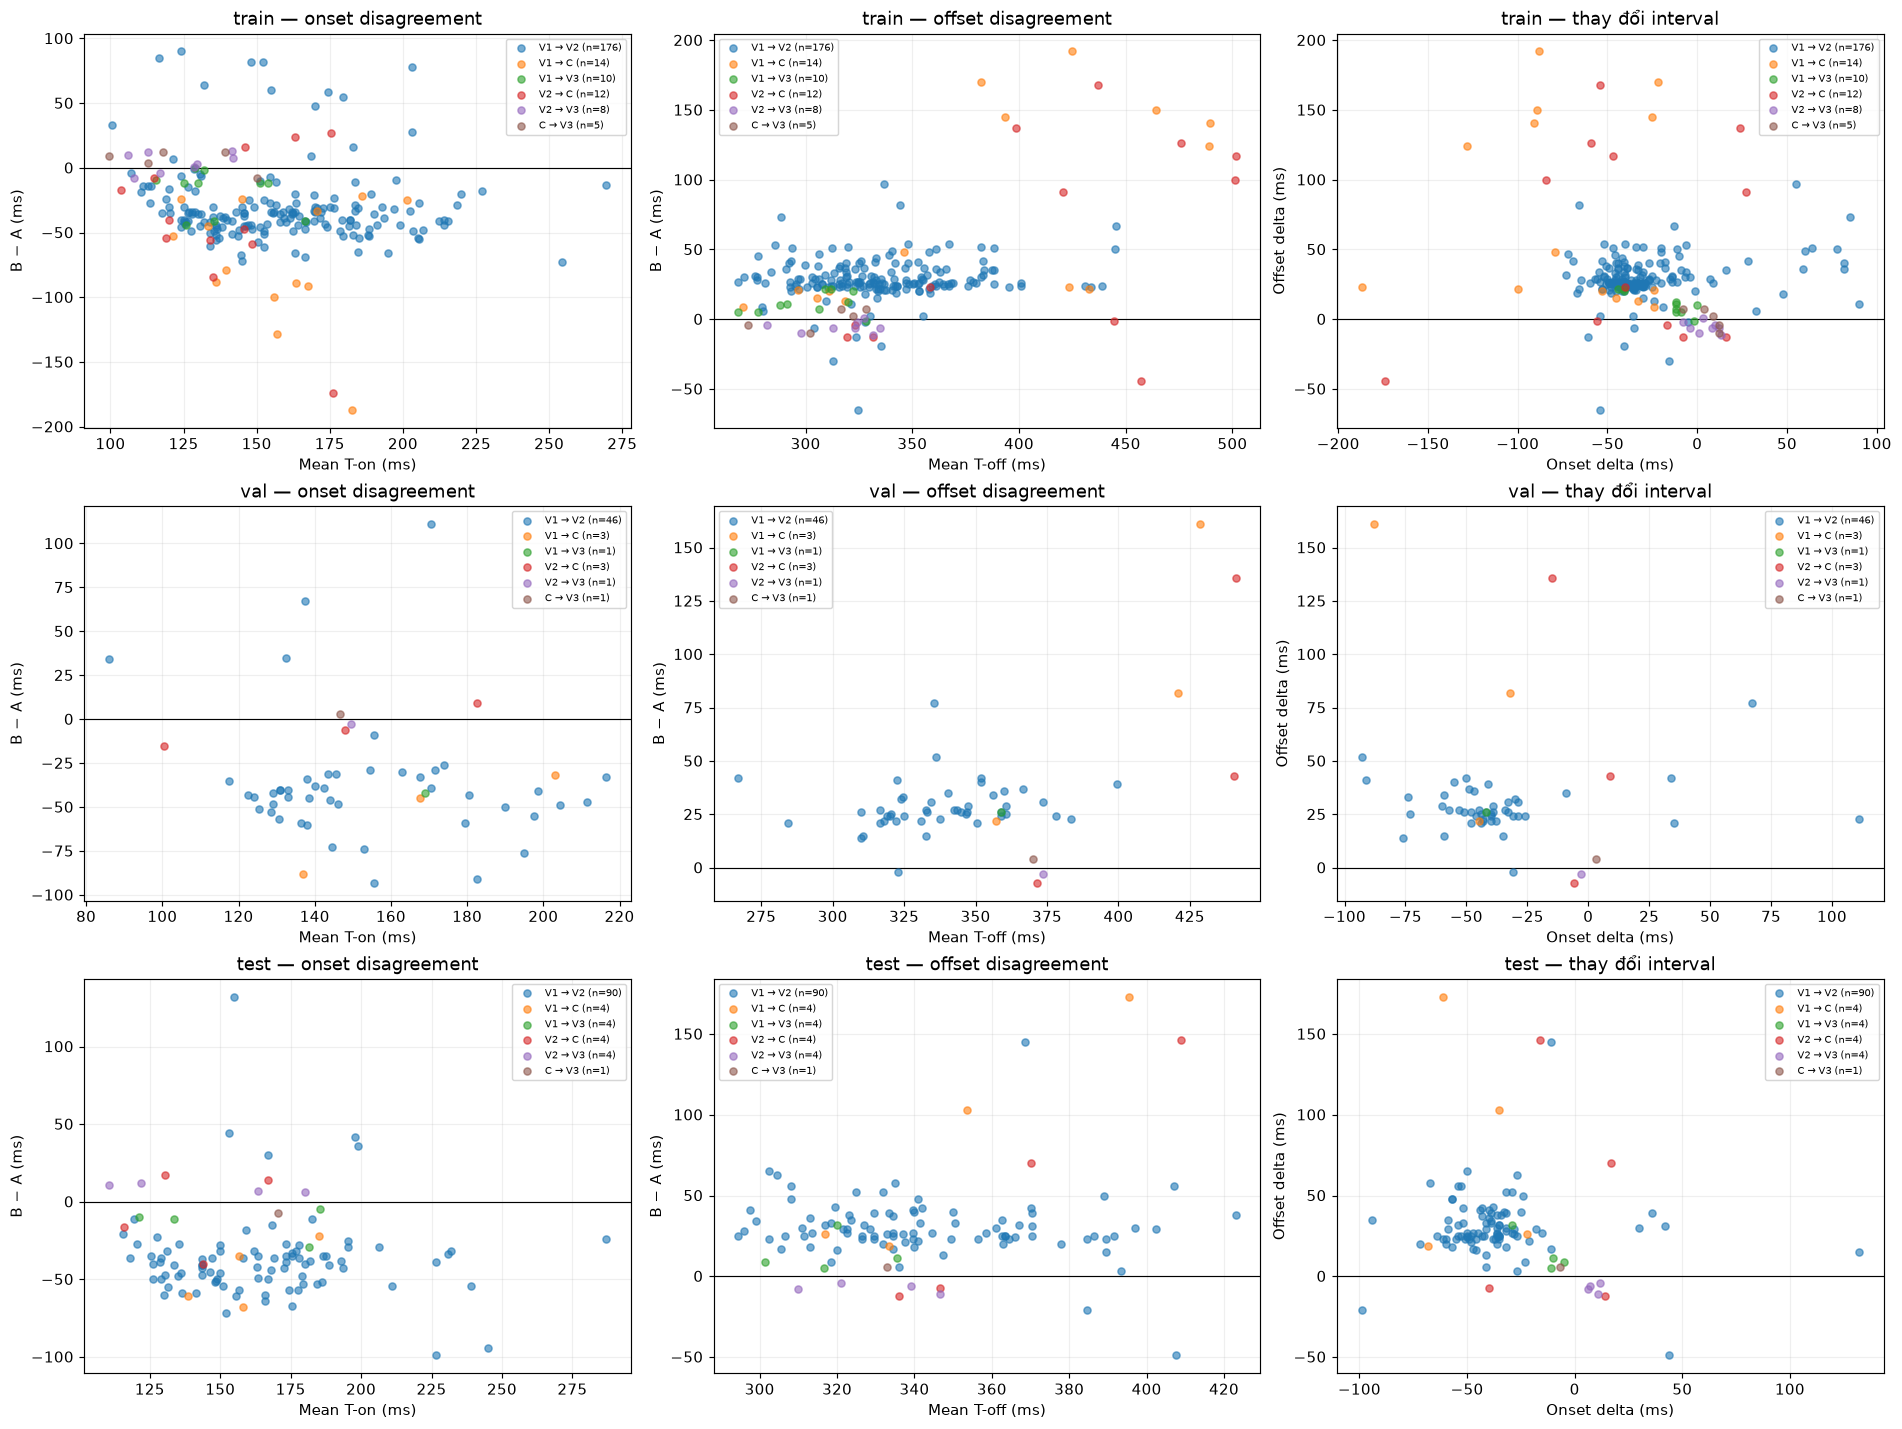

,method,metric,estimate,low,high,patients,note,split
0,C,accepted_rate,0.0,0.0,0.0,50,95% percentile patient-cluster bootstrap; desc...,test
1,V1,accepted_rate,0.0,0.0,0.0,50,95% percentile patient-cluster bootstrap; desc...,test
2,V2,accepted_rate,0.0,0.0,0.0,50,95% percentile patient-cluster bootstrap; desc...,test
3,V3,accepted_rate,0.0,0.0,0.0,50,95% percentile patient-cluster bootstrap; desc...,test
4,C,accepted_rate,0.0,0.0,0.0,120,95% percentile patient-cluster bootstrap; desc...,train
5,V1,accepted_rate,0.0,0.0,0.0,120,95% percentile patient-cluster bootstrap; desc...,train
6,V2,accepted_rate,0.0,0.0,0.0,120,95% percentile patient-cluster bootstrap; desc...,train
7,V3,accepted_rate,0.0,0.0,0.0,120,95% percentile patient-cluster bootstrap; desc...,train
8,C,accepted_rate,0.0,0.0,0.0,30,95% percentile patient-cluster bootstrap; desc...,val
9,V1,accepted_rate,0.0,0.0,0.0,30,95% percentile patient-cluster bootstrap; desc...,val


In [46]:
cx_pairs_list=[]; cx_details_list=[]
for split,g in cx_eval.groupby('split',sort=False):
    summary,details=cx_pairwise(g)
    cx_pairs_list.append(summary.assign(split=split))
    if not details.empty: cx_details_list.append(details.assign(split=split))
cx_pairs=pd.concat(cx_pairs_list,ignore_index=True)
cx_pair_details=pd.concat(cx_details_list,ignore_index=True) if cx_details_list else pd.DataFrame()
base_cols=['split','left','right','attempted_pairs','valid_pairs','both_accepted','median_iou','median_dice',
           't_on_ms_median_abs','t_off_ms_median_abs','duration_median_abs_difference_ms']
display(cx_pairs.reindex(columns=base_cols));display(cx_pairs)
fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4.5*len(cx_splits)),squeeze=False,layout='constrained')
for split,axs in zip(cx_splits,axes):
    part=cx_pair_details[cx_pair_details.split.eq(split)] if not cx_pair_details.empty else pd.DataFrame()
    if not part.empty:
        for j,((a,b),g) in enumerate(part.groupby(['left','right'],sort=False)):
            color=plt.get_cmap('tab10')(j%10); label=f'{a} → {b} (n={len(g)})'
            for ax,x,y in ((axs[0],g.on_mean_ms,g.on_delta_ms),(axs[1],g.off_mean_ms,g.off_delta_ms),
                           (axs[2],g.on_delta_ms,g.off_delta_ms)):
                ax.scatter(x,y,s=24,alpha=.6,color=color,label=label,zorder=5)
        for ax in axs:ax.legend(fontsize=7)
    else:
        for ax in axs:ax.text(.5,.5,'Không có cặp biên hợp lệ chung.\nXem valid_pairs và flags.',ha='center',va='center',transform=ax.transAxes)
    for ax in axs:ax.axhline(0,color='black',lw=.8);ax.grid(alpha=.2)
    axs[0].set(xlabel='Mean T-on (ms)',ylabel='B − A (ms)',title=split+' — onset disagreement')
    axs[1].set(xlabel='Mean T-off (ms)',ylabel='B − A (ms)',title=split+' — offset disagreement')
    axs[2].set(xlabel='Onset delta (ms)',ylabel='Offset delta (ms)',title=split+' — thay đổi interval')
cx_show(fig,'pairwise_boundary_deltas_by_split')
for feature in [f for f in FEATURE_NAMES if f.startswith('QRS_')]:
    assert cx_eval.pivot(index='record_id',columns='method',values=feature).nunique(axis=1,dropna=True).le(1).all(), feature
cx_ci=pd.concat([cx_patient_ci(g).assign(split=s) for s,g in cx_eval.groupby('split',sort=False)],ignore_index=True)
display(cx_ci)
CX_RESULTS.update(pairwise_summary=cx_pairs,pairwise_details=cx_pair_details,patient_bootstrap_ci=cx_ci)


### Cùng nhiễu, cùng seeds: V1/V2/C/V3 có đổi quyết định không?

Noise thêm vào **median beat**, giữ nguyên anchors/RR/PQ/QRS detector raw; vì vậy đây là stability của tầng delineation. Scale noise = 0.5/1/2% robust scale XYZ, không phải SNR sinh lý đã biết. Báo cáo cả lần mất biên; delta chỉ tính khi trước và sau đều valid. Một phương pháp luôn thất bại không được xem là ổn định vì delta NaN.

Option bootstrap lấy mẫu lại các beat đã giữ rồi tạo median mới kiểm tra thêm độ phụ thuộc vào beat selection. Nó chưa chạy lại toàn bộ raw preprocessing và không đại diện biến thiên giữa bệnh nhân.

**Cách xem hình:** hai ô đầu là jitter có điều kiện trên những lần cả trước/sau nhiễu đều có biên hợp lệ. Ô thứ ba cho biết bao nhiêu % lần đủ điều kiện tính jitter. Đường ở 0 ms nghĩa là có đo và mốc không đổi; thiếu đường/NaN nghĩa là thiếu cặp đo, không phải thuật toán hoàn hảo.
**Phạm vi:** mặc định tất cả record đã chọn; bảng và ba ô hình lặp riêng train/valid/test. `records`, `repetitions`, `paired_n` cho biết mẫu số. Input lỗi vẫn giữ các lần thử nhưng jitter để NaN.


stability 1/448 | cache 1 | failures 0
stability 10/448 | cache 10 | failures 0
stability 20/448 | cache 20 | failures 0
stability 30/448 | cache 30 | failures 0
stability 40/448 | cache 40 | failures 0
stability 50/448 | cache 50 | failures 0
stability 60/448 | cache 60 | failures 0
stability 70/448 | cache 70 | failures 0
stability 80/448 | cache 80 | failures 0
stability 90/448 | cache 90 | failures 0
stability 100/448 | cache 100 | failures 0
stability 110/448 | cache 110 | failures 0
stability 120/448 | cache 120 | failures 0
stability 130/448 | cache 130 | failures 0
stability 140/448 | cache 140 | failures 0
stability 150/448 | cache 150 | failures 0
stability 160/448 | cache 160 | failures 0
stability 170/448 | cache 169 | failures 1
stability 180/448 | cache 178 | failures 2
stability 190/448 | cache 188 | failures 2
stability 200/448 | cache 198 | failures 2
stability 210/448 | cache 208 | failures 2
stability 220/448 | cache 218 | failures 2
stability 230/448 | cache 228 | f

,method,level,seed,sigma_mV,base_valid,perturbed_valid,accepted,native_status,status_changed,on_delta_ms,off_delta_ms,record_id,patient_id,split,label_name,abs_on_delta_ms,abs_off_delta_ms
0,V1,0.005,0,0.000217,True,True,False,detected,0.0,0.0,3.0,patient150/s0287lre,patient150,test,HC,0.0,3.0
1,V2,0.005,0,0.000217,True,True,False,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
2,C,0.005,0,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
3,V3,0.005,0,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
4,V1,0.005,1,0.000217,True,True,False,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
5,V2,0.005,1,0.000217,True,True,False,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
6,C,0.005,1,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
7,V3,0.005,1,0.000217,False,False,False,unresolved,0.0,NaN,NaN,patient150/s0287lre,patient150,test,HC,NaN,NaN
8,V1,0.005,2,0.000217,True,True,False,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0
9,V2,0.005,2,0.000217,True,True,False,detected,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC,0.0,0.0


,split,method,level,records,repetitions,base_valid,retained_valid,accepted,status_flip_rate,paired_n,on_median_abs_ms,off_median_abs_ms,on_p90_abs_ms,off_p90_abs_ms,paired_pct,valid_retention_pct
0,test,C,0.005,115,575,20,20,0,0.000000,20,0.0,0.0,0.1,0.0,3.478261,100.000000
1,test,C,0.010,115,575,20,21,0,0.001739,20,0.0,0.0,1.0,0.0,3.478261,100.000000
2,test,C,0.020,115,575,20,24,0,0.006957,20,0.0,0.0,1.0,1.0,3.478261,100.000000
3,test,V1,0.005,115,575,575,575,0,0.000000,575,0.0,0.0,1.0,1.0,100.000000,100.000000
4,test,V1,0.010,115,575,575,575,0,0.000000,575,0.0,0.0,1.0,1.0,100.000000,100.000000
5,test,V1,0.020,115,575,575,575,0,0.000000,575,0.0,0.0,1.0,2.0,100.000000,100.000000
6,test,V2,0.005,115,575,450,447,0,0.005217,447,0.0,0.0,0.0,0.0,77.739130,99.333333
7,test,V2,0.010,115,575,450,447,0,0.005217,447,0.0,0.0,0.4,0.0,77.739130,99.333333
8,test,V2,0.020,115,575,450,448,0,0.010435,446,0.0,0.0,1.0,0.0,77.565217,99.111111
9,test,V3,0.005,115,575,20,20,0,0.000000,20,0.0,0.0,1.0,0.0,3.478261,100.000000


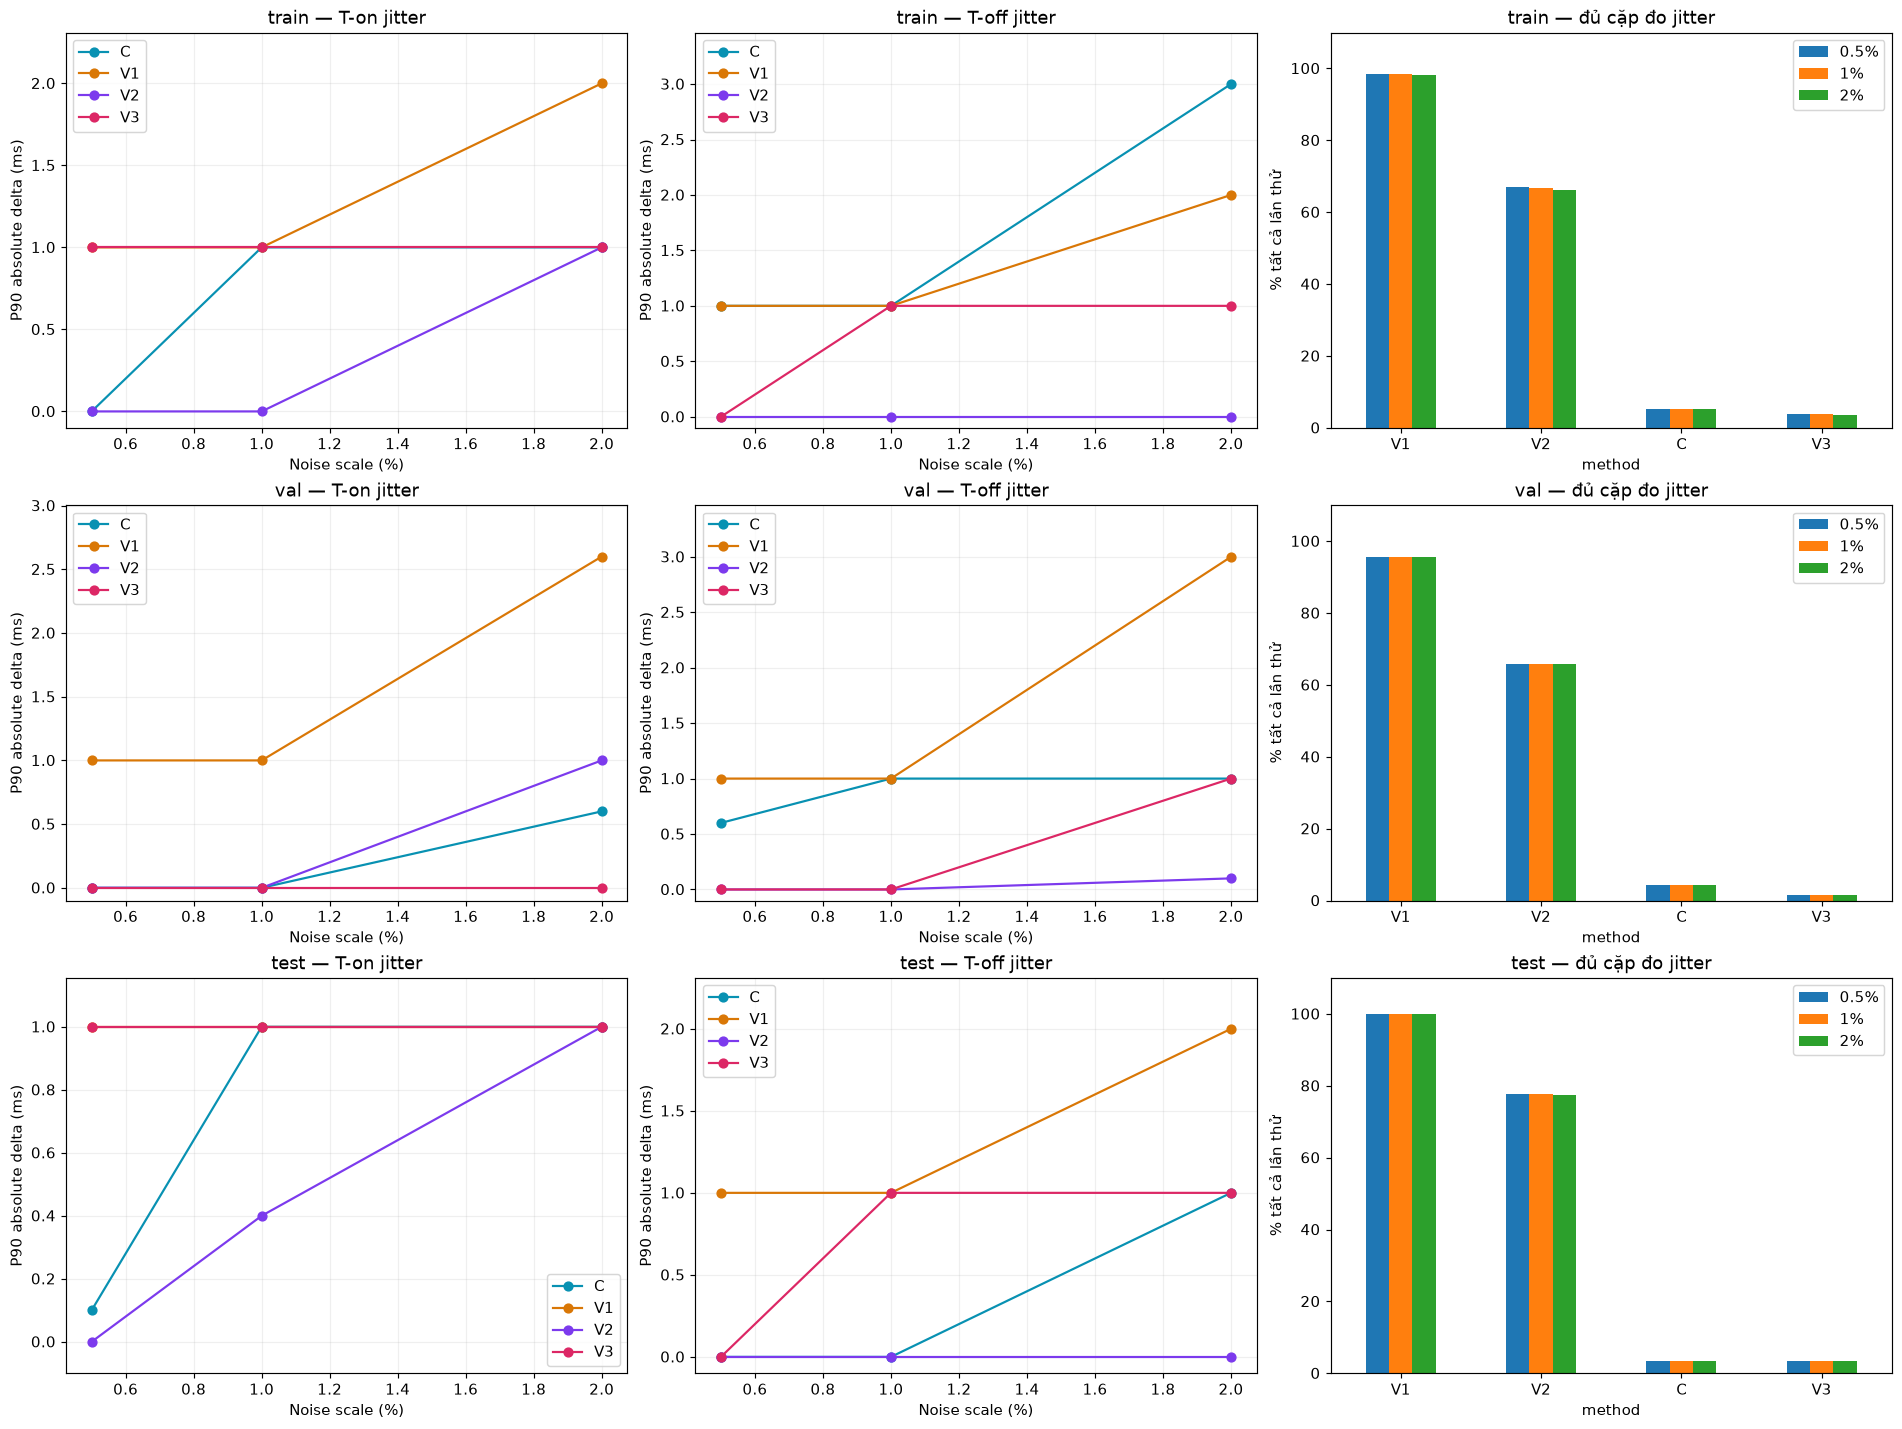

Jitter=0 có cặp đo; NaN không phải 0. valid_retention_pct dùng mẫu số base_valid.


,split,method,records,repetitions,paired_n,onset_p90_ms,offset_p90_ms
0,test,C,115,1150,25,8.6,17.2
1,test,V1,115,1150,1144,11.0,8.0
2,test,V2,115,1150,875,6.0,4.0
3,test,V3,115,1150,19,7.4,3.0
4,train,C,263,2630,106,7.5,27.5
5,train,V1,263,2630,2576,12.0,8.0
6,train,V2,263,2630,1710,5.0,4.0
7,train,V3,263,2630,64,4.0,4.0
8,val,C,70,700,18,21.3,11.5
9,val,V1,70,700,665,10.6,9.0


In [47]:
cx_stability=pd.DataFrame(); cx_beat_bootstrap=pd.DataFrame()
if CX_RUN_STABILITY:
    cx_stability,stability_errors=cx_run_task('stability',cx_selected)
    CX_RESULTS['stability_errors']=stability_errors
if CX_RUN_BOOTSTRAP:
    cx_beat_bootstrap,bootstrap_errors=cx_run_task('bootstrap',cx_selected)
    CX_RESULTS['bootstrap_errors']=bootstrap_errors
if not cx_stability.empty:
    for column in ('on_delta_ms','off_delta_ms','status_changed'):
        cx_stability[column]=pd.to_numeric(cx_stability[column],errors='coerce')
    cx_stability['abs_on_delta_ms']=cx_stability.on_delta_ms.abs()
    cx_stability['abs_off_delta_ms']=cx_stability.off_delta_ms.abs()
    cx_preview(cx_stability)
    stability_summary=cx_stability.groupby(['split','method','level']).agg(
        records=('record_id','nunique'),repetitions=('seed','size'),base_valid=('base_valid','sum'),
        retained_valid=('perturbed_valid','sum'),accepted=('accepted','sum'),status_flip_rate=('status_changed','mean'),
        paired_n=('on_delta_ms','count'),on_median_abs_ms=('abs_on_delta_ms','median'),
        off_median_abs_ms=('abs_off_delta_ms','median'),on_p90_abs_ms=('abs_on_delta_ms',lambda s:s.quantile(.9)),
        off_p90_abs_ms=('abs_off_delta_ms',lambda s:s.quantile(.9))).reset_index()
    stability_summary['paired_pct']=100*stability_summary.paired_n/stability_summary.repetitions
    stability_summary['valid_retention_pct']=100*stability_summary.paired_n/stability_summary.base_valid.replace(0,np.nan)
    display(stability_summary)
    fig,axes=plt.subplots(len(cx_splits),3,figsize=(18,4.5*len(cx_splits)),squeeze=False,layout='constrained')
    for split,axs in zip(cx_splits,axes):
        part=stability_summary[stability_summary.split.eq(split)]
        for ax,metric,title in ((axs[0],'on_p90_abs_ms','T-on jitter'),(axs[1],'off_p90_abs_ms','T-off jitter')):
            plotted=False
            for m,g in part.groupby('method',sort=False):
                good=np.isfinite(g[metric])
                if good.any():ax.plot(g.loc[good,'level']*100,g.loc[good,metric],'o-',color=CX_COLORS[m],label=m);plotted=True
            if plotted: ax.legend();ax.set_ylim(bottom=-.1,top=max(1.,ax.get_ylim()[1]*1.1))
            else: ax.text(.5,.5,'Jitter NaN: không có cặp đo hợp lệ.',ha='center',transform=ax.transAxes)
            ax.set(xlabel='Noise scale (%)',ylabel='P90 absolute delta (ms)',title=split+' — '+title);ax.grid(alpha=.2)
        pairing=part.pivot(index='method',columns='level',values='paired_pct').reindex(CX_METHODS)
        pairing.columns=[f'{100*float(v):g}%' for v in pairing.columns]
        pairing.plot.bar(ax=axs[2],rot=0)
        axs[2].set(ylim=(0,110),ylabel='% tất cả lần thử',title=split+' — đủ cặp đo jitter')
    cx_show(fig,'delineation_stability_by_split')
    print('Jitter=0 có cặp đo; NaN không phải 0. valid_retention_pct dùng mẫu số base_valid.')
    CX_RESULTS['stability_summary']=stability_summary
if not cx_beat_bootstrap.empty:
    for column in ('on_delta_ms','off_delta_ms'):
        cx_beat_bootstrap[column]=pd.to_numeric(cx_beat_bootstrap[column],errors='coerce')
        cx_beat_bootstrap['abs_'+column]=cx_beat_bootstrap[column].abs()
    bootstrap_summary=cx_beat_bootstrap.groupby(['split','method']).agg(
        records=('record_id','nunique'),repetitions=('repeat','size'),paired_n=('valid','sum'),
        onset_p90_ms=('abs_on_delta_ms',lambda s:s.quantile(.9)),offset_p90_ms=('abs_off_delta_ms',lambda s:s.quantile(.9))).reset_index()
    display(bootstrap_summary);CX_RESULTS['beat_bootstrap_summary']=bootstrap_summary
CX_RESULTS.update(stability=cx_stability,beat_bootstrap=cx_beat_bootstrap)


### Dịch biên ±5/10/20 ms và đo lại features

Chạy cùng tập shift cho mọi method có valid interval. Có 3 kiểu: chỉ onset, chỉ offset, hoặc dịch cả interval. Mỗi ca không còn đúng thứ tự hoặc loại peak ra ngoài đều giữ dòng invalid và NaN; không âm thầm clip vào mảng. Relative change dùng |baseline feature| ở mẫu số; baseline gần 0 được ghi NaN để tránh tỷ lệ khổng lồ vô nghĩa.

Heatmap chỉ hiển thị median |relative change| của các scenario valid, còn bảng invalid cho biết mẫu đã mất. Các feature có đơn vị khác nhau được xem riêng; không cộng Area, MaxVec và Velocity thành một thang tổng.
**Phạm vi:** tất cả record/method, kể cả baseline không có T (giữ invalid + lý do). Heatmap tách theo split, bảng scenario dùng khóa record/method/shift trước khi đếm, không đếm mỗi feature thành một lần thử.


sensitivity 1/448 | cache 1 | failures 0
sensitivity 10/448 | cache 10 | failures 0
sensitivity 20/448 | cache 20 | failures 0
sensitivity 30/448 | cache 30 | failures 0
sensitivity 40/448 | cache 40 | failures 0
sensitivity 50/448 | cache 50 | failures 0
sensitivity 60/448 | cache 60 | failures 0
sensitivity 70/448 | cache 70 | failures 0
sensitivity 80/448 | cache 80 | failures 0
sensitivity 90/448 | cache 90 | failures 0
sensitivity 100/448 | cache 100 | failures 0
sensitivity 110/448 | cache 110 | failures 0
sensitivity 120/448 | cache 120 | failures 0
sensitivity 130/448 | cache 130 | failures 0
sensitivity 140/448 | cache 140 | failures 0
sensitivity 150/448 | cache 150 | failures 0
sensitivity 160/448 | cache 160 | failures 0
sensitivity 170/448 | cache 169 | failures 1
sensitivity 180/448 | cache 178 | failures 2
sensitivity 190/448 | cache 188 | failures 2
sensitivity 200/448 | cache 198 | failures 2
sensitivity 210/448 | cache 208 | failures 2
sensitivity 220/448 | cache 218 

,method,scenario,on_shift_ms,off_shift_ms,represented_on_shift_ms,represented_off_shift_ms,valid,reason,feature,baseline,value,delta,abs_delta,relative_delta_pct,record_id,patient_id,split,label_name
0,V1,baseline,0,0,0.0,0.0,True,,QRS_Arc,5.163720,5.163720,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
1,V1,baseline,0,0,0.0,0.0,True,,QRS_Area,0.270612,0.270612,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
2,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVec,2.412297,2.412297,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
3,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxCentroidDistance,1.435421,1.435421,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
4,V1,baseline,0,0,0.0,0.0,True,,QRS_MaxVel,213.122252,213.122252,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
5,V1,baseline,0,0,0.0,0.0,True,,QRS_MeanVel,83.751363,83.751363,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
6,V1,baseline,0,0,0.0,0.0,True,,QRS_StdVel,51.293480,51.293480,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
7,V1,baseline,0,0,0.0,0.0,True,,T_MaxVec,0.674714,0.674714,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
8,V1,baseline,0,0,0.0,0.0,True,,T_Area,0.011304,0.011304,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC
9,V1,baseline,0,0,0.0,0.0,True,,T_MaxVel,12.934495,12.934495,0.0,0.0,0.0,patient150/s0287lre,patient150,test,HC


,split,method,valid,reason,record_scenarios
0,test,C,False,invalid_baseline,2109
1,test,C,True,,76
2,test,V1,False,order_peak_or_array_boundary,12
3,test,V1,True,,2173
4,test,V2,False,invalid_baseline,475
5,test,V2,True,,1710
6,test,V3,False,invalid_baseline,2109
7,test,V3,True,,76
8,train,C,False,input_or_pipeline_error,57
9,train,C,False,invalid_baseline,4674


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.258795,0.0,1.889172,1.872483
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.164817,0.0,1.712691,1.242236
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.636633,0.0,1.335833,0.556174
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2.015725,0.0,1.644490,1.544672


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.074821,0.0,1.885552,1.880585
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.076893,0.0,1.579736,1.060096
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.903609,0.0,0.872689,0.449244
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.547043,0.0,1.413805,0.761800


feature,QRS_Arc,QRS_Area,QRS_MaxVec,QRS_MaxCentroidDistance,QRS_MaxVel,QRS_MeanVel,QRS_StdVel,T_MaxVec,T_Area,T_MaxVel,T_MeanVel,T_StdVel
method,,,,,,,,,,,,
V1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4.250106,0.0,1.874808,1.875050
V2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.078104,0.0,1.645141,1.124690
C,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.567271,0.0,1.347539,0.981558
V3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.485288,0.0,1.673811,1.440695


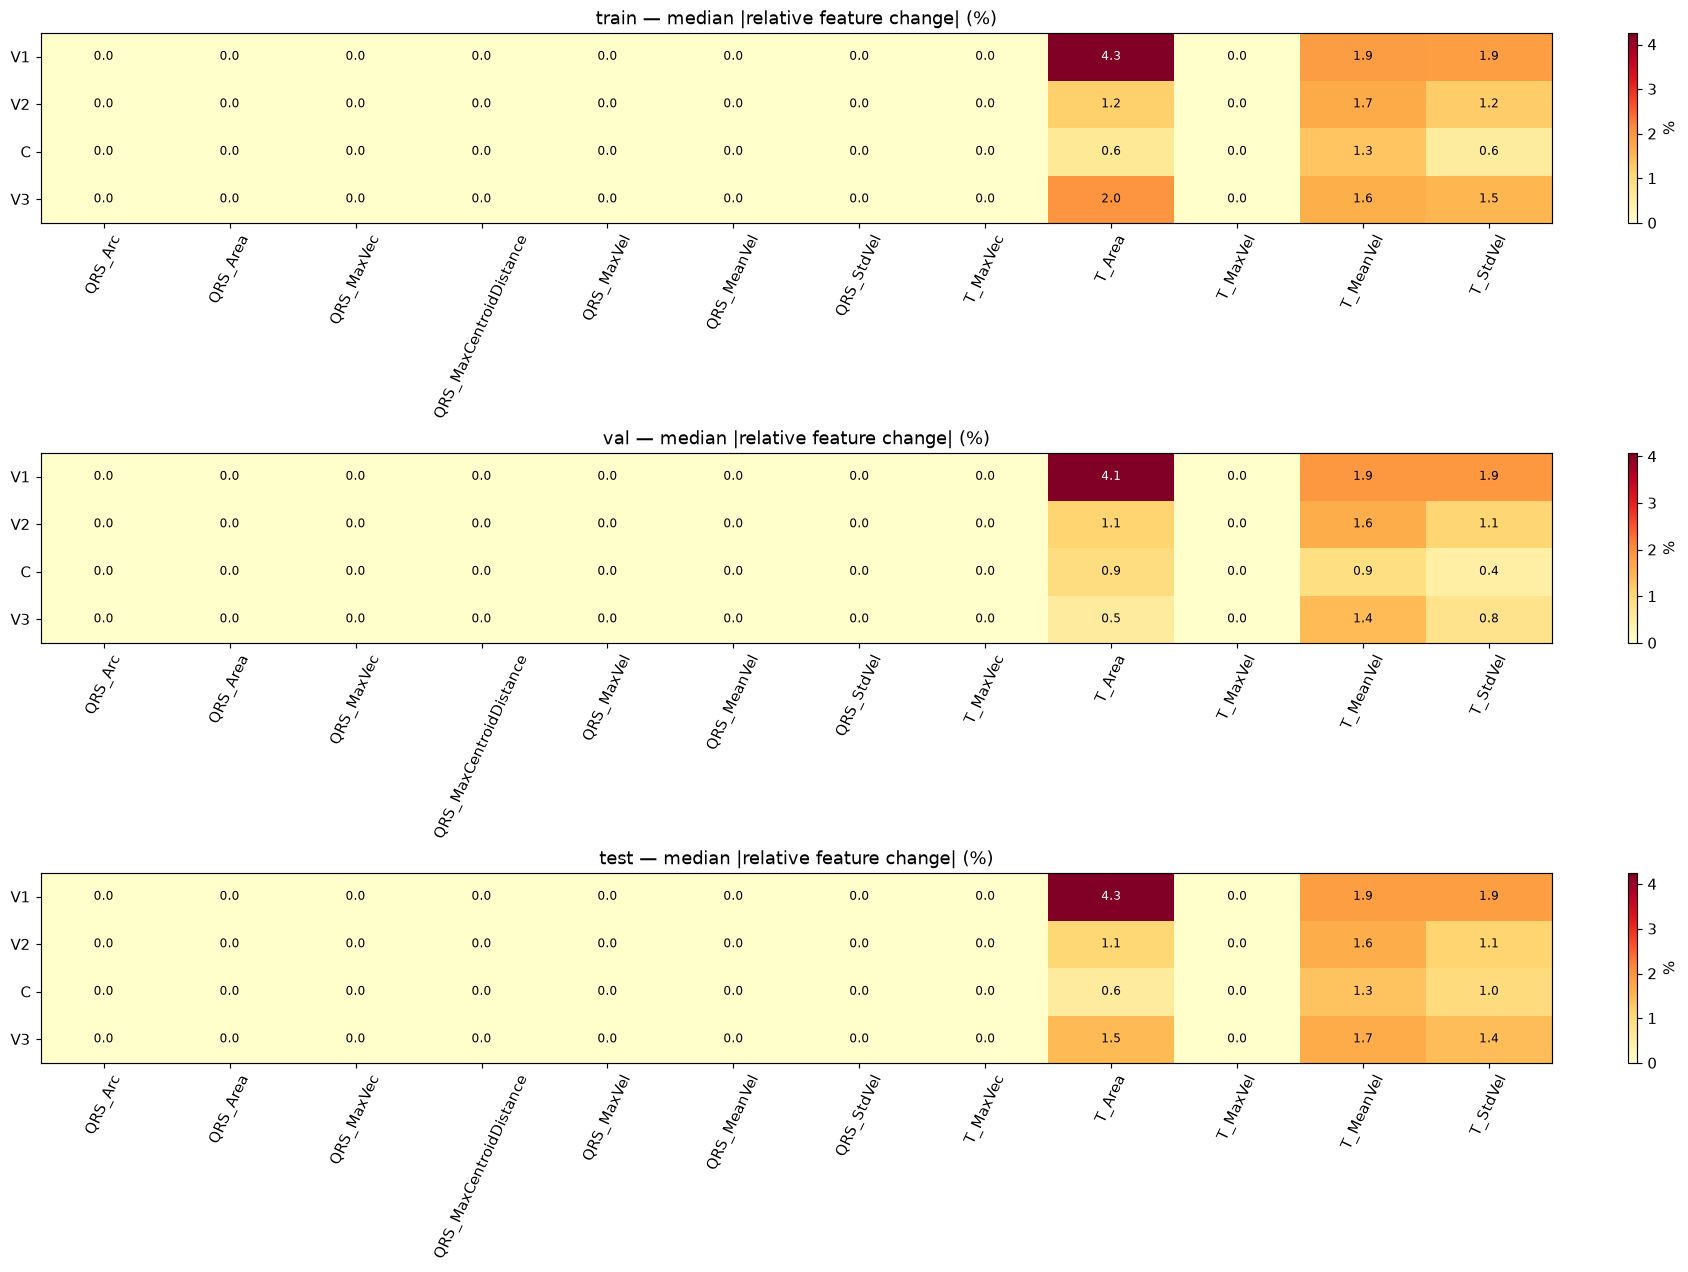

In [48]:
cx_sens=pd.DataFrame()
if CX_RUN_SENSITIVITY:
    cx_sens,sensitivity_errors=cx_run_task('sensitivity',cx_selected)
    CX_RESULTS['sensitivity_errors']=sensitivity_errors
if not cx_sens.empty:
    for column in ('relative_delta_pct','abs_delta'):cx_sens[column]=pd.to_numeric(cx_sens[column],errors='coerce')
    cx_preview(cx_sens)
    scenarios=cx_sens[['record_id','split','method','scenario','on_shift_ms','off_shift_ms','valid','reason']].drop_duplicates()
    scenario_summary=scenarios.groupby(['split','method','valid','reason'],dropna=False).size().rename('record_scenarios').reset_index()
    display(scenario_summary)
    vis=cx_sens[cx_sens.scenario.ne('baseline') & cx_sens.valid].copy()
    vis['abs_relative_pct']=vis.relative_delta_pct.abs()
    fig,axes=plt.subplots(len(cx_splits),1,figsize=(16,4*len(cx_splits)),squeeze=False,layout='constrained')
    grids=[]
    for split,ax in zip(cx_splits,axes[:,0]):
        part=vis[vis.split.eq(split)]
        grid=part.pivot_table(index='method',columns='feature',values='abs_relative_pct',aggfunc='median').reindex(index=CX_METHODS,columns=FEATURE_NAMES)
        grids.append(grid.reset_index().assign(split=split));display(grid)
        values=grid.to_numpy(dtype=float); finite=values[np.isfinite(values)]
        vmax=max(float(finite.max()),1e-6) if len(finite) else 1.
        cmap=plt.get_cmap('YlOrRd').copy();cmap.set_bad('#e5e7eb')
        im=ax.imshow(np.ma.masked_invalid(values),aspect='auto',cmap=cmap,vmin=0,vmax=vmax)
        for (row,col),value in np.ndenumerate(values):
            ax.text(col,row,f'{value:.1f}' if np.isfinite(value) else 'N/A',ha='center',va='center',fontsize=8,
                    color='white' if np.isfinite(value) and value>.65*vmax else 'black')
        ax.set(yticks=range(len(grid)),yticklabels=grid.index,xticks=range(len(grid.columns)),xticklabels=grid.columns,
               title=split+' — median |relative feature change| (%)')
        ax.tick_params(axis='x',rotation=65);fig.colorbar(im,ax=ax,label='%')
    cx_show(fig,'feature_boundary_sensitivity_by_split')
    CX_RESULTS.update(sensitivity_scenarios=scenario_summary,sensitivity_heatmap=pd.concat(grids,ignore_index=True))
CX_RESULTS['feature_sensitivity']=cx_sens


### Các option consensus và ablation

So sánh complete-link tolerance 10/25/40 ms × [2/3 phiếu, 3/3 phiếu, V1+V2, V2+C, V1+C]. Cùng một nhóm phải đồng ý **cả onset và offset**. Không ghép onset từ nhóm A với offset từ nhóm B. Tolerance kiểm tra max–min, tránh hiện tượng nối chuỗi 0→20→40 ms rồi nhận cả ba ở ngưỡng 25 ms.

V1+C có tương quan vì cùng magnitude/baseline; coverage cao của cặp này không phải bằng chứng độc lập. Bảng demo giải thích tác động cấu hình; chỉ thí nghiệm lựa chọn trên train/valid, khóa cấu hình trước khi báo cáo test. Không tự chọn “option tốt nhất” theo agreement.
**Mặc định:** sweep toàn bộ train và valid đã chọn, báo cáo riêng từng split; không chạy sweep test, không tự thay cấu hình V3 đang dùng cho báo cáo cuối.


In [49]:
# Bảng một ca giải thích cơ chế; sweep chỉ trên tập phát triển.
cx_option_rows=cx_options(cx_demo,cx_demo_results)
cx_preview(cx_option_rows[['option','native_status','valid_pair','accepted','duration_ms','votes','flags']])
cx_sweep=pd.DataFrame()
if CX_RUN_COHORT_OPTIONS:
    development=cx_selected[cx_selected.split.isin(['train','val'])].copy()
    if not development.empty:
        cx_sweep,option_errors=cx_run_task('options',development)
        option_summary=cx_sweep.groupby(['split','option']).agg(attempted=('record_id','size'),
            patients=('patient_id','nunique'),valid=('valid_pair','sum'),accepted=('accepted','sum')).reset_index()
        display(option_summary)
        CX_RESULTS.update(cohort_option_summary=option_summary,cohort_option_errors=option_errors)
print('Không sweep test. Default V3 đã khóa tại setup; không tự chọn option theo kết quả test.')
CX_RESULTS.update(demo_options=cx_option_rows,cohort_option_sweep=cx_sweep)


15 dòng; hiển thị 15; bảng đầy đủ được lưu CSV.


,option,native_status,valid_pair,accepted,duration_ms,votes,flags
0,V1+V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
1,V1+V2+C | votes=3 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
2,V1+V2 | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
3,V2+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
4,V1+C | votes=2 | tol=10ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
5,V1+V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
6,V1+V2+C | votes=3 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
7,V1+V2 | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
8,V2+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...
9,V1+C | votes=2 | tol=25ms,unresolved,False,False,NaN,NaN,Các ngưỡng PSD/persistence/quiet là heuristic ...


options 1/333 | cache 1 | failures 0
options 10/333 | cache 10 | failures 0
options 20/333 | cache 20 | failures 0
options 30/333 | cache 30 | failures 0
options 40/333 | cache 40 | failures 0
options 50/333 | cache 50 | failures 0
options 60/333 | cache 60 | failures 0
options 70/333 | cache 70 | failures 0
options 80/333 | cache 80 | failures 0
options 90/333 | cache 90 | failures 0
options 100/333 | cache 100 | failures 0
options 110/333 | cache 110 | failures 0
options 120/333 | cache 119 | failures 1
options 130/333 | cache 128 | failures 2
options 140/333 | cache 138 | failures 2
options 150/333 | cache 148 | failures 2
options 160/333 | cache 158 | failures 2
options 170/333 | cache 168 | failures 2
options 180/333 | cache 178 | failures 2
options 190/333 | cache 187 | failures 3
options 200/333 | cache 196 | failures 4
options 210/333 | cache 206 | failures 4
options 220/333 | cache 216 | failures 4
options 230/333 | cache 226 | failures 4
options 240/333 | cache 236 | failures

,split,option,attempted,patients,valid,accepted
0,train,V1+C | votes=2 | tol=10ms,263,120,0,0
1,train,V1+C | votes=2 | tol=25ms,263,120,2,0
2,train,V1+C | votes=2 | tol=40ms,263,120,3,0
3,train,V1+V2 | votes=2 | tol=10ms,263,120,1,0
4,train,V1+V2 | votes=2 | tol=25ms,263,120,5,0
5,train,V1+V2 | votes=2 | tol=40ms,263,120,86,0
6,train,V1+V2+C | votes=2 | tol=10ms,263,120,1,0
7,train,V1+V2+C | votes=2 | tol=25ms,263,120,10,0
8,train,V1+V2+C | votes=2 | tol=40ms,263,120,89,0
9,train,V1+V2+C | votes=3 | tol=10ms,263,120,0,0


Không sweep test. Default V3 đã khóa tại setup; không tự chọn option theo kết quả test.


### So sánh các feature CSV V1/V2 có sẵn và kiểm tra provenance

Các CSV trong data/features là kết quả đã xuất, giúp kiểm tra cohort và missingness mà không cần raw. Chúng không tự động là cùng lần chạy hiện tại: phiên bản code, preprocessing và median có thể khác. Bảng dưới chỉ kiểm kê, không trộn chúng vào kết quả V3. Chỉ đối chiếu giá trị từng record khi median/cấu hình được kiểm chứng cùng nguồn.

Nếu outputs/vcg_full_evaluation/artifacts đã được tạo bởi V1, có thể kiểm tra chính median của demo với artifact V1. Hash dưới đây dùng bytes float64 của median; khác với SHA256 của toàn file NPZ. Không so hai loại hash với nhau.

**Đọc bảng provenance:** `status=verified` nghĩa là đã đọc và kiểm tra artifact; chỉ `same_median=True` mới cho phép so trực tiếp trên cùng median. `artifact_error` hiển thị lỗi đọc/kiểm tra, không được hiểu là đạt. JSON artifact được đọc bằng UTF-8 trên Windows.

In [50]:
tracked=[]
for version in ("v1","v2"):
    for split in ("train","valid","test"):
        path=CX_ROOT/"data/features"/version/(split+"_features.csv")
        if path.is_file():
            f=pd.read_csv(path)
            tracked.append(dict(version=version,split=split,rows=len(f),patients=f.patient_id.nunique(),
                complete_12=int(f[FEATURE_NAMES].notna().all(axis=1).sum()),csv_sha256=cx_file_hash(path)))
cx_tracked=pd.DataFrame(tracked)
display(cx_tracked)
artifact_root=CX_ROOT/"outputs/vcg_full_evaluation/artifacts"
stem=CX_DEMO_ID.replace("/","_")
if (artifact_root/(stem+".json")).is_file() and (artifact_root/(stem+".npz")).is_file():
    # Reload để kernel đang mở cũng nhận bản reader UTF-8 vừa sửa.
    import importlib
    from scripts import vcg_reference_metrics as cx_reference_metrics
    cx_reference_metrics=importlib.reload(cx_reference_metrics)
    try:
        saved=cx_reference_metrics.load_median(artifact_root,CX_DEMO_ID)
        current=cx_demo["rep"]
        same=(saved["xyz"] is not None and saved["xyz"].shape==current["xyz"].shape and
              saved["fs"]==cx_demo["fs"] and saved["anchor"]==current["anchor"] and
              np.allclose(saved["xyz"],current["xyz"],rtol=0,atol=1e-10))
        cx_artifact_check=pd.DataFrame([dict(record_id=CX_DEMO_ID,status="verified",
            same_median=same,current_signal_hash=cx_signal_hash(current["xyz"]),
            saved_signal_hash=cx_signal_hash(saved["xyz"]) if saved["xyz"] is not None else None,
            note="Hash cùng mảng XYZ; không so hash mảng với hash file NPZ.")])
        if not same: print("Artifact V1 khác median: chỉ so các method vừa chạy trên cùng median hiện tại.")
    except (OSError, ValueError, KeyError) as exc:
        cx_artifact_check=pd.DataFrame([dict(record_id=CX_DEMO_ID,status="artifact_error",
            same_median=None,error=type(exc).__name__+": "+str(exc))])
        print("Không xác minh được artifact cũ; xem lỗi dưới đây. Không coi provenance là đạt.")
    display(cx_artifact_check)
    CX_RESULTS["artifact_provenance"]=cx_artifact_check
else: print("Chưa có artifact V1; evaluator vẫn chạy độc lập từ raw, không tự chạy notebook khác.")
CX_RESULTS["tracked_feature_inventory"]=cx_tracked

,version,split,rows,patients,complete_12,csv_sha256
0,v1,train,263,120,259,641bbfe2527e8fb946b552b552a349463b3523705b263c...
1,v1,valid,70,30,67,c4becc594f5a433c24ec95186ce4b20c6ba4ae852327d1...
2,v1,test,115,50,115,49560bc1f5f2f87bc5afb236c5e046bade9a883a1e0f5a...
3,v2,train,263,120,176,637da1b991220708b4ec4472a5348cd9e4a267dd0e30ba...
4,v2,valid,70,30,46,03df94faeb10af545220710b94cff8b05a9cf836343872...
5,v2,test,115,50,90,c6948355640a76c94199988f73ca3dfc3cde71353a2517...


,record_id,status,same_median,current_signal_hash,saved_signal_hash,note
0,patient104/s0306lre,verified,True,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,93836b8abbee1af5351f737e3dc3655efb11d1fc2bc318...,Hash cùng mảng XYZ; không so hash mảng với has...


### Option downstream MI/HC: cùng split, cùng model, cùng feature policy

MI/HC có nhãn nên có thể tính các chỉ số phân loại, nhưng kết quả này chỉ đo tác vụ chẩn đoán, không xác nhận độ đúng biên T. Mặc định CX_RUN_ML=True và cohort đầy đủ với CX_SCOPE="all", CX_COHORT_LIMIT=None. Cấu hình và method được khóa trước khi xem test.

Cùng 12 feature, Logistic Regression class_weight=balanced, median imputer và scaler **fit trên train**. Không đưa ID/diagnosis/QC vào predictor. Mọi method dùng cùng danh sách record theo split, cả ca thiếu feature; thống kê missingness riêng, không lọc mỗi method thành cohort khác. QRS-only là baseline để kiểm tra lợi ích thực sự của phần T. Nếu cả một cột train thiếu hết thì bỏ model có giải thích thay vì tự bịa giá trị.

Các metric: confusion counts, sensitivity, specificity, precision, F1, balanced accuracy, accuracy, MCC, ROC-AUC, AP/PR, Brier, log-loss; kèm patient-level mean-probability cùng threshold 0.5. AP phụ thuộc prevalence; calibration phản ánh pipeline hiện tại và không được điều chỉnh theo test.

""


,method,split,unit,n,prevalence,tn,fp,fn,tp,accuracy,balanced_accuracy,sensitivity,specificity,precision,f1,mcc,roc_auc,average_precision,brier,log_loss
0,QRS_only,test,record,115,0.852174,16,1,26,72,0.765217,0.837935,0.734694,0.941176,0.986301,0.842105,0.498213,0.900360,0.982663,0.168215,0.529961
1,QRS_only,test,patient_mean_probability,50,0.740000,12,1,10,27,0.780000,0.826403,0.729730,0.923077,0.964286,0.830769,0.576855,0.914761,0.970426,0.146292,0.444701
2,QRS_only,val,record,70,0.771429,12,4,10,44,0.800000,0.782407,0.814815,0.750000,0.916667,0.862745,0.510894,0.884259,0.967033,0.151140,0.601700
3,QRS_only,val,patient_mean_probability,30,0.733333,6,2,5,17,0.766667,0.761364,0.772727,0.750000,0.894737,0.829268,0.479687,0.875000,0.960336,0.168668,0.826144
4,V1,test,record,115,0.852174,16,1,23,75,0.791304,0.853241,0.765306,0.941176,0.986842,0.862069,0.529663,0.929772,0.986967,0.153183,0.499663
5,V1,test,patient_mean_probability,50,0.740000,12,1,9,28,0.800000,0.839917,0.756757,0.923077,0.965517,0.848485,0.604180,0.943867,0.977107,0.145969,0.433826
6,V1,val,record,70,0.771429,14,2,11,43,0.814286,0.835648,0.796296,0.875000,0.955556,0.868687,0.588295,0.915509,0.977416,0.129081,0.516236
7,V1,val,patient_mean_probability,30,0.733333,8,0,4,18,0.866667,0.909091,0.818182,1.000000,1.000000,0.900000,0.738549,0.914773,0.973754,0.147650,0.656815
8,V2,test,record,115,0.852174,15,2,23,75,0.782609,0.823830,0.765306,0.882353,0.974026,0.857143,0.488705,0.891357,0.979746,0.162993,0.506869
9,V2,test,patient_mean_probability,50,0.740000,11,2,10,27,0.760000,0.787942,0.729730,0.846154,0.931034,0.818182,0.511798,0.889813,0.958205,0.158304,0.471046


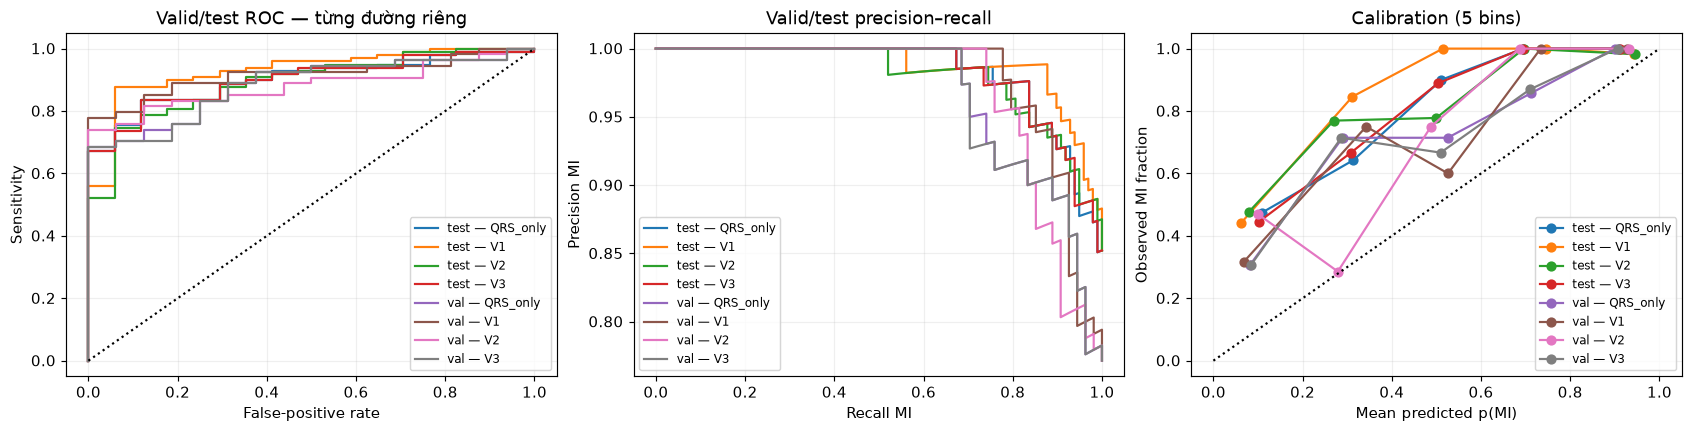

In [51]:
cx_ml_metrics=pd.DataFrame(); cx_ml_predictions=pd.DataFrame()
CX_ML_FEATURE_POLICY="valid"  # valid: candidate hợp lệ; accepted: mask T nếu chưa qua screening
if CX_RUN_ML:
    if not CX_RUN_COHORT or CX_SCOPE!="all" or CX_COHORT_LIMIT is not None:
        raise ValueError("ML cần full cohort: CX_RUN_COHORT=True, CX_SCOPE='all', CX_COHORT_LIMIT=None.")
    from sklearn.pipeline import make_pipeline
    from sklearn.impute import SimpleImputer
    from sklearn.preprocessing import StandardScaler
    from sklearn.linear_model import LogisticRegression
    from sklearn.metrics import (confusion_matrix,accuracy_score,balanced_accuracy_score,
        precision_score,recall_score,f1_score,matthews_corrcoef,roc_auc_score,
        average_precision_score,brier_score_loss,log_loss,roc_curve,precision_recall_curve)
    cx_assert_split(CX_SPLIT)
    metric_rows=[]; pred_rows=[]; ml_skipped=[]
    model_names=("QRS_only","V1","V2","V3")
    for method in model_names:
        source="V1" if method=="QRS_only" else method
        data=cx_cohort[cx_cohort.method.eq(source)].copy()
        if set(data.record_id)!=set(CX_SPLIT.record_id): raise ValueError("Cohort không phủ đúng manifest.")
        feats=[f for f in FEATURE_NAMES if f.startswith("QRS_")] if method=="QRS_only" else FEATURE_NAMES
        if method!="QRS_only" and CX_ML_FEATURE_POLICY=="accepted":
            data.loc[~data.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
        elif CX_ML_FEATURE_POLICY not in ("valid","accepted"): raise ValueError("Unknown ML feature policy.")
        train=data[data.split.eq("train")]
        assert set(train.patient_id).isdisjoint(set(data[data.split.isin(["val","test"])].patient_id))
        if train.label_name.nunique()!=2 or train[feats].isna().all().any():
            ml_skipped.append(dict(method=method,reason="train lacks two classes or all-missing feature column"));continue
        model=make_pipeline(SimpleImputer(strategy="median"),StandardScaler(),
            LogisticRegression(max_iter=3000,class_weight="balanced",random_state=2026))
        model.fit(train[feats],train.label_name.eq("MI").astype(int))
        for split in ("val","test"):
            part=data[data.split.eq(split)]
            if part.empty: continue
            prob=model.predict_proba(part[feats])[:,list(model.classes_).index(1)]
            for rid,pid,label,p in zip(part.record_id,part.patient_id,part.label_name,prob):
                pred_rows.append(dict(method=method,split=split,record_id=rid,patient_id=pid,
                                      y=int(label=="MI"),probability_mi=float(p)))
    cx_ml_predictions=pd.DataFrame(pred_rows)
    display(pd.DataFrame(ml_skipped))
    CX_RESULTS["ml_skipped"]=pd.DataFrame(ml_skipped)
    def classification_row(method,split,unit,g):
        y=g.y.to_numpy(); prob=g.probability_mi.to_numpy(); pred=(prob>=.5).astype(int)
        tn,fp,fn,tp=confusion_matrix(y,pred,labels=[0,1]).ravel()
        return dict(method=method,split=split,unit=unit,n=len(y),prevalence=float(y.mean()),
            tn=int(tn),fp=int(fp),fn=int(fn),tp=int(tp),accuracy=accuracy_score(y,pred),
            balanced_accuracy=balanced_accuracy_score(y,pred),sensitivity=tp/(tp+fn) if tp+fn else np.nan,
            specificity=tn/(tn+fp) if tn+fp else np.nan,precision=precision_score(y,pred,zero_division=0),
            f1=f1_score(y,pred,zero_division=0),mcc=matthews_corrcoef(y,pred),
            roc_auc=roc_auc_score(y,prob) if len(np.unique(y))==2 else np.nan,
            average_precision=average_precision_score(y,prob) if len(np.unique(y))==2 else np.nan,
            brier=brier_score_loss(y,prob),log_loss=log_loss(y,prob,labels=[0,1]))
    if not cx_ml_predictions.empty:
        for (m,s),g in cx_ml_predictions.groupby(["method","split"]):
            metric_rows.append(classification_row(m,s,"record",g))
            assert g.groupby("patient_id").y.nunique().max()==1
            patient=g.groupby("patient_id").agg(y=("y","first"),probability_mi=("probability_mi","mean")).reset_index()
            metric_rows.append(classification_row(m,s,"patient_mean_probability",patient))
        cx_ml_metrics=pd.DataFrame(metric_rows)
        display(cx_ml_metrics)
        fig,axes=plt.subplots(1,3,figsize=(16,4),layout="constrained")
        for (split,m),g in cx_ml_predictions.groupby(['split','method']):
            m=split+' — '+m
            if g.y.nunique()<2: continue
            fpr,tpr,_=roc_curve(g.y,g.probability_mi);precision,recall,_=precision_recall_curve(g.y,g.probability_mi)
            axes[0].plot(fpr,tpr,label=m);axes[1].plot(recall,precision,label=m)
            bins=pd.cut(g.probability_mi,np.linspace(0,1,6),include_lowest=True)
            calibration=g.groupby(bins,observed=True).agg(mean_probability=("probability_mi","mean"),
                observed_MI=("y","mean"),n=("y","size"))
            axes[2].plot(calibration.mean_probability,calibration.observed_MI,"o-",label=m)
        axes[0].plot([0,1],[0,1],"k:");axes[2].plot([0,1],[0,1],"k:")
        axes[0].set(xlabel="False-positive rate",ylabel="Sensitivity",title="Valid/test ROC — từng đường riêng")
        axes[1].set(xlabel="Recall MI",ylabel="Precision MI",title="Valid/test precision–recall")
        axes[2].set(xlabel="Mean predicted p(MI)",ylabel="Observed MI fraction",title="Calibration (5 bins)")
        for ax in axes:
            ax.grid(alpha=.2)
            if ax.has_data(): ax.legend(fontsize=8)
        cx_show(fig,"downstream_ML")
else: print("CX_RUN_ML=False; không train model hay đọc test để lựa chọn option.")
CX_RESULTS.update(ml_metrics=cx_ml_metrics,ml_predictions=cx_ml_predictions)

### Export và checklist đọc kết luận

Bật CX_SAVE_REPORTS để ghi CSV + config + fingerprint, selected manifest và review queue vào outputs/vcg_shared_comparison/<notebook>/<run_tag_protocol>. Các file được ghi khi bạn chạy cell này. Đổi CX_RUN_TAG để giữ lại lần chạy cũ. Tất cả bảng candidate giữ nguyên; accepted_features riêng sẽ mask T ở ca chưa accepted, giúp tránh dùng nhầm.

Review queue ưu tiên ca mất biên, nhiều flags và pairwise delta lớn; đó là danh sách kiểm tra bằng mắt, không phải expert labels. Template reference để trống, không sao chép prediction làm ground truth.

Nếu sau này có annotation độc lập, cần cùng beat, time origin, fs, reviewer và nguồn nhãn; khi đó mới tính MAE/RMSE/bias/tolerance accuracy của boundaries hoặc Se/PPV/F1 của event matching. Hiện tại các mục này là “chưa có reference”, không gán bằng 0.

**Cách kết luận:** xem failures/coverage theo MI/HC và split → paired delta/IoU → robustness và feature sensitivity → downstream task nếu bật → xem thủ công ca bất đồng. Coverage, loop closure hoặc agreement cao không đủ để xếp hạng độ đúng T. Các cờ method khác nhau về độ bảo thủ; đọc riêng common_flags và method_flags trước khi dùng accepted rate để so sánh.

In [52]:
cx_review=cx_eval[["record_id","patient_id","split","method","native_status","accepted","flags"]].copy()
if not cx_pair_details.empty:
    disagreement=cx_pair_details.assign(
        max_delta_ms=cx_pair_details[["on_delta_ms","off_delta_ms"]].abs().max(axis=1)
    ).groupby("record_id").max_delta_ms.max()
    cx_review=cx_review.merge(disagreement,on="record_id",how="left")
cx_review=cx_review.sort_values(["accepted","record_id"],ascending=[True,True])
display(cx_review.head(30))
cx_reference=CX_SPLIT[CX_SPLIT.record_id.isin(cx_eval.record_id)][["record_id","patient_id","split"]].copy()
cx_reference["time_reference"]="median_relative_ms"
for name in ("qrs_on_ms","qrs_off_ms","t_on_ms","t_off_ms","reviewer","reference_source"):
    cx_reference[name]=np.nan if name.endswith("_ms") else ""
cx_reference["independent_reference"]=False
CX_RESULTS.update(review_queue=cx_review,reference_template=cx_reference)
cx_packages={p:importlib.metadata.version(p) for p in ("numpy","scipy","pandas","matplotlib","wfdb","scikit-learn")}
if CX_SAVE_REPORTS:
    CX_OUT.mkdir(parents=True,exist_ok=True)
    for name,table in CX_RESULTS.items():
        if isinstance(table,pd.DataFrame): table.to_csv(CX_OUT/(name+".csv"),index=False)
    safe_features=cx_eval.copy()
    safe_features.loc[~safe_features.accepted,[f for f in FEATURE_NAMES if f.startswith("T_")]]=np.nan
    safe_features.to_csv(CX_OUT/"accepted_features.csv",index=False)
    (CX_OUT/"config.json").write_text(json.dumps(json_safe(dict(cx_config,
        protocol_id=CX_PROTOCOL_ID,packages=cx_packages,notebook=CX_NOTEBOOK,
        run_tag=CX_RUN_TAG,feature_policy=CX_ML_FEATURE_POLICY)),ensure_ascii=False,indent=2),encoding="utf-8")
    print("Saved:",CX_OUT)
else: print("Chỉ hiển thị. Bật CX_SAVE_REPORTS nếu muốn lưu bảng.")
print("Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.")
# Báo cáo riêng từng method, cùng schema và cùng split; không thay cohort theo ca thành công.
if CX_SAVE_REPORTS:
    for method in CX_METHODS:
        target=CX_OUT/'methods'/method;target.mkdir(parents=True,exist_ok=True)
        cx_eval[cx_eval.method.eq(method)].to_csv(target/'record_results.csv',index=False)
        cx_coverage[cx_coverage.method.eq(method)].to_csv(target/'summary_by_split.csv',index=False)
        cx_subgroups[cx_subgroups.method.eq(method)].to_csv(target/'summary_by_label_split.csv',index=False)
        for key in ('flags','stability_summary','beat_bootstrap_summary','sensitivity_scenarios','ml_metrics'):
            table=CX_RESULTS.get(key,pd.DataFrame())
            if not table.empty and 'method' in table:table[table.method.eq(method)].to_csv(target/(key+'.csv'),index=False)
    manifest_identity=hashlib.sha256(cx_selected.sort_values('record_id').to_csv(index=False).encode()).hexdigest()
    numeric_columns=['t_on_ms','t_off_ms','duration_ms','valid_pair','accepted',*FEATURE_NAMES]
    canonical=cx_eval.sort_values(['record_id','method']).set_index(['record_id','method'])[numeric_columns]
    manifest=dict(protocol_id=CX_PROTOCOL_ID,selected_manifest_sha256=manifest_identity,
        records=len(cx_selected),method_record_rows=len(cx_eval),focus_method=CX_FOCUS_METHOD,
        split_counts=cx_selected.groupby('split').size().to_dict(),cache=str(CX_CACHE),
        runtime_note='cached times originate from initial computation; not independent runtime benchmark',
        test_policy='fixed protocol only; option sweep restricted to train/val')
    (CX_OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    checks=[]
    for notebook in ('05_QRS_T_Loops_Step_by_Step','09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment','10_VCG_V3_Consensus_T_Delineation'):
        other=CX_ROOT/'outputs/vcg_shared_comparison'/notebook/(CX_RUN_TAG+'_'+CX_PROTOCOL_ID)
        if not (other/'run_manifest.json').is_file():
            checks.append(dict(notebook=notebook,status='chưa chạy/lưu cùng protocol'));continue
        saved=json.loads((other/'run_manifest.json').read_text(encoding='utf-8'))
        same_manifest=saved.get('selected_manifest_sha256')==manifest_identity
        table_path=other/'cohort.csv' if CX_RUN_COHORT else other/'demo_rows.csv'
        equal=False
        if same_manifest and table_path.is_file():
            prior=pd.read_csv(table_path).sort_values(['record_id','method']).set_index(['record_id','method'])[numeric_columns]
            equal=canonical.index.equals(prior.index) and np.allclose(canonical.to_numpy(dtype=float),prior.to_numpy(dtype=float),equal_nan=True,rtol=1e-9,atol=1e-10)
        checks.append(dict(notebook=notebook,same_manifest=same_manifest,same_numerical_results=equal,
                           status='OK' if same_manifest and equal else 'CẦN KIỂM TRA'))
    cx_cross_notebooks=pd.DataFrame(checks);display(cx_cross_notebooks)
    cx_cross_notebooks.to_csv(CX_OUT/'cross_notebook_checks.csv',index=False)
print('Báo cáo riêng notebook này:',CX_FOCUS_METHOD,'| đánh giá chung: V1/V2/C/V3; train/valid/test tách riêng.')


,record_id,patient_id,split,method,native_status,accepted,flags,max_delta_ms
12,patient001/s0010_re,patient001,train,V1,detected,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
13,patient001/s0010_re,patient001,train,V2,detected,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
14,patient001/s0010_re,patient001,train,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
15,patient001/s0010_re,patient001,train,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,45.0
36,patient001/s0014lre,patient001,train,V1,detected,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
37,patient001/s0014lre,patient001,train,V2,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
38,patient001/s0014lre,patient001,train,C,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
39,patient001/s0014lre,patient001,train,V3,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
60,patient001/s0016lre,patient001,train,V1,detected,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN
61,patient001/s0016lre,patient001,train,V2,unresolved,False,Các ngưỡng PSD/persistence/quiet là heuristic ...,NaN


Saved: C:\Users\tuyet\OneDrive\Máy tính\vcg\VCG\outputs\vcg_shared_comparison\05_QRS_T_Loops_Step_by_Step\full_cohort_01_59fcbe5ae8e1cc06
Không có T reference: chưa tính boundary accuracy, MAE/RMSE với truth hoặc QRS event Se/PPV.


,notebook,same_manifest,same_numerical_results,status
0,05_QRS_T_Loops_Step_by_Step,True,True,OK
1,09_VCG_T_Loop_Almeida_Wavelet_TLS_Experiment,NaN,NaN,chưa chạy/lưu cùng protocol
2,10_VCG_V3_Consensus_T_Delineation,True,True,OK


Báo cáo riêng notebook này: V1 | đánh giá chung: V1/V2/C/V3; train/valid/test tách riêng.
